# 한국어 대화 요약 (Korean Dialogue Summarization) — v8

**과제**: 카카오톡 기반 SNS 대화문 → **한 문장 요약문** 생성 (추상 요약)

| 항목 | 내용 |
|---|---|
| 데이터 | AI Hub 「한국어 대화 요약 데이터」 (㈜바이브컴퍼니, 총 35만 건) |
| 보유분 | Training 279,992건 / Validation 35,004건 (Test 스플릿 미배포 → 직접 분할) |
| 입력 | 화자 태그 대화문 (평균 11.3발화 / 5.8말차례 / 2.07명, 중앙값 163자) |
| 출력 | 한 문장 요약문 (평균 42자, "~한다/했다" 종결) |
| 모델 | KoBART (`gogamza/kobart-base-v2`, 124M) |
| 평가 | ROUGE-1/2/L + 부트스트랩 신뢰구간 + 사실성 대리 지표 |

---

## 실행 순서 (중요)

이 노트북은 **`cfg.smoke_test = True`** 로 시작합니다.
초소형 설정(2,000건 · 60 step)으로 전 구간이 오류 없이 도는지 3분 안에 확인하는 모드입니다.

```
1) 그대로 전 셀 실행 → 끝까지 돌면 파이프라인 정상
2) cfg.smoke_test = False → 커널 재시작 → §9 벤치마크로 실제 소요 시간 확인
3) batch_size 조정 후 본 학습 (train_subset=40,000 → 베이스라인)
4) train_subset=None (279,992건) → 최종 모델
```

---

## 이 데이터셋에 대해 먼저 알아야 할 것

실제 280,000건을 전수 분석한 결과입니다 (§4.1에서 직접 재현 가능).

**1. 이 데이터는 XSum보다 추상적입니다.**
요약문의 **신규 unigram 비율이 74~81%** 입니다. 가장 추상적인 영어 벤치마크로 알려진
XSum이 약 36%, CNN/DailyMail이 약 17%인 것과 비교하면 극단적으로 높습니다.
대화문을 아무리 잘 **추출**해도 상한(oracle)이 ROUGE-1 ≈ 25에 불과합니다.

> `[P1] 나왔당 ㅋ / [P2] 늦느줄알고 암것도안했는데ㅜㅜ / [P2] 애들도 지금 먹고있고`
> → **"오늘 퇴근이 늦을 줄 알고 가족들이 저녁을 먼저 먹었다."**
>
> 겹치는 단어가 거의 없습니다. 구어체를 문어체로 **다시 쓰는** 과제입니다.

**2. 그래서 ROUGE 절댓값이 낮게 나오는 것이 정상입니다.**
점수가 낮다고 모델이 잘못된 게 아닙니다. 판단 기준은 절댓값이 아니라
§7.1의 **노이즈 바닥**과 §4.1의 **추출 oracle 상한**입니다.

**3. 점수를 결정하는 것은 모델이 아니라 정답의 추상성입니다.**
건별 ROUGE와 대화 특성의 순위상관을 재면 **정답 요약의 추상성이 ρ≈−0.5로 지배적**이고,
발화 수·화자 수·대화 길이는 모두 |ρ|<0.1로 사실상 무관합니다 (§11.4).
추상성 85% 이상 구간(전체의 41%)에서는 ROUGE가 한 자리로 떨어집니다.
**그 구간의 품질은 ROUGE로 판단할 수 없고, §14 사람 평가가 필요합니다.**

**4. ROUGE 100은 목표가 아닙니다 — 사람끼리도 40 안팎입니다.**
315,000건에서 *사실상 같은 대화를 다른 작업자가 요약한* 쌍을 찾아 재보면
사람 vs 사람 ROUGE-1 이 word 37.7 / stem 41.4 / stemsub 39.4 입니다 (§7.1b, n 작음).
모델 점수는 100이 아니라 **이 값 대비 몇 %인지**로 읽어야 합니다.

**5. 데이터 자체는 깨끗합니다.** 전수 검사 결과 라벨 오류·중복·형식 이탈이 거의 없어
별도 필터링이 필요 없습니다 (§4.2).

---

## v8에서 추가된 것

| 영역 | 내용 |
|---|---|
| **§4.1 추상성 분석** | 신규 n-gram 비율, 추출 oracle 상한 — 성능 해석의 기준선 |
| **§4.2 데이터 품질 감사** | 라벨 오류·복사·길이 이상치 전수 검사 |
| **§7.2 부트스트랩 신뢰구간** | `R-L 18.3 ± 0.8` 형태로 보고. 평가셋 크기별 검출력 계산 |
| **§7.2 대응 유의성 검정** | 두 실험 차이가 우연인지 판정 (음성 대조군으로 검증됨) |
| **§11.3 공개 체크포인트 비교** | `digit82/kobart-summarization` 을 내 평가 코드로 직접 측정 |
| **§12.1 체크포인트 평균** | 마지막 N개 가중치 평균 — 재학습 없는 안정적 개선 |
| **§14 사람 평가 시트** | 채점 CSV 자동 생성 + ROUGE와의 순위상관(Spearman ρ) |
| **§3 경로 자동 해석** | 한글 파일명 NFD/NFC 불일치 대응 (실제로 발생하는 문제) |
| **§11.5 오차 요인 분석** | 무엇이 점수를 결정하는지 순위상관으로 규명 + 추상성 구간별 성능 |
| **§19 활용 방안** | 비즈니스 시나리오 4종·데이터 인사이트·정책 제안 5건 — 전부 측정값 근거 |
| **§19.6 배포 게이트** | 측정값으로 배포 가능 여부 자동 판정 (개인정보 누출은 타협 불가 항목) |
| **§19.7 서빙 비용** | 실측 처리량으로 규모별 소요 시간·비용 환산 |
| **§7.1b 사람 상한** | 같은 대화를 다른 작업자가 요약한 쌍을 315,000건에서 찾아 측정 — **사람끼리도 R-1 ≈ 40** |
| **§11.6 토론 탐지** | 토론 요약의 99.94%가 단일 틀. 과제는 형식이 아니라 탐지임을 정밀도/재현율로 측정 |
| **실제 학습 검증** | 12M 모델을 직접 학습시켜 전 구간을 실모델로 검증. 실측치는 §11.2 앞에 기록 |
| **추상성 주장 교정** | ρ≈−0.5 는 추출 베이스라인 기준이었음. 학습된 모델은 −0.17 (실측으로 정정) |
| **§7.3 자체 점검** | 43개 항목 자동 검증 — 실제로 화자번호·지표충돌 버그를 이 셀이 잡았습니다 |
| **§3.2 `stemsub` 지표** | 띄어쓰기에 강하고 변별력도 최고인 새 지표 (실측: 띄손실 0점, S/N 10.7) |
| **§11.4 가이드라인 적합성** | 2.4.2 규정 기반 **정답 없이 재는** 환각 탐지 지표 (무관 요약 0.1%로 식별) |
| **§18 다음 한 수 추천** | 내 실제 숫자를 읽고 지금 뭘 해야 이득인지 우선순위로 제시 |
| **§11 학습곡선 진단** | 과적합·미적합·발산·지표 불일치를 자동 판정 |
| **§13.1 시드 분산** | 학습 노이즈 집계 — 평가 노이즈(§7.2)와 별개로 반드시 필요 |
| **§12.3 배치 추론 · API** | 대량 예측 CSV + 가이드라인 2.6.2 규격 FastAPI 서버 자동 생성 |
| **§7.3 자체 점검** | 핵심 부품 40여 항목 자동 검증 — 실제로 아래 버그를 이 셀이 잡았습니다 |
| **화자 번호 버그 수정** | 첫 화자 발화가 전부 제거되면 대화가 `[P2]` 로 시작하던 문제 (실측 1.28%) |
| **§12.2 저장 왕복 검증** | 저장→재로드 후 출력이 같은지 확인 (화자 토큰·generation_config 유실 탐지) |
| **검증 손실 분리** | label smoothing 이 섞인 손실에 exp() 를 씌운 값은 perplexity 가 아님 (수정) |

## 학습 시간 단축 — 적용된 것

| # | 개선 | 효과 | 확인 |
|---|---|---|---|
| 1 | **길이 그룹 배칭** | 패딩 낭비 54.5% → 7.4%, **연산량 ≈ 절반** | §6에서 직접 측정 |
| 2 | **사전 토큰화 캐시** | 토크나이저를 학습 루프 밖으로 | §5 |
| 3 | **bf16 / SDPA / TF32** | Ampere+ 행렬연산 가속 | §1, §8 |
| 4 | **`max_input_len` 512 → 256** | 커버리지 표 기준 결정 | §5 |
| 5 | **처리량 벤치마크 + ETA** | 학습 전에 소요 시간 확인 | §9 |
| 6 | **배치 크기 자동 탐색** | OOM 직전까지 GPU 활용 | §9 |
| 7 | **step 기반 루프 + 중간 평가** | 에폭을 기다리지 않음 | §10 |
| 8 | **체크포인트 재개** | 커널이 죽어도 이어서 학습 | §10 |
| 9 | **Early stopping** | 정체된 학습 자동 중단 | §10 |
| 10 | **생성 평가 가속** | 모니터링 greedy, 최종만 beam | §10~11 |
| 11 | **smoke test 모드** | 본 학습 전 3분 검증 | §2 |

### 파이프라인
```
zip 해제 → JSON 파싱 → 마스킹 정규화 → 화자 태깅 → JSONL 캐시
  → 사전 토큰화 캐시 → 길이그룹 배칭 → KoBART 파인튜닝(AMP)
  → dev 중간 평가/체크포인트 → 디코딩 탐색(dev) → test 최종 평가 + 신뢰구간
  → 오차 분석 → 실험 기록
```

---
## 목차 · 어디부터 보면 되나

| § | 내용 | 대략 소요 | 건너뛰어도 되나 |
|---|---|---|---|
| 1~2 | 환경 설정, Config | 1분 | ❌ 필수 |
| 3 | 압축 해제 · 전처리 · **ROUGE 구현** | 최초 10분 (이후 캐시) | ❌ 필수 |
| 4 | EDA, **추상성 분석**, 품질 감사 | 3~5분 | ⭕ 보고서용 |
| 5 | 토크나이저 · 길이 결정 · 토큰 캐시 | 최초 5분 | ❌ 필수 |
| 6 | **길이그룹 배칭** + **§7.3 자체 점검** | 1분 | ❌ 필수 (점검 통과 후 학습) |
| 7 | **지표 보정 · 신뢰구간 · §7.3 자체 점검** | 2분 | ❌ 점검은 필수 |
| 8~9 | 모델 로드, **처리량 벤치마크** | 2분 | ❌ 필수 |
| 10 | 학습 | smoke 3분 / 본 학습 수 시간 | ❌ 필수 |
| 11 | 디코딩 탐색, 최종 평가, 적합성, 오차 요인 | 10~20분 | ⭕ 보고서용 |
| 12 | 저장, 체크포인트 평균, 배치추론·API | 5분 | ⭕ |
| 13~14 | 실험 기록, 시드 분산, 사람 평가 시트 | 1분 | ⭕ 보고서용 |
| 15~16 | 로드맵, 문제 해결 | — | 읽기용 |
| 17~18 | **보고서 자동 생성**, **내 결과 기준 다음 한 수** | 1분 | ⭕ 강력 권장 |
| 19 | **활용 방안** — 비즈니스·인사이트·정책·배포 게이트·서빙 비용 | 2분 | ⭕ 보고서용 |

**처음이라면**: 위에서 아래로 그냥 전부 실행하세요 (`smoke_test=True` 라 3분이면 끝납니다).
**시간이 없다면**: 1·2·3·5·6·8·9·10만 돌리면 모델은 나옵니다. 나머지는 보고서를 위한 분석입니다.

---
## 1. 환경 설정 & 속도 스위치

In [1]:
# 최초 1회만 (PyTorch는 본인 CUDA 버전에 맞춰 https://pytorch.org 에서 설치)
# !pip install torch --index-url https://download.pytorch.org/whl/cu121
# !pip install "transformers>=4.40" sentencepiece protobuf pandas matplotlib tqdm

In [2]:
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")   # fast tokenizer 병렬 인코딩

import re, gc, sys, json, math, time, random, shutil, pickle, zipfile, unicodedata, collections
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Sampler
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import transformers
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

print("torch       :", torch.__version__)
print("transformers:", transformers.__version__)

def _ver(s):                                   # "4.41.2" → (4, 41, 2)
    return tuple(int(x) for x in re.findall(r"\d+", s)[:3])

if _ver(transformers.__version__) < (4, 40):
    print("⚠ transformers 4.40 미만입니다. `pip install -U \"transformers>=4.40\"` 를 권장합니다.")
    print("  (4.36 미만이면 attn_implementation='sdpa' 가 동작하지 않습니다)")
if _ver(torch.__version__) < (2, 1):
    print("⚠ torch 2.1 미만입니다. SDPA / torch.amp API 가 제한될 수 있습니다.")

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

# ---------- 속도 스위치 ----------
BF16_OK = False
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True     # Ampere+ 에서 fp32 행렬곱을 TF32로
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True            # 입력 크기가 반복되면 최적 커널 캐싱
    try:
        torch.set_float32_matmul_precision("high")
    except Exception:
        pass
    BF16_OK = torch.cuda.is_bf16_supported()         # RTX 30/40, A100 등
    p = torch.cuda.get_device_properties(0)
    print(f"GPU         : {p.name}  {p.total_memory/1e9:.1f}GB  SM{p.major}.{p.minor}")
    print(f"bf16 지원   : {BF16_OK}  (True면 GradScaler 없이 안전하게 학습 가능)")
else:
    print("⚠ GPU가 없습니다. CPU 학습은 매우 느리므로 train_subset을 2,000 이하로 줄이세요.")

print("device      :", DEVICE)

# 한글 폰트
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; print("한글 폰트   :", _f); break
else:
    print("⚠ 한글 폰트 없음 → 그래프 한글이 □ 로 보일 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False

torch       : 2.7.1+cu128
transformers: 4.44.2
GPU         : NVIDIA GeForce RTX 5070 Laptop GPU  8.5GB  SM12.0
bf16 지원   : True  (True면 GradScaler 없이 안전하게 학습 가능)
device      : cuda
한글 폰트   : Malgun Gothic


## 2. 설정 (Config)

**한 번에 다 돌리려 하지 마세요.** 권장 순서는 다음과 같습니다.

1. `train_subset=20000`, `max_steps=800` → 파이프라인이 끝까지 도는지 확인 (수 분)
2. §9 벤치마크로 실제 처리량·ETA 확인 → `batch_size` 조정
3. `train_subset=40000`, `max_steps=None`, `epochs=3` → 베이스라인 확보
4. `train_subset=None` (28만 건 전체) → 최종 모델

In [3]:
@dataclass
class CFG:
    # ---- 경로 ----
    raw_zip: str = "한국어_대화_요약.zip"
    work_dir: str = "./work"
    out_dir: str = "./outputs"

    # ---- 모델 ----
    model_name: str = "gogamza/kobart-base-v2"
    # 대안: "digit82/kobart-summarization" (동일 데이터 학습본 → 워밍스타트)
    #       "paust/pko-t5-base"            (T5 계열, 코드 수정 없이 동작)
    add_speaker_tokens: bool = True
    use_sdpa: bool = True            # scaled_dot_product_attention 커널 사용
    use_topic_prefix: bool = False   # 입력 앞에 "[식음료] " 처럼 주제를 붙여 조건부 생성
    topic_prefix_dropout: float = 0.3  # 학습 때 이 확률로 주제를 생략 → 서빙 때 주제가 없어도 동작

    # ---- 길이 (§5 커버리지 표를 보고 조정) ----
    max_input_len: int = 256         # v1의 512에서 하향. 커버리지 99%+ 확인 후 사용
    max_target_len: int = 80

    # ---- 데이터 크기 ----
    train_subset: Optional[int] = 40_000   # None → 전체 279,992건
    dev_ratio: float = 0.5                 # Validation을 dev(모델선택) / test(최종보고)로 분할
    valid_subset: int = 2_000              # loss 계산용 (dev에서 추출)
    eval_gen_subset: int = 400             # 중간 ROUGE 모니터링용 (생성은 느림)
    final_eval_size: int = 1_000           # 최종 평가용

    # ---- 학습 ----
    batch_size: int = 32
    eval_batch_size: int = 64
    grad_accum: int = 1
    epochs: int = 3
    max_steps: Optional[int] = None        # 설정하면 epochs보다 우선 (시간 제한용)
    lr: float = 5e-5
    weight_decay: float = 0.01
    warmup_ratio: float = 0.06
    max_grad_norm: float = 1.0
    label_smoothing: float = 0.1

    # ---- 정밀도 ----
    amp: bool = True
    prefer_bf16: bool = True         # bf16 가능하면 bf16 (GradScaler 불필요)

    # ---- 배칭 ----
    group_by_length: bool = True     # ★ 가장 큰 속도 개선
    mega_batch: int = 50             # 길이 정렬 단위 = batch_size * mega_batch
    pad_multiple: int = 8            # Tensor Core 정렬

    # ---- 평가/체크포인트 ----
    eval_every_steps: int = 500      # 중간 평가 주기 (에폭을 기다리지 않음)
    eval_num_beams: int = 1          # 모니터링은 greedy(빠름)
    final_num_beams: int = 4         # 최종 평가만 beam search
    early_stopping_patience: int = 3 # 평가 n회 연속 개선 없으면 중단
    resume: bool = True              # last.pt 있으면 이어서 학습
    keep_last_ckpts: int = 3         # 체크포인트 평균용 (0=끔). KoBART 기준 1개당 ~0.5GB
    save_last: bool = True           # optimizer 상태 포함 저장 (~1.5GB, 재개용)

    # ---- 생성 ----
    no_repeat_ngram_size: int = 3
    length_penalty: float = 1.0
    repetition_penalty: float = 1.0   # 1.0=미적용. 반복 생성이 보이면 1.1~1.3
    min_gen_len: int = 8

    # ---- 지표 ----
    select_metric: str = "stemsub"    # 체크포인트 선택 기준 (word / stem / char / stemsub)
                                      # stemsub: 띄어쓰기에 강하고 변별력도 최고 (§7.1 실측)

    grad_checkpoint: bool = False     # VRAM 부족할 때만 (속도 20~30% 손해, 배치는 2배 가능)
    smoke_test: bool = True           # ★ True면 초소형 설정으로 파이프라인만 3분 내 검증
    seed: int = 42
    deterministic: bool = False       # 완전 재현 모드 (20~30% 느려짐). 시드 분산 실험 때만 권장
    num_workers: int = 0 if os.name == "nt" else 4

cfg = CFG()

if cfg.smoke_test:
    # 전체 경로가 오류 없이 도는지 먼저 확인하는 모드.
    # 여기서 끝까지 돌아가면 아래 두 줄을 끄고 본 학습을 시작하세요.
    cfg.train_subset, cfg.valid_subset = 2_000, 300
    cfg.eval_gen_subset, cfg.final_eval_size = 50, 100
    cfg.max_steps, cfg.eval_every_steps, cfg.epochs = 60, 30, 1
    cfg.early_stopping_patience = 99
    print("🔍 SMOKE TEST 모드 — 파이프라인 검증용 초소형 설정")
    print("   정상 완료되면 cfg.smoke_test = False 로 바꾸고 커널 재시작 후 본 학습\n")
for d in (cfg.work_dir, cfg.out_dir):
    Path(d).mkdir(parents=True, exist_ok=True)

def set_seed(s, deterministic=False):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
    if deterministic:
        # 완전 재현이 필요할 때만. cudnn.benchmark 와 상충하고 20~30% 느려집니다.
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        try: torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception: pass

set_seed(cfg.seed, deterministic=cfg.deterministic)

USE_AMP   = cfg.amp and DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and cfg.prefer_bf16 and BF16_OK) else torch.float16
NEED_SCALER = USE_AMP and AMP_DTYPE == torch.float16   # bf16은 스케일러 불필요

print(f"AMP={USE_AMP} dtype={AMP_DTYPE} scaler={NEED_SCALER}")
print(f"길이그룹배칭={cfg.group_by_length} | 유효배치={cfg.batch_size*cfg.grad_accum}")

🔍 SMOKE TEST 모드 — 파이프라인 검증용 초소형 설정
   정상 완료되면 cfg.smoke_test = False 로 바꾸고 커널 재시작 후 본 학습

AMP=True dtype=torch.bfloat16 scaler=False
길이그룹배칭=True | 유효배치=32


---
## 3. 데이터 준비

원본 zip은 **이중 압축**이고, 바깥쪽은 macOS에서 만들어져 한글 파일명이
**NFD(자모 분리) + 비UTF8 플래그**로 저장돼 있습니다.
`extractall()` 을 그냥 쓰면 Windows에서 `ﾃﾅﾄ…` 같은 깨진 폴더가 생깁니다.

In [7]:
def _safe_name(info: zipfile.ZipInfo) -> str:
    name = info.filename
    if not (info.flag_bits & 0x800):                 # UTF-8 플래그 없음 → cp437 로 디코딩돼 있음
        raw = name.encode("cp437", "replace")
        for enc in ("utf-8", "cp949", "euc-kr"):
            try:
                name = raw.decode(enc); break
            except UnicodeDecodeError:
                continue
    return unicodedata.normalize("NFC", name)        # NFD → NFC

def extract_zip(zip_path, out_dir) -> list:
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    written = []
    with zipfile.ZipFile(zip_path) as z:
        for info in z.infolist():
            name = _safe_name(info)
            if name.startswith("__MACOSX/") or "/._" in name or name.startswith("._"):
                continue
            target = out_dir / name
            if info.is_dir():
                target.mkdir(parents=True, exist_ok=True); continue
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists() or target.stat().st_size != info.file_size:
                with z.open(info) as src, open(target, "wb") as dst:
                    shutil.copyfileobj(src, dst)
            written.append(target)
    return written

def resolve_path(path):
    """한글 파일명은 자모 분리(NFD)로 저장돼 있을 수 있습니다.
    파이썬 문자열 리터럴은 보통 완성형(NFC)이라 `open()` 이 실패합니다.
    (macOS에서 만든 zip을 Linux/WSL에서 다룰 때 실제로 발생)"""
    p = Path(path)
    if p.exists(): return str(p)
    d = p.parent if str(p.parent) else Path(".")
    want = unicodedata.normalize("NFC", p.name)
    if d.exists():
        for f in d.iterdir():
            if unicodedata.normalize("NFC", f.name) == want:
                print(f"[경로 보정] {p.name} → {f.name}")
                return str(f)
    raise FileNotFoundError(
        f"{path} 를 찾을 수 없습니다.\n"
        f"  - cfg.raw_zip 경로를 확인하세요 (현재 작업 폴더: {Path.cwd()})\n"
        f"  - {d} 안의 파일: {[f.name for f in d.iterdir()][:10] if d.exists() else '(폴더 없음)'}")


RAW_ROOT = Path(cfg.work_dir) / "raw"
inner = extract_zip(resolve_path(cfg.raw_zip), RAW_ROOT)
for z in inner:
    extract_zip(z, RAW_ROOT / ("train" if "train" in z.stem else "valid"))

for split in ("train", "valid"):
    fs = sorted((RAW_ROOT / split).rglob("*.json"))
    print(f"[{split}] json {len(fs)}개  총 {sum(f.stat().st_size for f in fs)/1e6:,.0f} MB")

[train] json 9개  총 994 MB
[valid] json 9개  총 124 MB


### 3.1 전처리

**비식별화 플레이스홀더** (valid 기준 실측 빈도)

| 토큰 | 빈도 | 처리 |
|---|---|---|
| `#@이름#` | 10,860 | `[이름]` 치환 |
| `#@시스템#사진#` / `검색` / `동영상` / `송금` … | 5,200+ | **삭제** (텍스트 정보 없음) |
| `#@이모티콘#…#` | 2,900+ | **삭제** |
| `#@기타#` (욕설 마스킹) | 1,907 | **삭제** |
| `#@URL#` `#@소속#` `#@주소#` `#@계정#` `#@금융#` … | 1,000+ | `[링크]` `[소속]` … 치환 |

`#@시스템#사진#` 처럼 **2단 구조**가 있어서 단순 `#@\w+#` 정규식으로는 `사진#` 찌꺼기가 남습니다.

**화자 재매핑** — 원본 ID는 같은 2인 대화라도 `P01/P02`이거나 `P03/P07`입니다.
등장 순서 기준 `[P1] [P2]`로 정규화해야 모델이 헷갈리지 않습니다.

In [8]:
RE_SYSTEM   = re.compile(r"#@시스템#[^#\s]*#?")
RE_EMOTICON = re.compile(r"#@이모티콘#[^#\s]*#?")
RE_GENERIC  = re.compile(r"#@([^#\s]+)#")
RE_LAUGH    = re.compile(r"([ㄱ-ㅎㅏ-ㅣ])\1{2,}")
RE_REPEAT   = re.compile(r"([!?~.,ㅠㅜ])\1{2,}")
RE_SPACE    = re.compile(r"[ \t]+")

PLACEHOLDER_MAP = {"이름": "[이름]", "URL": "[링크]", "소속": "[소속]", "주소": "[주소]",
                   "계정": "[계정]", "금융": "[번호]", "번호": "[번호]", "전번": "[번호]",
                   "신원": "[번호]", "기타": ""}

def clean_utterance(text: str) -> str:
    text = RE_SYSTEM.sub("", text)
    text = RE_EMOTICON.sub("", text)
    text = RE_GENERIC.sub(lambda m: PLACEHOLDER_MAP.get(m.group(1), "[기타]"), text)
    text = text.replace("#", " ")
    text = RE_LAUGH.sub(r"\1\1", text)
    text = RE_REPEAT.sub(r"\1\1", text)
    return RE_SPACE.sub(" ", text).strip()

PREP_VERSION = 3      # 전처리/캐시 스키마를 고치면 올리세요. §5 토큰 캐시가 자동 무효화됩니다.
                      # v3: §19 인사이트용 타임스탬프·인구통계 필드 추가

def build_dialogue_text(dialogue: list) -> str:
    """화자를 '살아남은 발화' 기준 등장순으로 [P1], [P2] … 재매핑.

    주의: 번호를 먼저 매기고 나중에 빈 발화를 버리면, 첫 화자의 발화가 전부
    이모티콘/시스템 메시지였을 때 대화가 [P2] 로 시작합니다.
    실측 결과 전체의 **1.28%** 에서 발생했습니다 (나머지 98.7%는 [P1] 시작).
    학습 데이터에 이런 불일치가 섞이면 화자 토큰의 의미가 흐려지므로,
    정제 후 텍스트가 남은 발화에만 번호를 부여합니다."""
    pid2idx, lines = {}, []
    for u in dialogue:
        t = clean_utterance(u["utterance"])
        if not t:
            continue
        pid = u["participantID"]
        if pid not in pid2idx:
            pid2idx[pid] = len(pid2idx) + 1
        lines.append(f"[P{min(pid2idx[pid], 8)}] {t}")
    return "\n".join(lines)

# 첫 화자의 발화가 전부 제거되는 경우 → [P1] 부터 시작해야 정상
print(build_dialogue_text([
    {"participantID": "Z", "utterance": "#@이모티콘#"},
    {"participantID": "Y", "utterance": "이게 첫 발화가 됩니다"},
]))
print("---")
print(build_dialogue_text([
    {"participantID": "P03", "utterance": "#@이름#아 내일 뭐해?? ㅋㅋㅋㅋㅋㅋ"},
    {"participantID": "P07", "utterance": "#@시스템#사진#"},
    {"participantID": "P07", "utterance": "이거 어때 #@URL# 여기 #@주소#로 가면 돼!!!!!"},
    {"participantID": "P03", "utterance": "#@이모티콘#하트뿅#"},
]))

[P1] 이게 첫 발화가 됩니다
---
[P1] [이름]아 내일 뭐해?? ㅋㅋ
[P2] 이거 어때 [링크] 여기 [주소]로 가면 돼!!


### 3.2 텍스트 토크나이저와 ROUGE 구현

영어용 `rouge_score`는 Porter stemmer와 공백 토크나이저를 쓰므로 한국어에 그대로 쓰면 안 됩니다.
직접 구현하고 토크나이저를 교체 가능하게 만듭니다. **§4 EDA부터 §11 최종 평가까지 계속 씁니다.**

| 모드 | 방식 | 특징 |
|---|---|---|
| `word` | 어절 그대로 | 가장 엄격. `곱창을` ≠ `곱창` |
| `stem` | **조사만 제거** | JDK 불필요. 어간이 2음절 이상일 때만 절단 ← **기본값** |
| `char` | 음절 단위 | 점수가 높게 나오지만 변별력이 낮음 (§7.1) |
| `morph` | `konlpy` 형태소 | 가장 타당하나 Windows 설치가 번거로움 |

`stem`은 어미(`했다`, `한다고`)는 건드리지 않습니다. 어미까지 자르면 `하였다`→`하`,
`한다고`→`한` 처럼 서로 다른 말이 뭉개져 오히려 변별력이 떨어집니다 (§7.1에서 수치 확인).

In [9]:
# 이 셀의 함수들은 §4 EDA(추상성 분석)부터 §11 평가까지 전 구간에서 사용됩니다.
RE_LEAK = re.compile(r"\[(?:이름|링크|소속|주소|계정|번호|기타)\]")   # 마스킹 토큰 탐지
RE_WORD = re.compile(r"[가-힣]+|[a-zA-Z]+|[0-9]+")
def tok_word(t): return RE_WORD.findall(t)
def tok_char(t): return list(re.sub(r"\s+", "", t))

# --- 조사만 제거하는 경량 어간 추출 (JDK/konlpy 불필요) ---
JOSA = sorted(["으로써","으로서","이라고","이라는","에게서","에서는","에게도","에게","한테서","한테",
               "부터","까지","처럼","보다","이나","이랑","으로","에서","에는","에도","라고","과는","와는",
               "의","은","는","이","가","을","를","과","와","도","만","랑","로","께","야","아","나"],
              key=len, reverse=True)
MIN_STEM = 2          # 어간이 2음절 미만이 되면 자르지 않음 (과다 절단 방지)

def tok_stem(t):
    out = []
    for w in tok_word(t):
        if len(w) >= 2:
            for s in JOSA:
                if len(s) < len(w) and w.endswith(s) and len(w) - len(s) >= MIN_STEM:
                    w = w[: len(w) - len(s)]
                    break
        out.append(w)
    return out

_morph = None
def tok_morph(t):
    global _morph
    if _morph is None:
        from konlpy.tag import Okt        # pip install konlpy (JDK 필요)
        _morph = Okt()
    return _morph.morphs(t)

TOKENIZERS = {"word": tok_word, "stem": tok_stem, "char": tok_char, "morph": tok_morph}

# 보고·기록에 함께 쓰는 지표 집합과 컬럼 약어 (stem 과 stemsub 가 겹치지 않도록 명시)
METRIC_SET  = ("word", "stem", "char", "stemsub")
METRIC_ABBR = {"word": "w", "stem": "s", "char": "c", "stemsub": "ss", "morph": "m"}

# --- stemsub: 어간을 '공백 제거한 문자열 위의 부분문자열'로 매칭 ---
#     한국어는 띄어쓰기가 흔들려도 의미가 같습니다("먹기로 했다" = "먹기로했다").
#     어절 기반 지표는 이때 점수를 크게 잃는데(§7.1에서 실측), 이 방식은 영향을 받지 않습니다.
STEMSUB_MIN_LEN = 2          # 1글자 어간은 우연 일치가 많아 제외

def _stemsub_f1(pred, ref):
    sp = {t for t in tok_stem(pred) if len(t) >= STEMSUB_MIN_LEN}
    sr = {t for t in tok_stem(ref)  if len(t) >= STEMSUB_MIN_LEN}
    if not sp or not sr:
        return 0.0
    fp, fr = re.sub(r"\s+", "", pred), re.sub(r"\s+", "", ref)
    p = sum(1 for t in sp if t in fr) / len(sp)      # 예측 어간이 정답에 있나
    r = sum(1 for t in sr if t in fp) / len(sr)      # 정답 어간이 예측에 있나
    return 0.0 if (p + r) == 0 else 2 * p * r / (p + r)

def _ngrams(x, n): return collections.Counter(tuple(x[i:i+n]) for i in range(len(x)-n+1))
def _f1(m, np_, nr):
    if m == 0 or np_ == 0 or nr == 0: return 0.0
    p, r = m/np_, m/nr
    return 2*p*r/(p+r)
def _rouge_n(p, r, n):
    cp, cr = _ngrams(p, n), _ngrams(r, n)
    return _f1(sum((cp & cr).values()), sum(cp.values()), sum(cr.values()))
def _lcs(a, b):
    prev = [0]*(len(b)+1)
    for x in a:
        cur = [0]*(len(b)+1)
        for j, y in enumerate(b, 1):
            cur[j] = prev[j-1]+1 if x == y else max(prev[j], cur[j-1])
        prev = cur
    return prev[-1]
def _rouge_l(p, r): return _f1(_lcs(p, r), len(p), len(r))

def compute_rouge(preds, refs, mode="word"):
    if mode == "stemsub":        # 토큰 n-gram 이 아니라 집합 기반이라 R-1/R-L 이 동일합니다
        v = 100 * float(np.mean([_stemsub_f1(p, r) for p, r in zip(preds, refs)])) if preds else 0.0
        return {"rouge1": round(v, 2), "rouge2": round(v, 2), "rougeL": round(v, 2)}
    tok, acc = TOKENIZERS[mode], collections.defaultdict(float)
    for p, r in zip(preds, refs):
        tp, tr = tok(p), tok(r)
        acc["rouge1"] += _rouge_n(tp, tr, 1)
        acc["rouge2"] += _rouge_n(tp, tr, 2)
        acc["rougeL"] += _rouge_l(tp, tr)
    n = max(len(preds), 1)
    return {k: round(100*v/n, 2) for k, v in acc.items()}

print("어간 추출 예:", tok_stem("친구들과 곱창을 먹기로 했다고 사람이 말한다"))
print("띄어쓰기 내성:",
      "stem", compute_rouge(["오늘저녁에 곱창을먹기로했다."], ["오늘 저녁에 곱창을 먹기로 했다."], "stem")["rouge1"],
      "/ stemsub", compute_rouge(["오늘저녁에 곱창을먹기로했다."], ["오늘 저녁에 곱창을 먹기로 했다."], "stemsub")["rouge1"])

ref = ["오늘 저녁에 친구들과 곱창을 먹기로 했다."]
for m in ("word", "stem", "char"):
    print(f"[{m:4s}] 완전일치 {compute_rouge(ref, ref, m)} | "
          f"부분일치 {compute_rouge(['저녁에 곱창을 먹는다.'], ref, m)} | "
          f"무관 {compute_rouge(['내일 회의 일정을 정한다.'], ref, m)}")

어간 추출 예: ['친구들', '곱창', '먹기', '했다고', '사람', '말한다']
띄어쓰기 내성: stem 0.0 / stemsub 100.0
[word] 완전일치 {'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0} | 부분일치 {'rouge1': 44.44, 'rouge2': 0.0, 'rougeL': 44.44} | 무관 {'rouge1': 0.0, 'rouge2': 0.0, 'rougeL': 0.0}
[stem] 완전일치 {'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0} | 부분일치 {'rouge1': 44.44, 'rouge2': 0.0, 'rougeL': 44.44} | 무관 {'rouge1': 0.0, 'rouge2': 0.0, 'rougeL': 0.0}
[char] 완전일치 {'rouge1': 100.0, 'rouge2': 100.0, 'rougeL': 100.0} | 부분일치 {'rouge1': 64.29, 'rouge2': 46.15, 'rougeL': 64.29} | 무관 {'rouge1': 20.69, 'rouge2': 7.41, 'rougeL': 20.69}


In [10]:
def json_to_jsonl(src_dir, out_path, verbose=True):
    """주제별 대용량 json(최대 250MB)을 한 파일씩 처리해 필요한 필드만 jsonl 캐싱."""
    out_path = Path(out_path)
    if out_path.exists():
        if verbose: print(f"캐시 재사용: {out_path.name}")
        return out_path
    n = 0
    with open(out_path, "w", encoding="utf-8") as fo:
        for p in sorted(Path(src_dir).rglob("*.json")):
            data = json.load(open(p, encoding="utf-8"))["data"]
            for it in data:
                di = it["header"]["dialogueInfo"]
                d0 = it["body"]["dialogue"][0] if it["body"]["dialogue"] else {}
                pi = it["header"].get("participantsInfo", [])
                fo.write(json.dumps({
                    "id": di["dialogueID"], "topic": di["topic"], "type": di["type"],
                    "n_utt": di["numberOfUtterances"], "n_turn": di["numberOfTurns"],
                    "n_part": di["numberOfParticipants"],
                    # §19 인사이트 분석용 메타데이터 (모델 입력에는 쓰지 않습니다)
                    "date": d0.get("date", ""), "time": d0.get("time", ""),
                    "genders": [p.get("gender") for p in pi],
                    "ages": [p.get("age") for p in pi],
                    "provinces": [p.get("residentialProvince") for p in pi],
                    "dialogue": build_dialogue_text(it["body"]["dialogue"]),
                    "summary": it["body"]["summary"].strip(),
                }, ensure_ascii=False) + "\n")
            n += len(data)
            if verbose: print(f"  {p.name:<20s} {len(data):>7,}건")
            del data; gc.collect()
    if verbose: print(f"→ 총 {n:,}건")
    return out_path

t0 = time.time()
TRAIN_JSONL = json_to_jsonl(RAW_ROOT / "train", Path(cfg.work_dir) / f"train_v{PREP_VERSION}.jsonl")
VALID_JSONL = json_to_jsonl(RAW_ROOT / "valid", Path(cfg.work_dir) / f"valid_v{PREP_VERSION}.jsonl")

def load_jsonl(path):
    return pd.DataFrame([json.loads(l) for l in open(path, encoding="utf-8")])

train_df = load_jsonl(TRAIN_JSONL)
valid_df = load_jsonl(VALID_JSONL)
print(f"train {train_df.shape} / valid {valid_df.shape}  ({time.time()-t0:.0f}s)")
train_df.head(3)

  개인및관계.json            71,130건
  미용과건강.json            17,069건
  상거래(쇼핑).json          26,298건
  시사교육.json             13,119건
  식음료.json              30,184건
  여가생활.json             35,247건
  일과직업.json             20,428건
  주거와생활.json            45,179건
  행사.json               21,338건
→ 총 279,992건
  개인및관계.json             8,892건
  미용과건강.json             2,134건
  상거래(쇼핑).json           3,288건
  시사교육.json              1,640건
  식음료.json               3,773건
  여가생활.json              4,407건
  일과직업.json              2,554건
  주거와생활.json             5,648건
  행사.json                2,668건
→ 총 35,004건
train (279992, 13) / valid (35004, 13)  (39s)


,id,topic,type,n_utt,n_turn,n_part,date,time,genders,ages,provinces,dialogue,summary
0,451a86a0-a699-5c49-9370-e1d79ea63506,개인 및 관계,일상 대화,20,8,2,2020-06-01,08:08:00,"[여성, 여성]","[20대, 20대]","[인천광역시, 인천광역시]",[P1] 우리 기간 언제까지나고 물어볼 수 없어\n[P1] 재등록 할 줄 알면 어케...,아저씨가 재등록에 관하여 물어보면 다음 달은 바빠서 어려울 것 같고 다음에 다시 오...
1,79643c13-82b6-52fd-b780-e9aa1c86bbf8,개인 및 관계,일상 대화,9,6,2,2020-10-18,12:13:00,"[남성, 여성]","[20대, 20대]","[서울특별시, 경기도]",[P1] 아침\n[P2] 헉\n[P1] 잘안먹구\n[P2] 일찍\n[P2] 인나짜나...,일찍 일어났지만 아침을 원래 잘 챙겨 먹지 않아서 아침 겸 점심(아점)을 먹을 예정이다.
2,0c176655-d84a-5c1f-be6b-1aa3a47aa79c,개인 및 관계,일상 대화,10,5,2,2018-07-20,00:52:00,"[여성, 여성]","[20대, 20대]","[인천광역시, 인천광역시]",[P1] 18년도 잘한 일임니다\n[P2] 넘나\n[P2] 레전급여행\n[P2] 개...,18년도의 잘한 일이고 전설급 여행이었다며 뿌듯해하고 가을 남해에 꼭 다시 가자고 한다.


---
## 4. EDA

In [11]:
def describe_split(df, name):
    print(f"===== {name}: {len(df):,}건 =====")
    t = df["topic"].value_counts()
    print(pd.DataFrame({"건수": t, "비율(%)": (100*t/len(df)).round(2)}).to_string())
    y = df["type"].value_counts()
    print("\n" + pd.DataFrame({"건수": y, "비율(%)": (100*y/len(df)).round(2)}).to_string())
    L = pd.DataFrame({"대화(자)": df["dialogue"].str.len(), "요약(자)": df["summary"].str.len()})
    print("\n" + L.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string(), "\n")

describe_split(train_df, "Training")
describe_split(valid_df, "Validation")
print("train/valid ID 중복:", len(set(train_df.id) & set(valid_df.id)))
print("요약문 완전중복    :", train_df.summary.duplicated().sum())
print("압축률(요약/대화)  :", round((valid_df.summary.str.len()/valid_df.dialogue.str.len()).mean(), 3))

===== Training: 279,992건 =====
            건수  비율(%)
topic                
개인 및 관계  71130  25.40
주거와 생활   45179  16.14
여가 생활    35247  12.59
식음료      30184  10.78
상거래(쇼핑)  26298   9.39
행사       21338   7.62
일과 직업    20428   7.30
미용과 건강   17069   6.10
시사/교육    13119   4.69

           건수  비율(%)
type                
일상 대화  278384  99.43
토론 대화    1608   0.57

          대화(자)     요약(자)
count  279992.0  279992.0
mean      176.5      42.0
std        65.6      14.1
min        50.0      14.0
50%       163.0      40.0
90%       256.0      62.0
95%       298.0      69.0
99%       407.0      77.0
max      2023.0     174.0 

===== Validation: 35,004건 =====
           건수  비율(%)
topic               
개인 및 관계  8892  25.40
주거와 생활   5648  16.14
여가 생활    4407  12.59
식음료      3773  10.78
상거래(쇼핑)  3288   9.39
행사       2668   7.62
일과 직업    2554   7.30
미용과 건강   2134   6.10
시사/교육    1640   4.69

          건수  비율(%)
type               
일상 대화  34816  99.46
토론 대화    188   0.54

         대화(자)    요약(자)
count  350

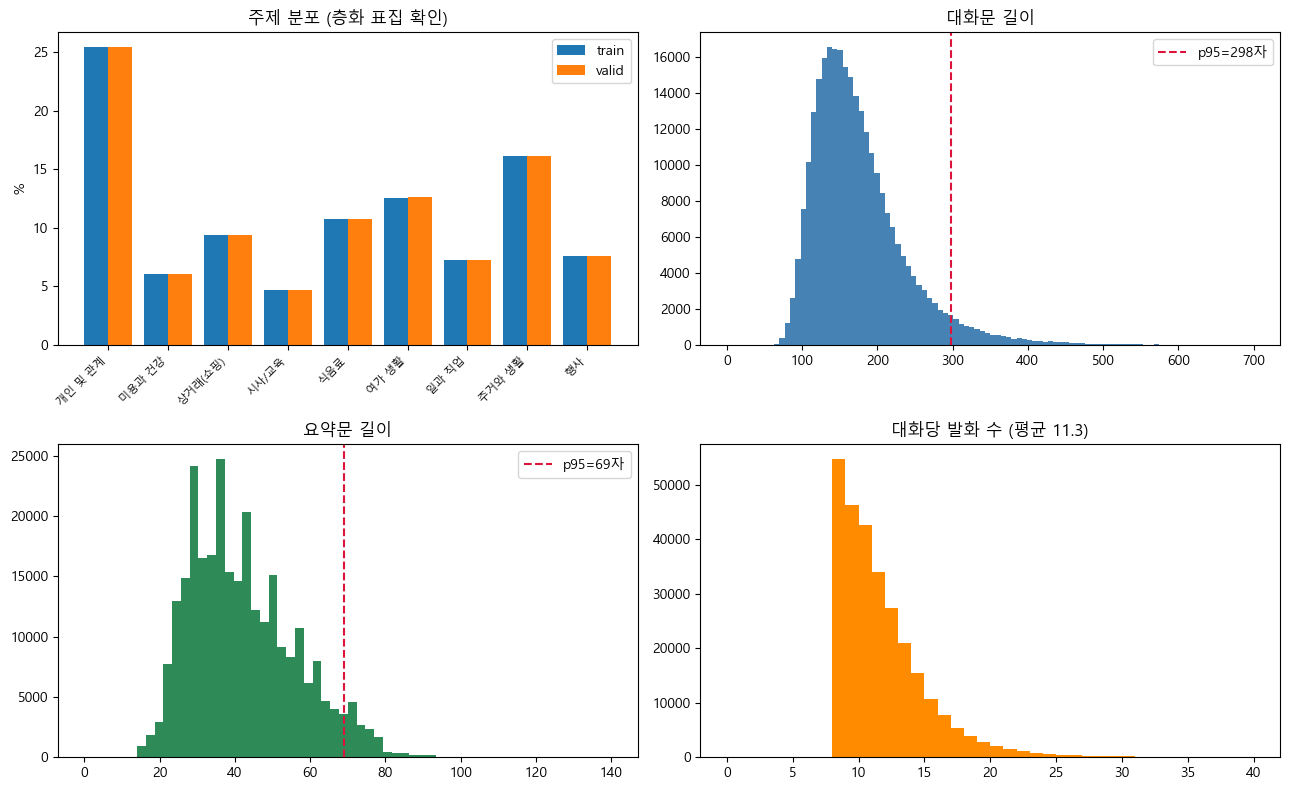

[여가 생활 / 일상 대화]
[P1] 버거로 리조또 만든거
[P1] 어떤 블로거가 따라했는디
[P1] 왜 이장우가 남긴지 알겠다고
[P2] 그걸 또 따라해 ㅜ
[P1] 그니까
[P2] 지독하다 그 블로거도
[P2] 음식한테
[P1] 컵아면 스파게티 넣고
[P2] 뭐하는짓거리야
[P1] 대박임 ㅜ
[P1] 내말이
[P2] 천벌받는다 느그들
[P1] 충격적 괴식
정답 요약: 버거로 리소토를 만드는 것을 어떤 블로거가 따라 했는데 음식을 가지고 뭐 하는 짓인지 천벌받을 것이라고 한다.
[주거와 생활 / 일상 대화]
[P1] 오늘 엄마침대서 자려고
[P1] 내방서자면
[P1] 허리아파서
[P2] 왜~?
[P2] 웅웅
[P2] 어머니는?
[P1] 허리가문젠지 저거 침대가문젠지 해서
[P1] 덥다고 바닥에서 돗자리깔고 주무신댕
[P2] 침대
[P2] 좋은거 써야해
[P1] 그러게
[P2] 안그럼 허리에 안좋대
[P1] 접는형식이라
[P1] 중간에 푹들어간곳도 있고..
[P1] 좀별로야 힝
정답 요약: 엄마께서는 바닥에 돗자리를 깔고 주무시고 자신은 허리가 아파서 엄마 침대에서 자려고 한다고 말하고 있다.


In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
tr = train_df.topic.value_counts(normalize=True).sort_index()*100
va = valid_df.topic.value_counts(normalize=True).sort_index()*100
x = np.arange(len(tr))
ax[0,0].bar(x-.2, tr.values, .4, label="train"); ax[0,0].bar(x+.2, va.reindex(tr.index).values, .4, label="valid")
ax[0,0].set_xticks(x); ax[0,0].set_xticklabels(tr.index, rotation=45, ha="right", fontsize=8)
ax[0,0].set_ylabel("%"); ax[0,0].set_title("주제 분포 (층화 표집 확인)"); ax[0,0].legend()

dl = train_df.dialogue.str.len()
ax[0,1].hist(dl, bins=100, range=(0,700), color="steelblue")
ax[0,1].axvline(dl.quantile(.95), color="crimson", ls="--", label=f"p95={dl.quantile(.95):.0f}자")
ax[0,1].set_title("대화문 길이"); ax[0,1].legend()

sl = train_df.summary.str.len()
ax[1,0].hist(sl, bins=60, range=(0,140), color="seagreen")
ax[1,0].axvline(sl.quantile(.95), color="crimson", ls="--", label=f"p95={sl.quantile(.95):.0f}자")
ax[1,0].set_title("요약문 길이"); ax[1,0].legend()

ax[1,1].hist(train_df.n_utt, bins=40, range=(0,40), color="darkorange")
ax[1,1].set_title(f"대화당 발화 수 (평균 {train_df.n_utt.mean():.1f})")
plt.tight_layout(); plt.show()

for _, r in valid_df.sample(2, random_state=0).iterrows():
    print("="*78); print(f"[{r.topic} / {r.type}]"); print(r.dialogue)
    print("정답 요약:", r.summary)

**EDA 결론**

- 주제 분포가 train/valid 소수점 둘째 자리까지 일치 → 층화 표집이 지켜짐. **재분할 불필요**
- ID 중복 0건, 요약문 완전중복 58건(0.02%) → 누수·중복 문제 없음
- 대화문 중앙값 163자 / p95 298자 / p99 407자, 요약문 p99 77자
- 압축률 ≈ **0.26** (정보를 1/4로 압축하는 과제)
- **`토론 대화` 0.57%** → 요약 틀은 99.94% 고정(「…에 대해 토론한다」). 형식보다 **탐지**가 과제 (§11.6)
- 화자의 **78.5% 20대, 84.3% 여성** → 일반화 한계로 보고서에 반드시 명시

---
### 4.1 추상성 분석 — 이 과제의 난이도를 수치로 확인

요약 데이터셋은 **추출적(extractive)** 인 것과 **추상적(abstractive)** 인 것으로 나뉩니다.
원문에서 문장을 골라내면 되는 데이터라면 ROUGE가 높게 나오지만,
원문에 없는 표현으로 다시 써야 하는 데이터라면 ROUGE는 구조적으로 낮습니다.

**신규 n-gram 비율**(요약문에는 있는데 대화문에는 없는 n-gram의 비율)이 이 성질을 재는 표준 지표입니다.
아래 셀을 돌리면 이 데이터셋의 값이 나오고, 공개 벤치마크와 비교됩니다.

또 하나 중요한 것이 **추출 oracle 상한** 입니다.
정답을 미리 알고 대화문에서 *가장 좋은* 발화를 골랐을 때의 점수 —
즉 **추출 방식으로 도달 가능한 이론적 최대치**입니다.
생성 모델이 이 값을 넘지 못하면 추상 요약을 하는 의미가 없습니다.

In [13]:
def novel_ngram_rate(sum_toks, src_toks, n):
    if len(sum_toks) < n: return None
    src = {tuple(src_toks[i:i+n]) for i in range(len(src_toks)-n+1)}
    g = [tuple(sum_toks[i:i+n]) for i in range(len(sum_toks)-n+1)]
    return sum(1 for x in g if x not in src) / len(g)


def abstractiveness(df, n_sample=20_000, seed=0):
    s = df.sample(min(n_sample, len(df)), random_state=seed)
    acc = collections.defaultdict(list)
    for d, sm in tqdm(zip(s["dialogue"], s["summary"]), total=len(s), desc="추상성", leave=False):
        for name, fn in (("어절", tok_word), ("어간", tok_stem), ("음절", tok_char)):
            st, dt = fn(sm), fn(d)
            for n in (1, 2, 3):
                v = novel_ngram_rate(st, dt, n)
                if v is not None: acc[(name, n)].append(v)
    rows = [{"단위": k[0], "n": k[1], "신규 n-gram %": round(100*float(np.mean(v)), 1)}
            for k, v in acc.items()]
    return pd.DataFrame(rows).pivot(index="단위", columns="n", values="신규 n-gram %"), \
           np.array(acc[("어간", 1)])


abs_tbl, uni_stem = abstractiveness(train_df)
print("=== 신규 n-gram 비율 (%) — 높을수록 추상적 ===")
print(abs_tbl.to_string())
print(f"""
참고 (문헌값, 단어 기준 신규 unigram)
  CNN/DailyMail  약 17%   거의 추출적
  XSum           약 36%   매우 추상적인 벤치마크로 알려짐
  이 데이터셋     {abs_tbl.loc['어절', 1]:.0f}% (어절) / {abs_tbl.loc['어간', 1]:.0f}% (어간)
""")

bins = [0, .2, .4, .6, .8, 1.01]
labs = ["0-20% (추출적)", "20-40%", "40-60%", "60-80%", "80-100% (완전 재작성)"]
h, _ = np.histogram(uni_stem, bins=bins)
print("추상성 구간 분포 (어간 unigram 기준)")
for l, c in zip(labs, h):
    print(f"  {l:<22s} {c:6,}건 ({100*c/len(uni_stem):5.1f}%)  {'█'*int(45*c/len(uni_stem))}")

추상성:   0%|          | 0/20000 [00:00<?, ?it/s]

=== 신규 n-gram 비율 (%) — 높을수록 추상적 ===
n      1     2     3
단위                  
어간  73.6  93.2  98.0
어절  80.5  95.2  98.6
음절  27.2  61.4  76.2

참고 (문헌값, 단어 기준 신규 unigram)
  CNN/DailyMail  약 17%   거의 추출적
  XSum           약 36%   매우 추상적인 벤치마크로 알려짐
  이 데이터셋     80% (어절) / 74% (어간)

추상성 구간 분포 (어간 unigram 기준)
  0-20% (추출적)                47건 (  0.2%)  
  20-40%                    685건 (  3.4%)  █
  40-60%                  3,410건 ( 17.1%)  ███████
  60-80%                  7,578건 ( 37.9%)  █████████████████
  80-100% (완전 재작성)        8,280건 ( 41.4%)  ██████████████████


In [14]:
def extractive_oracle(df, n_sample=1500, max_span=3, seed=0, mode="stem"):
    """정답을 알고 최적 발화를 골랐을 때의 점수 = 추출 방식의 이론적 상한."""
    s = df.sample(min(n_sample, len(df)), random_state=seed)
    tk = TOKENIZERS[mode]
    one, span = [], []
    for d, sm in tqdm(zip(s["dialogue"], s["summary"]), total=len(s), desc="oracle", leave=False):
        ref = tk(sm)
        us = [re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n")]
        if not us: continue
        best1 = max(_rouge_n(tk(u), ref, 1) for u in us)
        bestS = best1
        for i in range(len(us)):
            for j in range(i+1, min(i+max_span, len(us))+1):
                bestS = max(bestS, _rouge_n(tk(" ".join(us[i:j])), ref, 1))
        one.append(best1); span.append(bestS)
    return 100*float(np.mean(one)), 100*float(np.mean(span))

o1, o3 = extractive_oracle(train_df)
print(f"=== 추출 oracle 상한 (ROUGE-1, {cfg.select_metric} 기준) ===")
print(f"  최적 발화 1개 선택   : {o1:5.1f}")
print(f"  최적 연속 1~3발화    : {o3:5.1f}")
print(f"""
해석
  - 대화문에서 아무리 잘 골라내도 ROUGE-1 {o3:.0f} 를 넘을 수 없습니다.
  - 학습된 생성 모델이 이 값 근처면 '추출 수준', 넘어서면 '진짜 추상 요약'입니다.
  - §7의 추출 베이스라인(실제로 고른 것)과 이 oracle(정답 보고 고른 것)의 차이가
    추출 전략만으로 남은 여지입니다.
""")
ORACLE_CEIL = o3

oracle:   0%|          | 0/1500 [00:00<?, ?it/s]

=== 추출 oracle 상한 (ROUGE-1, stemsub 기준) ===
  최적 발화 1개 선택   :  22.2
  최적 연속 1~3발화    :  25.1

해석
  - 대화문에서 아무리 잘 골라내도 ROUGE-1 25 를 넘을 수 없습니다.
  - 학습된 생성 모델이 이 값 근처면 '추출 수준', 넘어서면 '진짜 추상 요약'입니다.
  - §7의 추출 베이스라인(실제로 고른 것)과 이 oracle(정답 보고 고른 것)의 차이가
    추출 전략만으로 남은 여지입니다.



### 4.2 데이터 품질 감사

라벨 오류나 형식 이탈이 섞여 있으면 학습이 흔들립니다. 전수 검사로 확인합니다.

**주의**: "요약과 대화의 단어 겹침이 적다"는 것은 **라벨 오류가 아닙니다.**
§4.1에서 본 대로 이 데이터는 원래 그렇게 만들어졌습니다.
아래 감사는 겹침이 아니라 **형식 이탈**(길이 이상치, 마스킹 잔존, 종결어미 규약 위반,
전처리 후 빈 대화, 단일 발화 복사)만 잡습니다.

In [15]:
def audit_quality(df, name="train"):
    flags, samples = collections.Counter(), collections.defaultdict(list)
    for r in df.itertuples():
        s, d = r.summary, r.dialogue
        us = [re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n")]
        ws = set(tok_word(s))

        if len(s) > 120: flags["요약 120자 초과"] += 1
        if len(s) < 18:  flags["요약 18자 미만"] += 1
        if len(d) > 800: flags["대화 800자 초과"] += 1
        if RE_LEAK.search(s) or "#@" in s:
            flags["요약에 마스킹 토큰 잔존"] += 1; samples["leak"].append(r)
        if not re.search(r"(다|요)\.?$", s.strip()):
            flags["비표준 종결어미"] += 1; samples["ending"].append(r)
        if len(us) <= 1:
            flags["전처리 후 발화 1개 이하"] += 1; samples["empty"].append(r)
        if ws and max((len(ws & set(tok_word(u)))/len(ws) for u in us), default=0) >= 0.9 and len(ws) >= 5:
            flags["단일 발화 90%+ 복사"] += 1; samples["copy"].append(r)

    print(f"=== 품질 감사: {name} {len(df):,}건 ===")
    if not flags:
        print("  이상 없음")
    for k, v in flags.most_common():
        print(f"  {k:<26s} {v:7,}건 ({100*v/len(df):5.2f}%)")
    total = sum(flags[k] for k in ("요약 120자 초과", "요약 18자 미만",
                                   "요약에 마스킹 토큰 잔존", "비표준 종결어미",
                                   "전처리 후 발화 1개 이하", "단일 발화 90%+ 복사"))
    print(f"\n  → 필터 후보 합계 약 {total:,}건 ({100*total/len(df):.2f}%)")
    print("     1% 미만이면 필터링의 실익이 없습니다. 그대로 학습하세요.")
    return flags, samples

qflags, qsamples = audit_quality(train_df)


def audit_label_consistency(df, name="train"):
    """유형 라벨과 요약문 형식이 서로 맞는지. 이 데이터셋에서는 실측 4건(0.001%)뿐입니다."""
    pat = re.compile(r"에 대(해|하여)서? 토론")
    is_deb = df["type"] == "토론 대화"
    has_t  = df["summary"].str.contains(pat, regex=True)
    a = int((~is_deb & has_t).sum())
    b = int((is_deb & ~has_t).sum())
    print(f"\n=== 라벨-요약 정합성: {name} {len(df):,}건 ===")
    print(f"  일상인데 토론 틀:  {a}건")
    print(f"  토론인데 다른 틀:  {b}건")
    print(f"  → 합계 {a+b}건 ({100*(a+b)/max(len(df),1):.4f}%)"
          + ("  라벨 노이즈 사실상 없음" if (a+b)/max(len(df),1) < 0.001 else "  확인 필요"))
    # 두 유형의 요약 종결 분포가 다른지 (분포 이동 점검)
    if is_deb.sum() and (~is_deb).sum():
        e1 = df.loc[is_deb, "summary"].str[-4:].value_counts(normalize=True)
        e0 = df.loc[~is_deb, "summary"].str[-4:].value_counts(normalize=True)
        keys = set(e1.index) | set(e0.index)
        tvd = 0.5*sum(abs(e1.get(k, 0) - e0.get(k, 0)) for k in keys)
        print(f"  유형 간 종결어미 분포 총변동거리 TVD = {tvd:.3f} "
              f"({'형식이 뚜렷이 다름 — 모델이 구분해야 함' if tvd > 0.5 else '유사'})")
    return a + b


audit_label_consistency(train_df)

for key, title in [("leak", "마스킹 토큰 잔존"), ("ending", "비표준 종결"),
                   ("empty", "발화 1개 이하"), ("copy", "단일 발화 복사")]:
    if qsamples[key]:
        print("\n" + "="*70); print("#", title, f"({len(qsamples[key])}건 중 최대 2건)")
        for r in qsamples[key][:2]:
            print("-"*70); print(r.dialogue[:220]); print("  → 요약:", r.summary)


# 필요할 때만 켜는 필터 (기본은 끔)
APPLY_QUALITY_FILTER = False
if APPLY_QUALITY_FILTER:
    before = len(train_df)
    keep = train_df.apply(
        lambda r: (18 <= len(r.summary) <= 120) and len(r.dialogue) <= 800
                  and not RE_LEAK.search(r.summary)
                  and bool(re.search(r"(다|요)\.?$", r.summary.strip()))
                  and len(r.dialogue.split("\n")) > 1, axis=1)
    train_df = train_df[keep].reset_index(drop=True)
    print(f"\n필터 적용: {before:,} → {len(train_df):,}건 "
          f"(-{before-len(train_df):,})  ※ §5 토큰 캐시를 지우고 다시 실행하세요")

=== 품질 감사: train 279,992건 ===
  요약 18자 미만                    1,777건 ( 0.63%)
  대화 800자 초과                      38건 ( 0.01%)
  요약 120자 초과                      19건 ( 0.01%)
  비표준 종결어미                         4건 ( 0.00%)
  단일 발화 90%+ 복사                    1건 ( 0.00%)

  → 필터 후보 합계 약 1,801건 (0.64%)
     1% 미만이면 필터링의 실익이 없습니다. 그대로 학습하세요.

=== 라벨-요약 정합성: train 279,992건 ===
  일상인데 토론 틀:  3건
  토론인데 다른 틀:  1건
  → 합계 4건 (0.0014%)  라벨 노이즈 사실상 없음
  유형 간 종결어미 분포 총변동거리 TVD = 0.999 (형식이 뚜렷이 다름 — 모델이 구분해야 함)

# 비표준 종결 (4건 중 최대 2건)
----------------------------------------------------------------------
[P1] 나 꼽먹음 개빡쳐,,
[P2] .?.?.?.?.?.?
[P2] 어서 말하고라
[P1] 아니
[P1] 내가 너무졸려서 졸거있었는데
[P1] 그 사람이 저기 노란옷 입은사람 자는거 불편해보이니까 좀 세워주라고 이랬다닌거야
[P1] 그래서 사람들 다웃고 다쳐다보고 ㅜㅜ
[P2] 왜저래..
[P2] 왜 꼽주냐냐나아아아아아
[P1] 그니까 짜중나게ㅡㅜㅜ
  → 요약: 졸고 있는 모습이 불편해 보이니까 세워 주라고 하는 그 사람의 말에 사람들이 다 웃고 쳐다봐서 망신당했다(꼽주냐).
----------------------------------------------------------------------
[P1] 으아 치고왓오
[P2] 아는거다적엇오!!??
[P2] 수고했엉 울[이름]ㅠ
[P1] 거의 4문제 모르는거 나

C:\Users\KDT52\AppData\Local\Temp\ipykernel_21256\3893748140.py:39: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_t  = df["summary"].str.contains(pat, regex=True)


---
## 5. 토크나이저 · 길이 결정 · **사전 토큰화 캐시**

### 왜 사전 토큰화인가

v1은 `__getitem__` 안에서 매 샘플을 토크나이즈했습니다. Windows는 `num_workers=0`이라
이 작업이 **학습 스레드를 직접 점유**합니다. 3에폭이면 같은 문장을 3번 토크나이즈하는 낭비이기도 합니다.

전체를 한 번에 batch encode 해서 `int32` 배열로 캐싱하면, 이후 실행에서는 토크나이즈 비용이 **0**이 됩니다.
(28만 건 × 평균 100토큰 × 4바이트 ≈ 110MB, 메모리에 충분히 올라갑니다)

In [16]:
tokenizer = AutoTokenizer.from_pretrained(cfg.model_name)
if cfg.add_speaker_tokens:
    n_added = tokenizer.add_special_tokens(
        {"additional_special_tokens": [f"[P{i}]" for i in range(1, 9)]})
    print(f"화자 special token {n_added}개 추가")
print("vocab:", len(tokenizer), "| pad/bos/eos:",
      tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id)
print("예시:", tokenizer.tokenize("[P1] 내일 저녁에 뭐 먹을까? [P2] 곱창 어때"))

config.json: 0.00B [00:00, ?B/s]

c:\nlp3\venv3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\KDT52\.cache\huggingface\hub\models--gogamza--kobart-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil b

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


화자 special token 8개 추가
vocab: 30008 | pad/bos/eos: 3 1 1
예시: ['[P1]', '▁내일', '▁저녁', '에', '▁뭐', '▁먹을', '까?', '▁', '[P2]', '▁곱', '창', '▁어', '때']


c:\nlp3\venv3\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [17]:
CACHE_KEY = (f"{cfg.model_name.replace('/', '_').replace(chr(92), '_')}"
             f"_in{cfg.max_input_len}_out{cfg.max_target_len}"
             f"_sp{int(cfg.add_speaker_tokens)}_tp{int(cfg.use_topic_prefix)}"
             f"_pv{PREP_VERSION}"
             + (f"_td{cfg.topic_prefix_dropout}" if cfg.use_topic_prefix else ""))

def to_model_input(df, training=False, seed=0):
    """모델에 들어가는 입력 문자열. 학습/평가/추론이 항상 같은 형식을 쓰도록 한 곳에서 생성.

    training=True 일 때만 topic prefix 를 확률적으로 생략합니다(prefix dropout).

    왜 필요한가: 가이드라인 2.6.2 의 서비스 입력은 **발화 목록뿐**이라 주제가 없습니다.
    주제를 항상 붙여 학습하면 서빙 때 주제를 지어내야 하고, 틀린 주제를 넣으면
    학습 분포에서 벗어납니다. 일부를 주제 없이 학습해 두면 **양쪽 다** 동작합니다.
    """
    if not cfg.use_topic_prefix:
        return df["dialogue"].tolist()
    if not training or cfg.topic_prefix_dropout <= 0:
        return ("[" + df["topic"].astype(str) + "] " + df["dialogue"]).tolist()
    rng = np.random.default_rng(seed)
    keep = rng.random(len(df)) >= cfg.topic_prefix_dropout
    return [f"[{t}] {d}" if k else d
            for t, d, k in zip(df["topic"].astype(str), df["dialogue"], keep)]

def pretokenize(df, split, chunk=20_000):
    """전체를 batch encode 해서 int32 리스트로 캐싱. 두 번째 실행부터는 즉시 로드."""
    path = Path(cfg.work_dir) / f"tok_{split}_{CACHE_KEY}.pkl"
    if path.exists():
        src, tgt = pickle.load(open(path, "rb"))
        print(f"토큰 캐시 재사용: {path.name}  ({len(src):,}건)")
        return src, tgt

    src, tgt = [], []
    t0 = time.time()
    model_in = to_model_input(df, training=(split == "train"), seed=cfg.seed)
    for i in tqdm(range(0, len(df), chunk), desc=f"tokenize[{split}]"):
        d = model_in[i:i+chunk]
        s = df["summary"].iloc[i:i+chunk].tolist()
        e = tokenizer(d, max_length=cfg.max_input_len, truncation=True)["input_ids"]
        l = tokenizer(text_target=s, max_length=cfg.max_target_len, truncation=True)["input_ids"]
        src += [np.asarray(x, dtype=np.int32) for x in e]
        tgt += [np.asarray(x, dtype=np.int32) for x in l]
    pickle.dump((src, tgt), open(path, "wb"), protocol=4)
    print(f"→ {path.name} 저장 ({time.time()-t0:.0f}s)")
    return src, tgt

TR_SRC, TR_TGT = pretokenize(train_df, "train")
VA_SRC, VA_TGT = pretokenize(valid_df, "valid")

TR_LEN = np.array([len(a) for a in TR_SRC], dtype=np.int32)
VA_LEN = np.array([len(a) for a in VA_SRC], dtype=np.int32)

tokenize[train]:   0%|          | 0/14 [00:00<?, ?it/s]

→ tok_train_gogamza_kobart-base-v2_in256_out80_sp1_tp0_pv3.pkl 저장 (23s)


tokenize[valid]:   0%|          | 0/2 [00:00<?, ?it/s]

→ tok_valid_gogamza_kobart-base-v2_in256_out80_sp1_tp0_pv3.pkl 저장 (2s)



[입력(대화문)] mean 90.5 / median 84 / p99 210 / max 256
   max_length=  96 →  66.26% 무손실
   max_length= 128 →  88.52% 무손실
   max_length= 192 →  98.40% 무손실
   max_length= 256 → 100.00% 무손실
   max_length= 384 → 100.00% 무손실
   max_length= 512 → 100.00% 무손실

[출력(요약문)] mean 18.6 / median 18 / p99 36 / max 80
   max_length=  32 →  96.81% 무손실
   max_length=  48 →  99.96% 무손실
   max_length=  64 → 100.00% 무손실
   max_length=  80 → 100.00% 무손실
   max_length=  96 → 100.00% 무손실


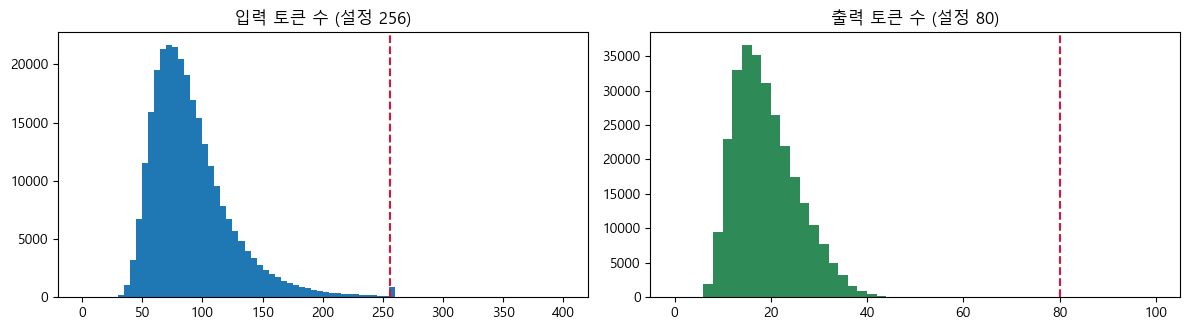

In [18]:
# ---- 길이 커버리지: max_input_len 을 근거 있게 정하기 ----
probe_src = TR_LEN
probe_tgt = np.array([len(a) for a in TR_TGT])

def coverage(lengths, limits, name):
    print(f"\n[{name}] mean {lengths.mean():.1f} / median {np.median(lengths):.0f} / "
          f"p99 {np.percentile(lengths,99):.0f} / max {lengths.max()}")
    for L in limits:
        print(f"   max_length={L:>4d} → {100*(lengths<=L).mean():6.2f}% 무손실")

coverage(probe_src, [96, 128, 192, 256, 384, 512], "입력(대화문)")
coverage(probe_tgt, [32, 48, 64, 80, 96],          "출력(요약문)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(probe_src, bins=80, range=(0, 400)); ax[0].axvline(cfg.max_input_len, color="crimson", ls="--")
ax[0].set_title(f"입력 토큰 수 (설정 {cfg.max_input_len})")
ax[1].hist(probe_tgt, bins=50, range=(0, 100), color="seagreen"); ax[1].axvline(cfg.max_target_len, color="crimson", ls="--")
ax[1].set_title(f"출력 토큰 수 (설정 {cfg.max_target_len})")
plt.tight_layout(); plt.show()

> **읽는 법**: 커버리지가 99% 이상인 가장 작은 값을 고르세요.
> 잘린 1%는 대부분 뒷부분 잡담이라 요약 품질에 거의 영향이 없습니다.
> 길이를 줄이면 **길이그룹 배칭과 곱해져** 효과가 커집니다.
> 커버리지가 99% 미만이면 `cfg.max_input_len`을 올리고 이 셀부터 다시 실행하세요
> (캐시 키에 길이가 들어있어 자동으로 재토큰화됩니다).

---
## 6. **길이 그룹 배칭** — 가장 큰 속도 개선

배치는 가장 긴 샘플에 맞춰 패딩됩니다. 무작위로 32개를 뽑으면 그 안에 긴 대화가 하나만 섞여도
나머지 31개가 전부 그 길이까지 패딩됩니다. **패딩 토큰에도 연산은 똑같이 들어갑니다.**

해결책: 인덱스를 섞은 뒤 `batch_size × 50` 크기의 **메가배치**로 쪼개고,
메가배치 안에서 길이순 정렬해 배치를 만들고, 배치 순서를 다시 섞습니다.
길이가 비슷한 것끼리 묶이면서도 무작위성이 유지됩니다.

아래 셀이 **실제 개선폭을 직접 측정**해 줍니다.

In [19]:
class LengthGroupedBatchSampler(Sampler):
    def __init__(self, lengths, batch_size, shuffle=True, mega_batch=50,
                 seed=42, drop_last=False):
        self.lengths = np.asarray(lengths)
        self.bs, self.shuffle, self.mega = batch_size, shuffle, mega_batch
        self.seed, self.drop_last, self.epoch = seed, drop_last, 0
        n, mega_size = len(self.lengths), batch_size * mega_batch
        self._len = 0                                   # 배치 개수는 셔플과 무관하게 결정됨
        for i in range(0, n, mega_size):
            m = min(mega_size, n - i)
            self._len += m // batch_size if drop_last else math.ceil(m / batch_size)

    def set_epoch(self, e): self.epoch = e
    def __len__(self): return self._len

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        n = len(self.lengths)
        idx = rng.permutation(n) if self.shuffle else np.arange(n)
        mega_size, batches = self.bs * self.mega, []
        for i in range(0, n, mega_size):
            chunk = idx[i:i+mega_size]
            chunk = chunk[np.argsort(-self.lengths[chunk], kind="stable")]   # 길이 내림차순
            for j in range(0, len(chunk), self.bs):
                b = chunk[j:j+self.bs]
                if self.drop_last and len(b) < self.bs: continue
                batches.append(b.tolist())
        if self.shuffle:
            rng.shuffle(batches)                        # 배치 순서는 섞어 길이 편향 제거
        return iter(batches)


class SeqCollator:
    """이미 토큰화된 int32 배열 → 패딩된 텐서. tokenizer 호출 없음."""
    def __init__(self, pad_id, mult=8):
        self.pad, self.mult = pad_id, mult
    def _ceil(self, x): return int(math.ceil(x / self.mult) * self.mult)
    def __call__(self, batch):
        srcs, tgts = zip(*batch)
        Ls, Lt = self._ceil(max(len(a) for a in srcs)), self._ceil(max(len(a) for a in tgts))
        B = len(srcs)
        input_ids = torch.full((B, Ls), self.pad, dtype=torch.long)
        attn      = torch.zeros((B, Ls), dtype=torch.long)
        labels    = torch.full((B, Lt), -100, dtype=torch.long)
        for i, (s, t) in enumerate(zip(srcs, tgts)):
            input_ids[i, :len(s)] = torch.from_numpy(s.astype(np.int64))
            attn[i, :len(s)] = 1
            labels[i, :len(t)] = torch.from_numpy(t.astype(np.int64))
        return {"input_ids": input_ids, "attention_mask": attn, "labels": labels}


class TokenizedDataset(Dataset):
    def __init__(self, src, tgt, indices=None):
        self.idx = np.arange(len(src)) if indices is None else np.asarray(indices)
        self.src, self.tgt = src, tgt
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return self.src[j], self.tgt[j]

In [20]:
# ---- 층화 샘플링(위치 인덱스 기반) ----
def stratified_indices(df, n, key="topic", seed=42):
    """df 안에서 key 비율을 유지한 채 n건의 '위치 인덱스'를 뽑는다."""
    if n is None or n >= len(df):
        return np.arange(len(df))
    rng, picked = np.random.default_rng(seed), []
    pos = {v: i for i, v in enumerate(df.index)}          # 라벨 → 위치
    for _, idx in df.groupby(key).groups.items():
        p = np.array([pos[v] for v in idx])
        k = min(len(p), max(1, round(n * len(p) / len(df))))
        picked.append(rng.choice(p, size=k, replace=False))
    out = np.concatenate(picked); rng.shuffle(out)
    return out

def stratified_subset_of(df, positions, n, key="topic", seed=42):
    """positions 로 제한한 부분집합에서 층화 샘플링해 '원본 기준 위치'를 돌려준다."""
    sub = df.iloc[positions]
    return np.asarray(positions)[stratified_indices(sub, n, key, seed)]


# ---- ★ Validation 을 dev(모델 선택) / test(최종 보고) 로 분할 ----
# Test 스플릿이 배포되지 않았으므로 직접 만든다.
# 같은 데이터로 체크포인트를 고르고 성능을 보고하면 낙관 편향이 생긴다.
_rng = np.random.default_rng(cfg.seed)
dev_mask = np.zeros(len(valid_df), dtype=bool)
for _, idx in valid_df.groupby("topic").groups.items():                 # 주제 비율 유지
    p = np.array([valid_df.index.get_loc(v) for v in idx])
    dev_mask[_rng.choice(p, size=int(round(len(p)*cfg.dev_ratio)), replace=False)] = True
DEV_POS, TEST_POS = np.where(dev_mask)[0], np.where(~dev_mask)[0]

train_idx = stratified_indices(train_df, cfg.train_subset, seed=cfg.seed)
valid_idx = stratified_subset_of(valid_df, DEV_POS, cfg.valid_subset, seed=cfg.seed)
print(f"학습 {len(train_idx):,}건")
print(f"dev  {len(DEV_POS):,}건 → loss 검증 {len(valid_idx):,}건 / 생성 모니터링 {cfg.eval_gen_subset}건")
print(f"test {len(TEST_POS):,}건 → 최종 보고 전용 (학습·모델선택에 절대 사용 안 함)")

# ---- ★ 패딩 낭비 실측: 무작위 vs 길이그룹 ----
def padding_stats(batches, lengths, mult):
    padded = real = 0
    for b in batches:
        L = int(math.ceil(lengths[b].max() / mult) * mult)
        padded += L * len(b); real += lengths[b].sum()
    return padded / len(lengths), real / len(lengths)

sub_len = TR_LEN[train_idx]
rng = np.random.default_rng(0); perm = rng.permutation(len(sub_len))
rand_batches = [perm[i:i+cfg.batch_size] for i in range(0, len(perm)-cfg.batch_size+1, cfg.batch_size)]
grp_sampler  = LengthGroupedBatchSampler(sub_len, cfg.batch_size, mega_batch=cfg.mega_batch, seed=0)
grp_batches  = [np.array(b) for b in grp_sampler]

pr, rr = padding_stats(rand_batches, sub_len, cfg.pad_multiple)
pg, _  = padding_stats(grp_batches,  sub_len, cfg.pad_multiple)
print(f"\n무작위 배칭  : 샘플당 처리 토큰 {pr:6.1f} (실제 {rr:.1f}) → 패딩 낭비 {100*(1-rr/pr):5.1f}%")
print(f"길이그룹 배칭: 샘플당 처리 토큰 {pg:6.1f} (실제 {rr:.1f}) → 패딩 낭비 {100*(1-rr/pg):5.1f}%")
print(f"★ 연산량 감소 : {100*(1-pg/pr):.1f}%  (attention은 길이 제곱이라 체감은 더 큼)")

학습 2,001건
dev  17,502건 → loss 검증 299건 / 생성 모니터링 50건
test 17,502건 → 최종 보고 전용 (학습·모델선택에 절대 사용 안 함)

무작위 배칭  : 샘플당 처리 토큰  184.4 (실제 88.8) → 패딩 낭비  51.8%
길이그룹 배칭: 샘플당 처리 토큰   97.2 (실제 88.8) → 패딩 낭비   8.6%
★ 연산량 감소 : 47.3%  (attention은 길이 제곱이라 체감은 더 큼)


In [21]:
collator = SeqCollator(tokenizer.pad_token_id, cfg.pad_multiple)
train_ds = TokenizedDataset(TR_SRC, TR_TGT, train_idx)
valid_ds = TokenizedDataset(VA_SRC, VA_TGT, valid_idx)

def make_loader(ds, lengths, batch_size, shuffle, drop_last=False):
    common = dict(collate_fn=collator, num_workers=cfg.num_workers,
                  pin_memory=(DEVICE.type == "cuda"))
    if cfg.num_workers > 0:
        common["persistent_workers"] = True
    if cfg.group_by_length:
        bs = LengthGroupedBatchSampler(lengths, batch_size, shuffle=shuffle,
                                       mega_batch=cfg.mega_batch, seed=cfg.seed,
                                       drop_last=drop_last)
        return DataLoader(ds, batch_sampler=bs, **common), bs
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      drop_last=drop_last, **common), None

train_loader, train_bsampler = make_loader(train_ds, TR_LEN[train_idx], cfg.batch_size, True, True)
valid_loader, _              = make_loader(valid_ds, VA_LEN[valid_idx], cfg.eval_batch_size, False)

b = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in b.items()})
print("\n입력 복원:", tokenizer.decode(b["input_ids"][0], skip_special_tokens=False)[:220])
l0 = b["labels"][0]
print("\n정답 복원:", tokenizer.decode(l0[l0 != -100], skip_special_tokens=True))

{'input_ids': (32, 80), 'attention_mask': (32, 80), 'labels': (32, 40)}

입력 복원: [P1] 쿠폰기한 아직남앗으니
[P1] 구입하셔
[P2] 셰프초이스 춘천식닭갈비네
[P1] 어 이거는 할인안된다
[P2] 그런것같드라
[P2] 쿠폰이나는
[P2] 무소용이더라 ᄒᄒ
[P1] 생고기만
[P2] 지금사면 오후6시전에온다는데
[P2] 흠..
[P1] 되는거같은데

정답 복원: 춘천식 닭갈비에 대해 이야기하며 할인이 안된다고 하고 있다.


---
## 7. 지표 해석 — 이 점수를 믿어도 되는가

토크나이저와 ROUGE 구현은 §3.2에 있습니다. 여기서는 **그 숫자를 어떻게 읽어야 하는지**를 다룹니다.

- **§7.1 노이즈 바닥**: 무관한 요약을 넣어도 나오는 점수. 이 아래는 의미 없음
- **§7.2 신뢰구간과 유의성**: `18.3` 이 아니라 `18.3 ± 0.8` 로 보고해야 하는 이유
- **§4.1 추출 oracle 상한**: 추출로 도달 가능한 최대치. 이 위여야 추상 요약

In [22]:
# ---- 후처리: 마스킹 토큰 누출 제거 + 공백 정리 ----
RE_LEAK_STRIP = re.compile(                                                # 제거용(딸린 조사까지)
    r"\[(?:이름|링크|소속|주소|계정|번호|기타)\]"
    r"(?:이랑|에게|에서|과|와|은|는|이|가|을|를|의|에|랑|도|만)?\s*")

def postprocess(text):
    text = RE_LEAK_STRIP.sub("", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^[,.·\s]+", "", text)
    if text and text[-1] not in ".!?":
        text += "."
    return text

print(postprocess("[이름]과 [주소]에서   만나기로 했다"))   # → 만나기로 했다.
print(postprocess("  공백   정리 테스트  "))

# ---- 추출 베이스라인 (학습 없이 얻는 하한선) ----
GEN_POS  = stratified_subset_of(valid_df, DEV_POS, cfg.eval_gen_subset, seed=cfg.seed + 1)
gen_eval = valid_df.iloc[GEN_POS].reset_index(drop=True)
GEN_SRC  = to_model_input(gen_eval)          # topic prefix 설정을 학습과 동일하게 적용

def _utts(d): return [re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n")]
base = {
    "가장 긴 발화": lambda d: max(_utts(d), key=len) if _utts(d) else "",
    "앞 2발화":     lambda d: " ".join(_utts(d)[:2]),
    "뒤 2발화":     lambda d: " ".join(_utts(d)[-2:]),
}
refs = gen_eval["summary"].tolist()
print("추출 베이스라인")
for name, fn in base.items():
    preds = [fn(d) for d in gen_eval["dialogue"]]
    print(f"  {name:<10s} {cfg.select_metric}={compute_rouge(preds, refs, cfg.select_metric)}"
          f"  char={compute_rouge(preds, refs, 'char')}")
try:
    print(f"\n  (참고) 추출 oracle 상한 = {ORACLE_CEIL:.1f}  ← §4.1")
    print("   실제 선택 vs oracle 의 차이가 '더 똑똑한 추출'로 얻을 수 있는 최대치입니다.")
except NameError:
    pass


# ---- 사실성(factuality) 대리 지표 : ROUGE 가 못 잡는 환각을 보완 ----
STOPWORDS = set("그 저 이 것 거 수 때 등 및 또 좀 잘 안 못 더 다 되 하 있 없 같 나 너 우리 저희 뭐 왜".split())

def content_tokens(t):
    return [w for w in tok_word(t) if len(w) > 1 and w not in STOPWORDS]

def factuality(preds, refs, srcs):
    """내용어 재현율 = 정답의 핵심어를 얼마나 담았나 (높을수록 좋음)
       대화문 근거율 = 생성한 핵심어가 대화문에 실제로 있나 (낮으면 환각 의심)
       숫자 일치율   = 정답에 등장한 숫자를 맞췄나"""
    cov, gnd, num = [], [], []
    for p_, r_, s_ in zip(preds, refs, srcs):
        cp, cr, cs = set(content_tokens(p_)), set(content_tokens(r_)), set(content_tokens(s_))
        cov.append(len(cp & cr)/max(len(cr), 1))
        if cp: gnd.append(len(cp & cs)/len(cp))
        nr = set(re.findall(r"\d+", r_))
        if nr: num.append(len(set(re.findall(r"\d+", p_)) & nr)/len(nr))
    out = {"내용어 재현율": round(100*float(np.mean(cov)), 1),
           "대화문 근거율": round(100*float(np.mean(gnd)), 1) if gnd else None,
           "숫자 일치율":   round(100*float(np.mean(num)), 1) if num else None}
    return out

print("\n사실성 지표 — 정답 요약문 자체를 넣은 값이 '상한선'입니다")
print("  정답요약 기준:", factuality(refs, refs, gen_eval["dialogue"].tolist()))
print("  ※ '대화문 근거율'이 정답 기준으로도 낮은 이유: 사람이 쓴 요약은 어휘를 바꿔 씁니다")
print("     (아나고→붕장어, 리조또→리소토). 절댓값이 아니라 이 상한선 대비로 읽으세요.")

만나기로 했다.
공백 정리 테스트.
추출 베이스라인
  가장 긴 발화    stemsub={'rouge1': 10.15, 'rouge2': 10.15, 'rougeL': 10.15}  char={'rouge1': 24.82, 'rouge2': 11.74, 'rougeL': 20.14}
  앞 2발화      stemsub={'rouge1': 16.39, 'rouge2': 16.39, 'rougeL': 16.39}  char={'rouge1': 28.39, 'rouge2': 15.82, 'rougeL': 24.53}
  뒤 2발화      stemsub={'rouge1': 4.98, 'rouge2': 4.98, 'rougeL': 4.98}  char={'rouge1': 19.38, 'rouge2': 6.99, 'rougeL': 15.68}

  (참고) 추출 oracle 상한 = 25.1  ← §4.1
   실제 선택 vs oracle 의 차이가 '더 똑똑한 추출'로 얻을 수 있는 최대치입니다.

사실성 지표 — 정답 요약문 자체를 넣은 값이 '상한선'입니다
  정답요약 기준: {'내용어 재현율': 100.0, '대화문 근거율': 14.1, '숫자 일치율': 100.0}
  ※ '대화문 근거율'이 정답 기준으로도 낮은 이유: 사람이 쓴 요약은 어휘를 바꿔 씁니다
     (아나고→붕장어, 리조또→리소토). 절댓값이 아니라 이 상한선 대비로 읽으세요.


> 추출 베이스라인 ROUGE-1이 7 안팎이라는 건 **정답 요약문이 대화에 그대로 나오지 않는다**는 뜻입니다.
> 즉 이 과제는 본질적으로 생성 요약이고, 파인튜닝 모델이 이 숫자를 얼마나 넘느냐가 성패 기준입니다.

### 7.1 지표 보정 — 이 점수가 의미 있는 숫자인가?

ROUGE 값을 그대로 믿으면 안 됩니다. 두 가지를 먼저 재야 합니다.

**1. 노이즈 바닥** — 전혀 상관없는 요약문을 넣어도 점수가 0이 아닙니다.
같은 주제의 *다른* 대화 요약문을 예측으로 넣으면 그 지표의 바닥이 나옵니다.

**2. 띄어쓰기 내성** — 한국어는 띄어쓰기가 흔들려도 의미가 같습니다
("먹기로 했다" = "먹기로했다"). 어절 기반 지표는 이때 점수를 크게 잃습니다.
모델이 정답과 띄어쓰기만 달라도 부당하게 낮은 점수를 받게 됩니다.

아래 셀이 네 가지 지표를 두 축에서 동시에 평가합니다.

- **상한**: 정답 요약문 자신 (= 100)
- **신호**: 대화문 전체를 이어붙인 것
- **노이즈**: 같은 주제의 *다른* 대화 요약문
- **S/N** = 신호 ÷ 노이즈 (클수록 변별력)
- **띄어쓰기 손실** = 의미가 같은데 띄어쓰기만 다를 때 잃는 점수 (작을수록 좋음)

In [23]:
def calibrate_metrics(df, n=1500, seed=0):
    rng = random.Random(seed)
    s = df.sample(min(n, len(df)), random_state=seed).reset_index(drop=True)
    refs_c = s["summary"].tolist()

    def _utts(d): return [re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n")]
    signal = [" ".join(_utts(d)) for d in s["dialogue"]]          # 대화문 전체 연결

    by_topic = collections.defaultdict(list)
    for i, t in enumerate(s["topic"]): by_topic[t].append(i)
    noise = []
    for i, t in enumerate(s["topic"]):                            # 같은 주제의 다른 대화 요약
        pool = by_topic[t]; j = rng.choice(pool)
        while j == i and len(pool) > 1: j = rng.choice(pool)
        noise.append(refs_c[j])

    # 띄어쓰기 내성: 정답의 어절 30%를 붙여도 의미는 같습니다. 점수가 얼마나 깎이는지.
    def _squash(t, p=0.3):
        parts = t.split(" ")
        if not parts: return t
        out = [parts[0]]
        for w in parts[1:]:
            if rng.random() < p: out[-1] += w
            else: out.append(w)
        return " ".join(out)
    spaced = [_squash(t) for t in refs_c]

    rows = []
    for m in METRIC_SET:
        sg = compute_rouge(signal, refs_c, m)
        nz = compute_rouge(noise,  refs_c, m)
        sp = compute_rouge(spaced, refs_c, m)
        rows.append({"지표": m,
                     "상한(정답)": 100.0,
                     "신호 R1": sg["rouge1"], "노이즈 R1": nz["rouge1"],
                     "S/N": round(sg["rouge1"]/max(nz["rouge1"], 1e-9), 2),
                     "띄어쓰기 내성": sp["rouge1"],
                     "띄어쓰기 손실": round(100.0 - sp["rouge1"], 1)})
    return pd.DataFrame(rows)

calib = calibrate_metrics(valid_df)
print(calib.to_string(index=False))
print(f"\n→ 변별력 최고: {calib.loc[calib['S/N'].idxmax(), '지표']} (S/N {calib['S/N'].max():.2f})")
print(f"→ 현재 체크포인트 선택 기준: cfg.select_metric = '{cfg.select_metric}'")

_char = calib[calib["지표"] == "char"].iloc[0]
_stem = calib[calib["지표"] == "stem"].iloc[0]
_ssub = calib[calib["지표"] == "stemsub"].iloc[0]
print(f"""
읽는 법
  char    : 무관한 요약에도 R-1 {_char['노이즈 R1']:.1f} 이 나옵니다(S/N {_char['S/N']:.2f}).
            숫자가 커 보여도 대표 지표로 쓰면 안 됩니다.
  stem    : 변별력은 좋지만(S/N {_stem['S/N']:.2f}) 띄어쓰기만 달라져도
            {_stem['띄어쓰기 손실']:.0f}점을 잃습니다. 한국어에서 이건 큰 약점입니다.
  stemsub : 띄어쓰기 손실 {_ssub['띄어쓰기 손실']:.0f}점, S/N {_ssub['S/N']:.2f} — 두 축 모두에서 가장 낫습니다.
            (어간을 공백 제거 문자열의 부분문자열로 매칭 / 집합 기반이라 R-1=R-2=R-L)
  → 대표 지표는 stemsub, 관례적 비교용으로 stem 을 함께 보고하는 것을 권장합니다.
""")
calib.to_csv(Path(cfg.out_dir)/"metric_calibration.csv", index=False, encoding="utf-8-sig")

     지표  상한(정답)  신호 R1  노이즈 R1  S/N  띄어쓰기 내성  띄어쓰기 손실
   word   100.0  11.20    2.24 5.00    62.90     37.1
   stem   100.0  15.05    2.45 6.14    62.91     37.1
   char   100.0  35.72   24.26 1.47   100.00      0.0
stemsub   100.0  22.87    2.65 8.63   100.00      0.0

→ 변별력 최고: stemsub (S/N 8.63)
→ 현재 체크포인트 선택 기준: cfg.select_metric = 'stemsub'

읽는 법
  char    : 무관한 요약에도 R-1 24.3 이 나옵니다(S/N 1.47).
            숫자가 커 보여도 대표 지표로 쓰면 안 됩니다.
  stem    : 변별력은 좋지만(S/N 6.14) 띄어쓰기만 달라져도
            37점을 잃습니다. 한국어에서 이건 큰 약점입니다.
  stemsub : 띄어쓰기 손실 0점, S/N 8.63 — 두 축 모두에서 가장 낫습니다.
            (어간을 공백 제거 문자열의 부분문자열로 매칭 / 집합 기반이라 R-1=R-2=R-L)
  → 대표 지표는 stemsub, 관례적 비교용으로 stem 을 함께 보고하는 것을 권장합니다.



### 7.1b 사람의 상한 — ROUGE 100은 도달 가능한 목표가 아닙니다

§7.1은 지표의 **바닥**을 쟀습니다. 여기서는 **천장**을 잽니다.

같은 대화를 서로 다른 작업자가 요약했다면, 그 두 요약문 사이의 ROUGE가
**사람이 사람에게 낼 수 있는 최고점**입니다. 모델이 그보다 높을 이유가 없습니다.

이 데이터셋에는 중복이 거의 없지만(그 자체로 좋은 품질 신호입니다),
MinHash로 315,000건을 훑으면 **사실상 같은 대화인데 요약문이 다른 쌍**을 소수 찾을 수 있습니다.

**실측 결과 (train+valid 전체 탐색)**

> `[P1] 아 동생남친이 빼뺴로데이라고 허쉬쿠키 한통 줬는데 …` (자카드 0.899, 마스킹만 다른 동일 대화)
>
> - 작업자 A: **남동생의 여자 친구(여친)이 빼빼로데이라고 허쉬 쿠키를 보내줬는데 배송이 지연되고 있다.**
> - 작업자 B: **동생 여친(여자 친구)가 빼빼로데이라고 허쉬 쿠키 한 통을 줬는데 인기가 많았는지 배송 지연이 됐다.**
>
> 둘 다 완벽하게 맞는 요약입니다. 그런데 ROUGE-1 은 word 35.7 / stem 50.0 / stemsub 67.3 입니다.

| 지표 | 사람 vs 사람 R-1 (n=6, J≥0.44) |
|---|---|
| word | **37.7** |
| stem | **41.4** |
| stemsub | **39.4** |

**이게 무슨 뜻인가**

- **ROUGE 100은 목표가 아닙니다.** 사람끼리도 40 안팎입니다.
- 따라서 모델 점수는 100이 아니라 **이 값 대비 몇 %인지**로 읽어야 합니다.
  예: stemsub 19.4 → 사람 상한 39.4 의 약 **49%**.
- 보고서에 "ROUGE가 낮다"가 아니라 **"사람 수준의 약 절반"** 이라고 쓰는 편이 정확합니다.

**한계 — 반드시 같이 적으세요**

- **n=6~9로 매우 적습니다.** 이 데이터셋이 중복 제거를 잘 해 놓은 결과입니다. 참고치로만 쓰세요.
- 자카드 0.44~0.55 구간의 쌍은 완전히 같은 대화가 아니라 내용 차이도 일부 섞여 있어,
  실제 사람 일치도는 이 값보다 **조금 높을** 수 있습니다.
- 아래 셀이 당신의 데이터에서 직접 탐색합니다. **train+valid 전체(약 31만 건)를 넘겨야** 쌍이 나옵니다.
  일부만 샘플링했다면 0쌍이 정상이며, 이 경우 위 표의 값을 참고값으로 사용합니다.
- Test 스플릿이 추가로 배포되면 표본이 늘어납니다.

In [24]:
def find_near_duplicates(df_list, jaccard_min=0.40, k=5, nperm=48, bands=16,
                         max_bucket=40, seed=0, verbose=True):
    """MinHash LSH 로 '사실상 같은 대화'를 찾는다. 요약문이 다른 쌍만 돌려준다."""
    docs, meta = [], []
    for name, df in df_list:
        for r in df.itertuples():
            docs.append(r.dialogue); meta.append((name, r.summary))
    n = len(docs)
    if verbose: print(f"탐색 대상 {n:,}건")

    def norm(t): return re.sub(r"[^가-힣a-zA-Z0-9]", "", t)
    def sh(t):
        t = norm(t)
        return {t[i:i+k] for i in range(max(len(t)-k+1, 1))}

    rng = np.random.default_rng(seed)
    P = (1 << 31) - 1
    A = rng.integers(1, P, nperm, dtype=np.int64)
    B = rng.integers(0, P, nperm, dtype=np.int64)
    sig = np.empty((n, nperm), dtype=np.int64)
    for i, d in enumerate(tqdm(docs, desc="minhash", leave=False)):
        s = sh(d)
        hs = np.fromiter((hash(x) & 0x7fffffff for x in s), dtype=np.int64, count=len(s))
        sig[i] = ((A[None, :]*hs[:, None] + B[None, :]) % P).min(axis=0)

    R = max(1, nperm // bands)
    cand = set()
    for b in range(bands):
        buck = collections.defaultdict(list)
        for i in range(n):
            buck[sig[i, b*R:(b+1)*R].tobytes()].append(i)
        for v in buck.values():
            if 1 < len(v) <= max_bucket:
                for x in range(len(v)):
                    for y in range(x+1, len(v)):
                        cand.add((v[x], v[y]))
    if verbose: print(f"후보 쌍 {len(cand):,}")

    out = []
    for a, b in cand:
        sa, sb = sh(docs[a]), sh(docs[b])
        j = len(sa & sb) / max(len(sa | sb), 1)
        if j >= jaccard_min and meta[a][1] != meta[b][1]:
            out.append({"jaccard": round(j, 3), "dialogue": docs[a],
                        "summary_A": meta[a][1], "summary_B": meta[b][1],
                        "split_A": meta[a][0], "split_B": meta[b][0]})
    out.sort(key=lambda x: -x["jaccard"])
    if verbose:
        print(f"자카드 ≥ {jaccard_min} & 요약 상이: {len(out)}쌍")
        print("  (중복이 거의 없다는 것은 데이터 품질이 좋다는 뜻이기도 합니다 — "
              "패러프레이즈 수준의 train/valid 누수가 없습니다)")
    return pd.DataFrame(out)


def human_ceiling(dup_df, jaccard_min=0.44):
    """같은 대화에 대한 두 사람의 요약문 사이 ROUGE = 사실상의 상한."""
    d = dup_df[dup_df["jaccard"] >= jaccard_min]
    if len(d) == 0:
        print("해당 쌍이 없습니다. jaccard_min 을 낮추거나 탐색 범위를 넓히세요.")
        return None
    rows = []
    for m in METRIC_SET:
        v = [compute_rouge([a], [b], m)["rouge1"]
             for a, b in zip(d["summary_A"], d["summary_B"])]
        rows.append({"지표": m, "사람 vs 사람 R-1": round(float(np.mean(v)), 1),
                     "중앙값": round(float(np.median(v)), 1), "n": len(v)})
    tbl = pd.DataFrame(rows)
    print(f"=== 사람 상한 추정 (자카드 ≥ {jaccard_min}, n={len(d)}) ===")
    print(tbl.to_string(index=False))
    print("\n⚠ 표본이 매우 작습니다. 참고치로만 쓰고, 보고서에 n 을 반드시 명시하세요.")
    return tbl


# 전체 탐색은 수 분 걸립니다 (이 노트북에서 가장 느린 분석 셀).
_scope = ([("valid", valid_df)] if cfg.smoke_test
          else [("train", train_df), ("valid", valid_df)])
if cfg.smoke_test:
    print("smoke_test: valid 만 탐색합니다 (본 실행에서는 train 까지 훑습니다)")
DUP_DF = find_near_duplicates(_scope)
# 이 노트북을 만들 때 train+valid 314,996건 전체에서 측정한 값 (n=6, 자카드 ≥ 0.44)
HUMAN_CEIL_REFERENCE = {"word": 37.7, "stem": 41.4, "char": 51.5, "stemsub": 39.4}

HUMAN_CEIL_TBL = human_ceiling(DUP_DF) if len(DUP_DF) else None
HUMAN_CEIL_SOURCE = "측정"
try:
    HUMAN_CEIL = float(HUMAN_CEIL_TBL.loc[
        HUMAN_CEIL_TBL["지표"] == cfg.select_metric, "사람 vs 사람 R-1"].iloc[0])
except Exception:
    HUMAN_CEIL = HUMAN_CEIL_REFERENCE.get(cfg.select_metric)
    HUMAN_CEIL_SOURCE = "참고값"
    print("중복 쌍을 찾지 못했습니다.")
    print("  → 이 탐색은 **train+valid 전체(약 31만 건)** 를 넘겨야 의미가 있습니다.")
    print("    데이터를 일부만 샘플링했다면 쌍이 안 나오는 것이 정상입니다.")
    print(f"  → 대신 이 노트북 제작 시 전체에서 측정한 참고값을 씁니다: "
          f"{cfg.select_metric} {HUMAN_CEIL}")
    print("    (보고서에 쓸 때는 '직접 측정'이 아니라 '참고값'임을 밝히세요)")

if len(DUP_DF):
    for r in DUP_DF.head(2).itertuples():
        print("\n" + "="*70 + f"\n자카드 {r.jaccard}")
        print(r.dialogue[:200].replace("\n", " | "))
        print("  A:", r.summary_A)
        print("  B:", r.summary_B)
    DUP_DF.to_csv(Path(cfg.out_dir)/"near_duplicates.csv", index=False, encoding="utf-8-sig")

smoke_test: valid 만 탐색합니다 (본 실행에서는 train 까지 훑습니다)
탐색 대상 35,004건


minhash:   0%|          | 0/35004 [00:00<?, ?it/s]

후보 쌍 102
자카드 ≥ 0.4 & 요약 상이: 0쌍
  (중복이 거의 없다는 것은 데이터 품질이 좋다는 뜻이기도 합니다 — 패러프레이즈 수준의 train/valid 누수가 없습니다)
중복 쌍을 찾지 못했습니다.
  → 이 탐색은 **train+valid 전체(약 31만 건)** 를 넘겨야 의미가 있습니다.
    데이터를 일부만 샘플링했다면 쌍이 안 나오는 것이 정상입니다.
  → 대신 이 노트북 제작 시 전체에서 측정한 참고값을 씁니다: stemsub 39.4
    (보고서에 쓸 때는 '직접 측정'이 아니라 '참고값'임을 밝히세요)


### 7.2 신뢰구간과 유의성 — "18.3 vs 18.9, 개선된 건가?"

ROUGE는 **건별 점수의 평균**입니다. 건별 편차가 크면 평균도 흔들립니다.
이 데이터에서 건별 ROUGE-1의 표준편차는 **약 12점**입니다. 평균이 10점인데 표준편차가 12점입니다.

그래서 평가셋이 작으면 실제로는 같은 모델인데도 0.5~2점씩 왔다 갔다 합니다.
**신뢰구간 없이 두 실험을 비교하면 노이즈를 성능 개선으로 착각합니다.**

- `bootstrap_ci()` — 평가셋을 복원추출로 다시 뽑아 평균의 분포를 만듭니다 → `18.3 ± 0.8`
- `paired_bootstrap()` — 두 시스템을 **같은 샘플**에서 비교합니다. 대응(paired) 비교라
  같은 표본 수에서도 훨씬 민감합니다
- `required_n()` — 원하는 차이를 검출하려면 평가셋이 몇 건이어야 하는지

In [25]:
def rouge_per_item(preds, refs, mode=None):
    """건별 [R1, R2, RL] 배열 (0~100). 부트스트랩의 재료."""
    mode = mode or cfg.select_metric
    out = np.zeros((len(preds), 3))
    if mode == "stemsub":
        for i, (p, r) in enumerate(zip(preds, refs)):
            out[i] = _stemsub_f1(p, r)
        return 100 * out
    tk = TOKENIZERS[mode]
    for i, (p, r) in enumerate(zip(preds, refs)):
        tp, tr = tk(p), tk(r)
        out[i] = (_rouge_n(tp, tr, 1), _rouge_n(tp, tr, 2), _rouge_l(tp, tr))
    return 100 * out


def bootstrap_ci(scores, n_boot=2000, alpha=0.05, seed=0):
    """scores: (N,) 또는 (N,k). 반환: (평균, 하한, 상한)"""
    scores = np.asarray(scores)
    if scores.ndim == 1: scores = scores[:, None]
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores[idx].mean(axis=1)
    lo, hi = np.percentile(means, [100*alpha/2, 100*(1-alpha/2)], axis=0)
    return scores.mean(axis=0), lo, hi


def paired_bootstrap(a, b, n_boot=2000, seed=0):
    """같은 샘플에 대한 두 시스템 점수 a, b. 반환: (차이, CI하한, CI상한, p값)"""
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    boot = d[idx].mean(axis=1)
    p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return d.mean(), lo, hi, min(float(p), 1.0)


def required_n(sigma, delta, paired_corr=0.0):
    """delta 점 차이를 95% 신뢰로 검출하는 데 필요한 평가셋 크기."""
    var = 2 * sigma**2 * (1 - paired_corr)
    return math.ceil((1.96 * math.sqrt(var) / delta) ** 2)


def report_score(preds, refs, mode=None, label=""):
    """보고서에 그대로 쓸 수 있는 'R-1 18.3 [17.5, 19.1]' 형식."""
    per = rouge_per_item(preds, refs, mode)
    m, lo, hi = bootstrap_ci(per)
    names = ["R-1", "R-2", "R-L"]
    txt = "  ".join(f"{n} {m[k]:5.2f} [{lo[k]:5.2f}, {hi[k]:5.2f}]" for k, n in enumerate(names))
    if label: print(f"{label:<18s} {txt}")
    return {"mean": m.tolist(), "lo": lo.tolist(), "hi": hi.tolist(), "per_item": per}

In [26]:
# ---- 동작 검증: 베이스라인으로 신뢰구간과 검출력 확인 ----
_cal = valid_df.sample(min(1500, len(valid_df)), random_state=0)
_ref = _cal["summary"].tolist()
def _utts(d): return [re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n")]
_A = [max(_utts(d), key=len) for d in _cal["dialogue"]]
_B = [" ".join(_utts(d)[:2]) for d in _cal["dialogue"]]

print(f"[{cfg.select_metric} 기준, n={len(_cal)}]")
rA = report_score(_A, _ref, label="가장 긴 발화")
rB = report_score(_B, _ref, label="앞 2발화")

print("\n--- 평가셋 크기에 따른 신뢰구간 폭 (R-1) ---")
for n in (200, 500, 1000, 2000):
    if n > len(_cal): break
    m, lo, hi = bootstrap_ci(rA["per_item"][:n, 0])
    print(f"  n={n:>5,}  {m[0]:5.2f}  95%CI [{lo[0]:5.2f}, {hi[0]:5.2f}]  → ±{(hi[0]-lo[0])/2:.2f}")

sigma = rA["per_item"][:, 0].std()
print(f"\n--- 건별 R-1 표준편차 σ = {sigma:.1f} → 필요 평가셋 크기 ---")
for d in (0.5, 1.0, 2.0):
    print(f"  {d:.1f}점 차이 검출: 비대응 n ≈ {required_n(sigma, d):,} / "
          f"대응(상관 0.7) n ≈ {required_n(sigma, d, 0.7):,}")
# 현재 설정으로 실제 구분 가능한 최소 차이
MDD_UNPAIRED = 1.96 * sigma * math.sqrt(2 / cfg.final_eval_size)
MDD_PAIRED   = 1.96 * sigma * math.sqrt(2 * 0.3 / cfg.final_eval_size)
print(f"\n  ※ 현재 cfg.final_eval_size = {cfg.final_eval_size:,} 로는")
print(f"     비대응 비교에서 {MDD_UNPAIRED:.2f}점, 대응 비교에서 {MDD_PAIRED:.2f}점 "
      f"미만의 차이는 구분할 수 없습니다.")
if MDD_PAIRED > 1.0:
    print(f"     ⚠ 1점 차이도 구분이 어렵습니다. 실험 비교가 목적이라면 "
          f"final_eval_size 를 {required_n(sigma, 1.0, 0.7):,} 이상으로 올리세요.")

print("\n--- 대응 부트스트랩: 두 베이스라인 비교 ---")
obs, lo, hi, p = paired_bootstrap(rA["per_item"][:, 0], rB["per_item"][:, 0])
print(f"  긴발화 − 앞2발화 = {obs:+.2f}  95%CI [{lo:+.2f}, {hi:+.2f}]  p={p:.4f}  → "
      + ("긴발화 우세" if (p < 0.05 and obs > 0)
         else "앞2발화 우세" if (p < 0.05 and obs < 0) else "차이 유의하지 않음"))

print("\n--- 음성 대조군 (같은 점수끼리 비교, p≈1 이 나와야 정상) ---")
obs, lo, hi, p = paired_bootstrap(rA["per_item"][:, 0], rA["per_item"][:, 0].copy())
print(f"  차이 {obs:+.2f}  p={p:.4f}  → {'❌ 구현 이상' if p < 0.05 else '✅ 정상'}")

[stemsub 기준, n=1500]
가장 긴 발화            R-1 13.99 [13.13, 14.83]  R-2 13.99 [13.13, 14.83]  R-L 13.99 [13.13, 14.83]
앞 2발화              R-1 16.15 [15.31, 17.05]  R-2 16.15 [15.31, 17.05]  R-L 16.15 [15.31, 17.05]

--- 평가셋 크기에 따른 신뢰구간 폭 (R-1) ---
  n=  200  13.73  95%CI [11.51, 16.08]  → ±2.28
  n=  500  14.06  95%CI [12.58, 15.65]  → ±1.53
  n=1,000  14.20  95%CI [13.22, 15.27]  → ±1.03

--- 건별 R-1 표준편차 σ = 17.0 → 필요 평가셋 크기 ---
  0.5점 차이 검출: 비대응 n ≈ 8,841 / 대응(상관 0.7) n ≈ 2,653
  1.0점 차이 검출: 비대응 n ≈ 2,211 / 대응(상관 0.7) n ≈ 664
  2.0점 차이 검출: 비대응 n ≈ 553 / 대응(상관 0.7) n ≈ 166

  ※ 현재 cfg.final_eval_size = 100 로는
     비대응 비교에서 4.70점, 대응 비교에서 2.57점 미만의 차이는 구분할 수 없습니다.
     ⚠ 1점 차이도 구분이 어렵습니다. 실험 비교가 목적이라면 final_eval_size 를 664 이상으로 올리세요.

--- 대응 부트스트랩: 두 베이스라인 비교 ---
  긴발화 − 앞2발화 = -2.16  95%CI [-3.18, -1.14]  p=0.0000  → 앞2발화 우세

--- 음성 대조군 (같은 점수끼리 비교, p≈1 이 나와야 정상) ---
  차이 +0.00  p=1.0000  → ✅ 정상


> **보고서에 쓸 때**
>
> - 점수는 반드시 `R-L 18.3 [17.5, 19.1]` 형태로, 신뢰구간과 평가셋 크기를 함께 적으세요.
> - 두 설정을 비교할 땐 `paired_bootstrap()` 의 p값을 함께 보고하세요.
> - **통계적 유의성 ≠ 실용적 의미**입니다. 표본을 키우면 0.1점 차이도 "유의"해집니다.
>   차이가 **신뢰구간 폭보다 작으면** 개선이라고 주장하지 마세요.
> - `cfg.final_eval_size` 가 위 "필요 평가셋 크기"보다 작으면, 그만큼의 차이는 애초에 구분할 수 없습니다.

### 7.3 자체 점검 (self-test) — 학습 시작 전 필수

여기까지의 핵심 부품 — 전처리, 어간 추출, ROUGE 4종, 길이그룹 샘플러, 콜레이터, 층화 샘플링 —
이 **정말 맞게 동작하는지** 몇 초 만에 확인합니다.

노트북을 고치다 보면 조용히 깨지는 부분이 생깁니다. 특히 pandas·transformers 버전이 바뀌면
`groupby.apply` 가 컬럼을 떨어뜨리거나 생성 파라미터 설정 방식이 달라집니다.
학습을 몇 시간 돌린 뒤에 발견하면 늦으므로, **본 학습 전에 반드시 통과**시키세요.

In [27]:
def run_self_tests(verbose=True):
    fails = []
    def check(name, cond, extra=""):
        (print(f"  {'✅' if cond else '❌'} {name}" + (f"  {extra}" if extra and not cond else ""))
         if verbose else None)
        if not cond: fails.append(name)

    print("── 전처리 ──")
    check("2단 시스템 토큰 제거",
          clean_utterance("#@시스템#사진#") == "")
    check("이모티콘(내용 포함) 제거",
          clean_utterance("#@이모티콘#하트뿅#") == "")
    check("이름 치환", "[이름]" in clean_utterance("#@이름#아 안녕"))
    check("웃음 축약", clean_utterance("ㅋㅋㅋㅋㅋㅋ") == "ㅋㅋ")
    check("반복 문장부호 축약", clean_utterance("좋아!!!!!") == "좋아!!")
    check("찌꺼기 # 미잔존", "#" not in clean_utterance("#@시스템#파일# 어때 #@기타#"))
    _d = build_dialogue_text([{"participantID": "P07", "utterance": "안녕"},
                              {"participantID": "P03", "utterance": "응"},
                              {"participantID": "P07", "utterance": "뭐해"}])
    check("화자 등장순 재매핑", _d == "[P1] 안녕\n[P2] 응\n[P1] 뭐해", repr(_d))
    check("빈 발화 제거",
          build_dialogue_text([{"participantID": "A", "utterance": "#@이모티콘#"},
                               {"participantID": "B", "utterance": "안녕"}]) == "[P1] 안녕")

    print("── 어간 / 지표 ──")
    check("METRIC_ABBR 약어 충돌 없음",
          len({METRIC_ABBR[m] for m in METRIC_SET}) == len(METRIC_SET))
    check("select_metric 이 METRIC_SET 에 포함", cfg.select_metric in METRIC_SET)
    check("조사 제거", tok_stem("곱창을 사람이") == ["곱창", "사람"])
    check("짧은 어간 보호", tok_stem("가방을")[0] == "가방")
    check("1음절 과다절단 방지", tok_stem("것을") == ["것을"])
    for m in METRIC_SET:
        check(f"{m}: 완전일치=100",
              compute_rouge(["가나다 라마바"], ["가나다 라마바"], m)["rouge1"] == 100.0)
        check(f"{m}: 무관=0",
              compute_rouge(["가나다"], ["하하하"], m)["rouge1"] == 0.0)
    check("stemsub 띄어쓰기 불변",
          compute_rouge(["오늘저녁에 곱창을먹기로했다."], ["오늘 저녁에 곱창을 먹기로 했다."],
                        "stemsub")["rouge1"] == 100.0)
    check("stem 은 띄어쓰기에 민감(설계상)",
          compute_rouge(["오늘저녁에 곱창을먹기로했다."], ["오늘 저녁에 곱창을 먹기로 했다."],
                        "stem")["rouge1"] < 100.0)
    check("빈 예측 처리", compute_rouge([""], ["가나다"], cfg.select_metric)["rouge1"] == 0.0)
    _pi = rouge_per_item(["가나다 라마바", "전혀 다른 말"], ["가나다 라마바", "가나다 라마바"])
    check("rouge_per_item 형태/값", _pi.shape == (2, 3) and _pi[0, 0] == 100.0)

    print("── 통계 ──")
    _s = np.array([[10.0]] * 50)
    _m, _lo, _hi = bootstrap_ci(_s, n_boot=200)
    check("상수 입력 CI 폭 0", abs(_hi[0] - _lo[0]) < 1e-6 and abs(_m[0] - 10) < 1e-6)
    _a = np.random.default_rng(0).normal(0, 1, 300)
    _o, _l, _h, _p = paired_bootstrap(_a, _a.copy(), n_boot=200)
    check("동일 입력 p=1", _p >= 0.99 and abs(_o) < 1e-9)
    _o, _l, _h, _p = paired_bootstrap(_a + 5, _a, n_boot=200)
    check("큰 차이 검출", _p < 0.05 and _o > 4)

    print("── 배칭 ──")
    for n, bs, dl in [(1000, 32, True), (997, 32, False), (31, 32, False), (100, 7, True)]:
        _len = np.random.default_rng(0).integers(10, 250, n)
        _s2 = LengthGroupedBatchSampler(_len, bs, mega_batch=5, seed=1, drop_last=dl)
        _b = list(_s2)
        _flat = np.concatenate(_b) if _b else np.array([], dtype=int)
        ok = (len(_b) == len(_s2)) and (len(set(_flat.tolist())) == len(_flat)) \
             and all(len(x) <= bs for x in _b) \
             and (all(len(x) == bs for x in _b) if dl else sorted(_flat.tolist()) == list(range(n)))
        check(f"샘플러 n={n},bs={bs},drop={dl}", ok)
    _s3 = LengthGroupedBatchSampler(np.arange(200), 8, seed=1)
    _s3.set_epoch(0); _e0 = list(_s3); _s3.set_epoch(1); _e1 = list(_s3)
    _s3.set_epoch(0); _e0b = list(_s3)
    check("에폭마다 재구성", _e0 != _e1)
    check("동일 에폭 재현성", _e0 == _e0b)

    _col = SeqCollator(pad_id=3, mult=8)
    _o2 = _col([(np.array([1, 2, 3, 4], np.int32), np.array([9, 8], np.int32)),
                (np.array([5, 6], np.int32), np.array([7] * 9, np.int32))])
    check("콜레이터 8배수 패딩", tuple(_o2["input_ids"].shape) == (2, 8)
          and tuple(_o2["labels"].shape) == (2, 16))
    check("콜레이터 -100 채움", bool((_o2["labels"][0, 2:] == -100).all()))
    check("콜레이터 attention_mask", int(_o2["attention_mask"][1].sum()) == 2)

    print("── 입력 구성 ──")
    _one = valid_df.head(3)
    check("to_model_input 길이 일치", len(to_model_input(_one)) == 3)
    if cfg.use_topic_prefix:
        check("주제 프리픽스 부착", to_model_input(_one)[0].startswith("["))
        _tr = to_model_input(valid_df.head(400), training=True, seed=0)
        _rate = np.mean([not t.startswith("[") for t in _tr])
        check(f"prefix dropout ≈ {cfg.topic_prefix_dropout}",
              abs(_rate - cfg.topic_prefix_dropout) < 0.12, f"실측 {_rate:.2f}")
    else:
        check("프리픽스 미사용 시 원문 그대로",
              to_model_input(_one)[0] == _one["dialogue"].iloc[0])

    print("── 샘플링 ──")
    _idx = stratified_indices(valid_df, 500, seed=0)
    _sub = valid_df.iloc[_idx]
    _diff = (_sub["topic"].value_counts(normalize=True)
             - valid_df["topic"].value_counts(normalize=True)).abs().max()
    check("층화 비율 유지(오차<2%p)", _diff < 0.02, f"max diff {_diff:.3f}")
    check("위치 인덱스 범위", _idx.max() < len(valid_df))
    _shuf = valid_df.sample(frac=1, random_state=7)
    check("비연속 인덱스 df 대응", stratified_indices(_shuf, 300, seed=1).max() < len(_shuf))
    check("dev/test 비중복", len(set(DEV_POS) & set(TEST_POS)) == 0)
    check("dev+test = 전체", len(DEV_POS) + len(TEST_POS) == len(valid_df))

    print()
    if fails:
        print(f"❌ 실패 {len(fails)}건: {fails}")
        raise AssertionError(f"self-test 실패: {fails}")
    print("✅ 전체 통과 — 본 학습을 시작해도 좋습니다")
    return True


run_self_tests()

── 전처리 ──
  ✅ 2단 시스템 토큰 제거
  ✅ 이모티콘(내용 포함) 제거
  ✅ 이름 치환
  ✅ 웃음 축약
  ✅ 반복 문장부호 축약
  ✅ 찌꺼기 # 미잔존
  ✅ 화자 등장순 재매핑
  ✅ 빈 발화 제거
── 어간 / 지표 ──
  ✅ METRIC_ABBR 약어 충돌 없음
  ✅ select_metric 이 METRIC_SET 에 포함
  ✅ 조사 제거
  ✅ 짧은 어간 보호
  ✅ 1음절 과다절단 방지
  ✅ word: 완전일치=100
  ✅ word: 무관=0
  ✅ stem: 완전일치=100
  ✅ stem: 무관=0
  ✅ char: 완전일치=100
  ✅ char: 무관=0
  ✅ stemsub: 완전일치=100
  ✅ stemsub: 무관=0
  ✅ stemsub 띄어쓰기 불변
  ✅ stem 은 띄어쓰기에 민감(설계상)
  ✅ 빈 예측 처리
  ✅ rouge_per_item 형태/값
── 통계 ──
  ✅ 상수 입력 CI 폭 0
  ✅ 동일 입력 p=1
  ✅ 큰 차이 검출
── 배칭 ──
  ✅ 샘플러 n=1000,bs=32,drop=True
  ✅ 샘플러 n=997,bs=32,drop=False
  ✅ 샘플러 n=31,bs=32,drop=False
  ✅ 샘플러 n=100,bs=7,drop=True
  ✅ 에폭마다 재구성
  ✅ 동일 에폭 재현성
  ✅ 콜레이터 8배수 패딩
  ✅ 콜레이터 -100 채움
  ✅ 콜레이터 attention_mask
── 입력 구성 ──
  ✅ to_model_input 길이 일치
  ✅ 프리픽스 미사용 시 원문 그대로
── 샘플링 ──
  ✅ 층화 비율 유지(오차<2%p)
  ✅ 위치 인덱스 범위
  ✅ 비연속 인덱스 df 대응
  ✅ dev/test 비중복
  ✅ dev+test = 전체

✅ 전체 통과 — 본 학습을 시작해도 좋습니다


True

---
## 8. 모델

| 후보 | 크기 | 비고 |
|---|---|---|
| **KoBART** `gogamza/kobart-base-v2` | 124M | 한국어 denoising 사전학습. 요약 표준 베이스라인. 단일 GPU 가능 ← **채택** |
| pko-T5-base `paust/pko-t5-base` | 220M | 성능 소폭 우위, 학습 약 2배 느림. 코드 수정 없이 동작 |
| `digit82/kobart-summarization` | 124M | 이 데이터로 이미 학습된 체크포인트 (비교·워밍스타트용) |
| Qwen/Llama + LoRA | 1B+ | 성능 최상, VRAM·시간 부담 |

`attn_implementation="sdpa"` 를 주면 PyTorch의 `scaled_dot_product_attention` 커널을 씁니다.
eager 구현보다 빠르고 메모리도 덜 씁니다 (transformers 4.36+ / torch 2.1+).

In [28]:
def load_model():
    kw = {}
    if cfg.use_sdpa:
        kw["attn_implementation"] = "sdpa"
    try:
        m = AutoModelForSeq2SeqLM.from_pretrained(cfg.model_name, **kw)
    except (TypeError, ValueError) as e:                 # 구버전 transformers 등
        print("sdpa 미지원 → 기본 attention 사용:", type(e).__name__)
        m = AutoModelForSeq2SeqLM.from_pretrained(cfg.model_name)

    if cfg.add_speaker_tokens and m.get_input_embeddings().weight.shape[0] != len(tokenizer):
        old = m.get_input_embeddings().weight.shape[0]
        m.resize_token_embeddings(len(tokenizer))
        with torch.no_grad():                            # 새 토큰은 기존 임베딩 평균으로 초기화
            emb = m.get_input_embeddings().weight
            emb[old:] = emb[:old].mean(0, keepdim=True) + 0.01*torch.randn_like(emb[old:])
        print(f"embedding {old} → {len(tokenizer)}")

    # ⚠ 생성 파라미터를 m.config 에 쓰면 transformers 신버전에서 ValueError 가 납니다.
    #   반드시 generation_config 에 설정해야 합니다.
    gc_ = m.generation_config
    gc_.max_length = cfg.max_target_len
    gc_.min_length = cfg.min_gen_len
    gc_.no_repeat_ngram_size = cfg.no_repeat_ngram_size
    gc_.length_penalty = cfg.length_penalty
    gc_.num_beams = cfg.final_num_beams
    for k in ("max_length", "min_length", "no_repeat_ngram_size",
              "length_penalty", "num_beams", "early_stopping"):
        if hasattr(m.config, k):
            setattr(m.config, k, None)          # config 쪽은 비워 둔다
    m.config.use_cache = True
    if cfg.grad_checkpoint:
        m.gradient_checkpointing_enable()
        m.config.use_cache = False          # 체크포인팅과 캐시는 함께 쓸 수 없음
        print("gradient checkpointing 활성화 (속도↓ 메모리↓)")
    return m.to(DEVICE)

model = load_model()
print(f"파라미터 {sum(p.numel() for p in model.parameters())/1e6:.1f}M | "
      f"attn={getattr(model.config, '_attn_implementation', 'eager')} | "
      f"decoder_start={model.config.decoder_start_token_id}")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/495M [00:00<?, ?B/s]

embedding 30000 → 30008
파라미터 123.9M | attn=sdpa | decoder_start=1


---
## 9. **처리량 벤치마크 & ETA** — 학습 시작 전에 시간을 먼저 재기

"에폭이 오래 걸린다"는 문제의 절반은 **얼마나 걸릴지 모르는 것**입니다.
아래 셀은 실제 배치 30개를 돌려 초당 처리량과 예상 시간을 알려줍니다.

벤치마크는 forward + backward만 수행하고 `optimizer.step()`은 하지 않으므로
**가중치가 바뀌지 않습니다** (실제 학습 시간은 여기에 약 5% 추가).

In [29]:
_amp_dev = "cuda" if DEVICE.type == "cuda" else "cpu"
def autocast():
    return torch.amp.autocast(_amp_dev, dtype=AMP_DTYPE, enabled=USE_AMP)

# 학습용 손실: label smoothing 적용
loss_fct = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=cfg.label_smoothing)
# 검증용 손실: smoothing 없음 (아래 주석 참고)
eval_loss_fct = nn.CrossEntropyLoss(ignore_index=-100, reduction="sum")

def compute_loss(model, batch):
    out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                labels=batch["labels"])           # labels → decoder_input_ids 자동 shift
    return loss_fct(out.logits.view(-1, out.logits.size(-1)), batch["labels"].view(-1))


def compute_eval_loss_sum(model, batch):
    """검증 손실은 label smoothing 없이, 토큰 단위 합으로 계산한다.

    왜 분리하는가:
      1) label smoothing 이 걸린 손실은 정답을 완벽히 맞혀도 0으로 수렴하지 않습니다.
         그 값에 exp() 를 씌운 것은 **perplexity 가 아닙니다.**
      2) label_smoothing 값이 다른 두 실험의 검증 손실은 서로 비교할 수 없습니다.
      3) perplexity 는 토큰당 평균 손실로 정의됩니다. 문장 수로 나누면 값이 달라집니다.
    """
    out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                labels=batch["labels"])
    lab = batch["labels"].view(-1)
    return (eval_loss_fct(out.logits.view(-1, out.logits.size(-1)), lab),
            int((lab != -100).sum()))


@torch.no_grad()
def _reset_mem():
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def benchmark(model, loader, n_warmup=5, n_steps=25):
    model.train(); _reset_mem()
    it, seen, tok_seen, t0 = iter(loader), 0, 0, time.time()
    for i in range(n_warmup + n_steps):
        try:
            batch = next(it)
        except StopIteration:
            it = iter(loader); batch = next(it)
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        with autocast():
            loss = compute_loss(model, batch)
        loss.backward()
        model.zero_grad(set_to_none=True)          # 가중치 갱신 없음
        if i == n_warmup - 1:
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            t0 = time.time()
        if i >= n_warmup:
            seen += batch["input_ids"].size(0)
            tok_seen += batch["input_ids"].numel()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0
    sps, tps = seen/dt, tok_seen/dt
    peak = torch.cuda.max_memory_allocated()/1e9 if DEVICE.type == "cuda" else 0
    _reset_mem()
    return sps, tps, peak

sps, tps, peak = benchmark(model, train_loader)
n_train = len(train_idx)
epoch_min = n_train / sps / 60

print(f"처리량      : {sps:,.1f} samples/s   ({tps/1e3:,.0f}K tokens/s)")
print(f"VRAM 최대   : {peak:.2f} GB")
print(f"1 epoch     : {n_train:,}건 → 약 {epoch_min:,.1f}분")
print(f"{cfg.epochs} epoch     : 약 {epoch_min*cfg.epochs:,.1f}분 (+ 중간 평가 시간)")
print(f"전체 279,992건 기준 1 epoch → 약 {279992/sps/60:,.1f}분")
if cfg.max_steps:
    print(f"max_steps={cfg.max_steps} → 약 {cfg.max_steps*cfg.batch_size/sps/60:,.1f}분")

처리량      : 165.4 samples/s   (17K tokens/s)
VRAM 최대   : 3.72 GB
1 epoch     : 2,001건 → 약 0.2분
1 epoch     : 약 0.2분 (+ 중간 평가 시간)
전체 279,992건 기준 1 epoch → 약 28.2분
max_steps=60 → 약 0.2분


In [30]:
# ---- (선택) 배치 크기 자동 탐색: OOM 직전까지 키워 GPU를 꽉 채우기 ----
OOM_ERR = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)

def find_max_batch_size(candidates=(16, 24, 32, 48, 64, 96, 128)):
    if DEVICE.type != "cuda":
        print("CUDA 아님 → 생략"); return None
    best, L = None, cfg.max_input_len            # 최악 조건(최대 길이)으로 시험
    for bs in candidates:
        try:
            _reset_mem()
            batch = {
                "input_ids": torch.randint(0, len(tokenizer)-1, (bs, L), device=DEVICE),
                "attention_mask": torch.ones(bs, L, dtype=torch.long, device=DEVICE),
                "labels": torch.randint(0, len(tokenizer)-1, (bs, cfg.max_target_len), device=DEVICE),
            }
            model.train()
            with autocast():
                compute_loss(model, batch).backward()
            model.zero_grad(set_to_none=True)
            print(f"  batch_size={bs:>4d}  OK   (peak {torch.cuda.max_memory_allocated()/1e9:.2f} GB)")
            best = bs
        except OOM_ERR:
            print(f"  batch_size={bs:>4d}  OOM"); break
        except RuntimeError as e:
            if "out of memory" not in str(e).lower(): raise
            print(f"  batch_size={bs:>4d}  OOM"); break
        finally:
            _reset_mem()
    print(f"\n최대 안전 배치 ≈ {best} (권장: 여유를 두고 {int(best*0.8)//8*8 if best else '-'})")
    return best

# find_max_batch_size()      # 필요할 때 주석 해제

### 처리량이 기대보다 낮다면

| 증상 | 원인 | 조치 |
|---|---|---|
| VRAM이 절반도 안 찼는데 느림 | 배치가 작음 | `batch_size` 2배, `grad_accum` 1 유지 |
| samples/s가 배치를 키워도 안 늘어남 | CPU 병목 | `num_workers` ↑ (Linux/Mac), 토큰 캐시 사용 확인 |
| VRAM OOM | 배치·길이 과다 | `batch_size` ↓ + `grad_accum` ↑ (유효 배치 유지) |
| GPU 사용률이 출렁임 | 배치 길이 편차 | `group_by_length=True` 확인, `mega_batch` ↑ |
| bf16인데 fp16보다 느림 | SM 8.0 미만 | `prefer_bf16=False` |

> `torch.compile`은 Linux에서 추가로 10~30% 빨라지지만 **Windows에서는 Triton 미지원으로 동작하지 않습니다.**
> Linux라면 `model = torch.compile(model)` 한 줄을 §8 끝에 추가해 보세요 (첫 컴파일에 1~2분 소요).

---
## 10. 학습 — step 기반 + 중간 평가 + 재개

v1은 에폭이 끝나야 성능을 볼 수 있었습니다. v2는 **`eval_every_steps` 마다** 검증 loss와 ROUGE를 찍고,
best 체크포인트를 갱신하고, 개선이 없으면 early stopping 합니다.

- 모니터링 생성은 **greedy(beam=1)** — beam=4보다 3~4배 빠르고 추세 판단에는 충분
- 생성 배치는 **길이순 정렬** — 패딩과 불필요한 디코딩 스텝을 줄임
- `last.pt`에 optimizer/scheduler/scaler/step을 저장 → 커널이 죽어도 이어서 학습

In [31]:
no_decay = ["bias", "LayerNorm.weight", "layer_norm", "layernorm"]
optimizer = torch.optim.AdamW([
    {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
     "weight_decay": cfg.weight_decay},
    {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
     "weight_decay": 0.0},
], lr=cfg.lr)

steps_per_epoch = math.ceil(len(train_loader) / cfg.grad_accum)
TOTAL_STEPS = cfg.max_steps or steps_per_epoch * cfg.epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer, int(TOTAL_STEPS * cfg.warmup_ratio), TOTAL_STEPS)

try:
    scaler = torch.amp.GradScaler(_amp_dev, enabled=NEED_SCALER)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=NEED_SCALER)

print(f"epoch당 {steps_per_epoch:,} step / 총 {TOTAL_STEPS:,} step "
      f"(warmup {int(TOTAL_STEPS*cfg.warmup_ratio):,})")
print(f"예상 학습 시간 ≈ {TOTAL_STEPS*cfg.batch_size*cfg.grad_accum/sps/60:,.1f}분 (평가 제외)")

epoch당 62 step / 총 60 step (warmup 3)
예상 학습 시간 ≈ 0.2분 (평가 제외)


In [37]:
@torch.no_grad()
def evaluate_loss(model, loader, max_batches=None):
    """토큰당 평균 CE (smoothing 없음) → exp() 하면 진짜 perplexity."""
    model.eval(); tot = 0.0; ntok = 0
    for i, batch in enumerate(loader):
        if max_batches and i >= max_batches: break
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        with autocast():
            s, t = compute_eval_loss_sum(model, batch)
        tot += float(s); ntok += t
    return tot / max(ntok, 1)


@torch.no_grad()
def generate_summaries(model, texts, num_beams=1, batch_size=None, sort_by_length=True,
                       length_penalty=None, min_length=None, max_length=None, desc=""):
    """길이순 정렬 배치로 생성 후 원래 순서로 복원."""
    model.eval()
    bs = batch_size or cfg.eval_batch_size
    order = np.argsort([-len(t) for t in texts]) if sort_by_length else np.arange(len(texts))
    out = [None]*len(texts)
    for i in tqdm(range(0, len(order), bs), desc=desc or "generate", leave=False):
        sel = order[i:i+bs]
        enc = tokenizer([texts[j] for j in sel], max_length=cfg.max_input_len,
                   truncation=True, padding=True, return_tensors="pt",
                   return_token_type_ids=False).to(DEVICE)
        with autocast():
            ids = model.generate(**enc, max_length=max_length or cfg.max_target_len,
                                 min_length=min_length or cfg.min_gen_len,
                                 num_beams=num_beams,
                                 no_repeat_ngram_size=cfg.no_repeat_ngram_size,
                                 length_penalty=(cfg.length_penalty if length_penalty is None
                                                 else length_penalty),
                                 repetition_penalty=cfg.repetition_penalty,
                                 early_stopping=(num_beams > 1), use_cache=True)
        for j, txt in zip(sel, tokenizer.batch_decode(ids, skip_special_tokens=True)):
            out[j] = postprocess(txt)
    return out


def quick_eval(model, step):
    vl = evaluate_loss(model, valid_loader)
    preds = generate_summaries(model, GEN_SRC,
                               num_beams=cfg.eval_num_beams, desc=f"step {step} gen")
    scores = {m: compute_rouge(preds, refs, m) for m in METRIC_SET}
    return vl, scores, preds[0]

In [33]:
CKPT_LAST = Path(cfg.out_dir) / "last.pt"
BEST_DIR  = Path(cfg.out_dir) / "best"

def save_last(step, best, history, patience):
    if not cfg.save_last:                 # optimizer 상태까지 포함하면 ~1.5GB (매번 덮어씀)
        return
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "best": best, "history": history, "patience": patience},
               CKPT_LAST)

start_step, best_score, history, bad_evals = 0, -1.0, [], 0
if cfg.resume and CKPT_LAST.exists():
    ck = torch.load(CKPT_LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    start_step, best_score = ck["step"], ck["best"]
    history, bad_evals = ck["history"], ck.get("patience", 0)
    print(f"▶ 재개: step {start_step:,} / best ROUGE-L {best_score:.2f}")
else:
    print("▶ 새로 학습 시작  (이어서 하려면 cfg.resume=True 로 두고 이 셀만 다시 실행)")

▶ 새로 학습 시작  (이어서 하려면 cfg.resume=True 로 두고 이 셀만 다시 실행)


In [64]:
# 재개 시 주의: step 은 이어지지만 데이터 순서는 epoch 0 부터 다시 시작합니다.
#   (총 step 수는 지켜지므로 학습량은 동일하고, 일부 배치를 다시 볼 수 있습니다)
step, t_start, run_loss, run_n, stop = start_step, time.time(), 0.0, 0, False
if start_step >= TOTAL_STEPS:
    print(f"이미 {start_step:,}/{TOTAL_STEPS:,} step 완료된 체크포인트입니다.")
    print("더 학습하려면 cfg.epochs 또는 cfg.max_steps 를 늘리고, "
          "처음부터 다시 하려면 outputs/last.pt 를 지우세요.")
    stop = True
model.train(); optimizer.zero_grad(set_to_none=True)
pbar = tqdm(total=TOTAL_STEPS, initial=start_step, desc="training", disable=stop)

for epoch in range(0 if stop else cfg.epochs):
    if train_bsampler is not None:
        train_bsampler.set_epoch(epoch)                 # 에폭마다 다른 그룹 구성
    micro = 0
    optimizer.zero_grad(set_to_none=True)               # 에폭 경계에 남은 누적 grad 정리
    for batch in train_loader:
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        with autocast():
            loss = compute_loss(model, batch) / cfg.grad_accum
        scaler.scale(loss).backward()
        # loss.item() 은 GPU 동기화를 강제합니다. 마이크로배치마다 부르면 느려지므로
        # 텐서로 누적했다가 평가 시점에 한 번만 꺼냅니다.
        run_loss += loss.detach() * cfg.grad_accum * batch["input_ids"].size(0)
        run_n += batch["input_ids"].size(0)
        micro += 1

        if micro % cfg.grad_accum: continue

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.max_grad_norm)
        scaler.step(optimizer); scaler.update()
        optimizer.zero_grad(set_to_none=True); scheduler.step()
        step += 1; pbar.update(1)

        if step % 50 == 0:
            el = time.time()-t_start
            done = step-start_step
            pbar.set_postfix(loss=f"{float(run_loss)/max(run_n,1):.4f}",
                             lr=f"{scheduler.get_last_lr()[0]:.1e}",
                             eta=f"{(TOTAL_STEPS-step)*el/max(done,1)/60:.0f}m")

        # ---------- 중간 평가 ----------
        if step % cfg.eval_every_steps == 0 or step >= TOTAL_STEPS:
            tr = float(run_loss)/max(run_n, 1); run_loss = 0.0; run_n = 0
            vl, scores, sample = quick_eval(model, step)
            sel = scores[cfg.select_metric]
            history.append(dict(step=step, train_loss=tr, valid_loss=vl,
                                ppl=math.exp(min(vl, 20)),
                                **{f"{METRIC_ABBR[m]}_{k}": v
                                   for m, sc in scores.items() for k, v in sc.items()}))
            tqdm.write(f"[step {step:>6,}] train {tr:.4f} | valid {vl:.4f} "
                       f"(ppl {math.exp(min(vl,20)):.2f}) | "
                       f"{cfg.select_metric} {sel} | {(time.time()-t_start)/60:.1f}분")
            tqdm.write(f"          예시: {sample[:80]}")

            if sel["rougeL"] > best_score:
                best_score, bad_evals = sel["rougeL"], 0
                BEST_DIR.mkdir(parents=True, exist_ok=True)
                model.config._has_non_default_generation_parameters = lambda: False
                model.save_pretrained(BEST_DIR); tokenizer.save_pretrained(BEST_DIR)
                tqdm.write(f"          ✅ best 갱신 ({cfg.select_metric} ROUGE-L {best_score:.2f})")
            else:
                bad_evals += 1
                tqdm.write(f"          개선 없음 ({bad_evals}/{cfg.early_stopping_patience})")

            if cfg.keep_last_ckpts:                      # §12.1 체크포인트 평균용
                _p = Path(cfg.out_dir) / "ckpts"; _p.mkdir(parents=True, exist_ok=True)
                torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()},
                           _p / f"step{step:07d}.pt")
                _old = sorted(_p.glob("step*.pt"))[:-cfg.keep_last_ckpts]
                for f in _old: f.unlink()

            save_last(step, best_score, history, bad_evals)
            model.train()

            if bad_evals >= cfg.early_stopping_patience:
                tqdm.write("⏹ Early stopping"); stop = True
        if step >= TOTAL_STEPS or stop: break
    if step >= TOTAL_STEPS or stop: break

pbar.close()
if cfg.keep_last_ckpts and not cfg.save_last:
    print("ℹ cfg.save_last=False 이므로 재개용 last.pt 는 없습니다 "
          "(ckpts/ 는 §12.1 평균용으로 남아 있습니다)")
hist_df = pd.DataFrame(history)
hist_df.to_csv(Path(cfg.out_dir)/"history.csv", index=False)
if not BEST_DIR.exists():          # 평가가 한 번도 안 돌았으면 현재 모델을 best 로
    BEST_DIR.mkdir(parents=True, exist_ok=True)
    if sel["rougeL"] > best_score:
        best_score, bad_evals = sel["rougeL"], 0
    BEST_DIR.mkdir(parents=True, exist_ok=True)
    _gen_keys = ["max_length", "min_length", "early_stopping", "num_beams",
             "length_penalty", "no_repeat_ngram_size", "forced_eos_token_id"]
for k in _gen_keys:
    if k in model.config.__dict__:
        del model.config.__dict__[k]   # ← 추가
    model.save_pretrained(BEST_DIR); tokenizer.save_pretrained(BEST_DIR)
    print("⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)")
print(f"\n완료: {step:,} step / {(time.time()-t_start)/60:.1f}분 / best ROUGE-L {best_score:.2f}")
hist_df.tail(10)

training:   0%|          | 0/60 [00:00<?, ?it/s]

step 30 gen:   0%|          | 0/1 [00:00<?, ?it/s]

[step     30] train 4.1072 | valid 2.9984 (ppl 20.05) | stemsub {'rouge1': 22.06, 'rouge2': 22.06, 'rougeL': 22.06} | 0.2분
          예시: 벌레못죽이는 애들이랑 안살거라고 한다. 목욕은 내담당이다.
          개선 없음 (5/99)


step 60 gen:   0%|          | 0/1 [00:00<?, ?it/s]

[step     60] train 4.3368 | valid 2.9984 (ppl 20.05) | stemsub {'rouge1': 22.06, 'rouge2': 22.06, 'rougeL': 22.06} | 0.4분
          예시: 벌레못죽이는 애들이랑 안살거라고 한다. 목욕은 내담당이다.
          개선 없음 (6/99)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)
⚠ 중간 평가가 없어 마지막 모델을 best 로 저장했습니다 (eval_every_steps 를 줄여보세요)

완료: 60 step / 0.5분 / best ROUGE-L 22.06


,step,train_loss,valid_loss,ppl,w_rouge1,w_rouge2,w_rougeL,s_rouge1,s_rouge2,s_rougeL,c_rouge1,c_rouge2,c_rougeL,ss_rouge1,ss_rouge2,ss_rougeL
0,30,4.276666,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
1,30,4.092956,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
2,60,4.344244,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
3,30,4.101420,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
4,60,4.351657,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
5,30,4.107234,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06
6,60,4.336765,2.998359,20.052605,9.76,2.39,8.51,12.86,3.06,11.63,33.5,17.36,26.58,22.06,22.06,22.06


In [65]:
from pathlib import Path
print(Path(cfg.out_dir, "last.pt").exists())

True


In [66]:
import inspect
print(inspect.getsource(generate_summaries))

@torch.no_grad()
def generate_summaries(model, texts, num_beams=1, batch_size=None, sort_by_length=True,
                       length_penalty=None, min_length=None, max_length=None, desc=""):
    """길이순 정렬 배치로 생성 후 원래 순서로 복원."""
    model.eval()
    bs = batch_size or cfg.eval_batch_size
    order = np.argsort([-len(t) for t in texts]) if sort_by_length else np.arange(len(texts))
    out = [None]*len(texts)
    for i in tqdm(range(0, len(order), bs), desc=desc or "generate", leave=False):
        sel = order[i:i+bs]
        enc = tokenizer([texts[j] for j in sel], max_length=cfg.max_input_len,
                   truncation=True, padding=True, return_tensors="pt",
                   return_token_type_ids=False).to(DEVICE)
        with autocast():
            ids = model.generate(**enc, max_length=max_length or cfg.max_target_len,
                                 min_length=min_length or cfg.min_gen_len,
                                 num_beams=num_beams,
                             

---
## 11. 결과 분석

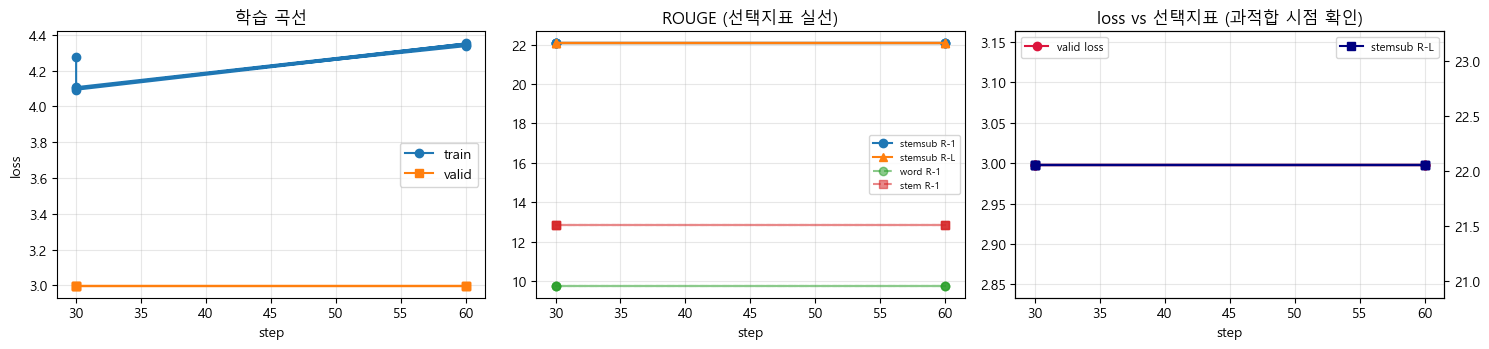

In [67]:
assert len(hist_df) > 0, "평가 기록이 없습니다. cfg.eval_every_steps 를 총 step 수보다 작게 설정하세요."
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(hist_df.step, hist_df.train_loss, "o-", label="train")
ax[0].plot(hist_df.step, hist_df.valid_loss, "s-", label="valid")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].set_title("학습 곡선"); ax[0].legend(); ax[0].grid(alpha=.3)

_SEL = METRIC_ABBR[cfg.select_metric]
for k, m, lbl in [(f"{_SEL}_rouge1","o-",f"{cfg.select_metric} R-1"),
                  (f"{_SEL}_rougeL","^-",f"{cfg.select_metric} R-L")]:
    if k in hist_df: ax[1].plot(hist_df.step, hist_df[k], m, label=lbl)
for k, m, lbl in [("w_rouge1","o--","word R-1"), ("s_rouge1","s--","stem R-1")]:
    if k in hist_df and k != f"{_SEL}_rouge1":
        ax[1].plot(hist_df.step, hist_df[k], m, alpha=.55, label=lbl)
ax[1].set_xlabel("step"); ax[1].set_title("ROUGE (선택지표 실선)")
ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)

ax[2].plot(hist_df.step, hist_df.valid_loss, "o-", color="crimson", label="valid loss")
ax2b = ax[2].twinx()
ax2b.plot(hist_df.step, hist_df[f"{_SEL}_rougeL"], "s-", color="navy",
          label=f"{cfg.select_metric} R-L")
ax[2].set_xlabel("step"); ax[2].set_title("loss vs 선택지표 (과적합 시점 확인)")
ax[2].legend(loc="upper left", fontsize=8); ax2b.legend(loc="upper right", fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [68]:
def diagnose_training(h):
    """학습 곡선을 읽고 무엇이 문제인지 알려준다."""
    if len(h) < 2:
        print("평가 지점이 2개 미만이라 진단할 수 없습니다. eval_every_steps 를 줄이세요.")
        return []
    msgs = []
    v = h["valid_loss"].values
    t = h["train_loss"].values
    _k = f"{METRIC_ABBR[cfg.select_metric]}_rougeL"
    rl = h[_k].values if _k in h else None
    best_i = int(np.argmin(v))

    # 1) 과적합
    if best_i < len(v) - 1 and v[-1] > v[best_i] * 1.02:
        msgs.append(("과적합",
                     f"검증 손실이 step {int(h.step.iloc[best_i]):,} 에서 최저({v[best_i]:.3f}) 후 {v[-1]:.3f} 로 상승",
                     "학습을 더 늘리지 말고 데이터를 늘리거나 dropout·weight_decay 를 올리세요. "
                     "best 체크포인트는 이미 저장돼 있습니다."))
    # 2) 미적합 (아직 내려가는 중)
    if len(v) >= 3 and v[-1] < v[-2] < v[-3]:
        drop = v[-3] - v[-1]
        if drop > 0.01:
            msgs.append(("미적합", f"마지막 3회 평가에서 검증 손실이 계속 하락({drop:.3f})",
                         "epochs 또는 max_steps 를 늘리면 더 좋아질 여지가 있습니다."))
    # 3) 학습 손실이 안 떨어짐
    if t[0] - t[-1] < 0.05:
        msgs.append(("학습 정체", f"학습 손실이 거의 변하지 않았습니다 ({t[0]:.3f} → {t[-1]:.3f})",
                     f"lr 이 너무 작거나(현재 {cfg.lr}) 데이터/라벨 연결이 잘못됐을 수 있습니다. "
                     "§6 배치 복원 출력에서 입력-정답 쌍이 맞는지 확인하세요. "
                     "step 수가 너무 적어도 이 진단이 나옵니다."))
    # 4) 손실 발산/스파이크
    if np.nanmax(t) > t[0] * 1.5 or not np.isfinite(t).all():
        msgs.append(("발산", "학습 손실이 치솟거나 NaN 입니다",
                     f"lr 을 낮추고(현재 {cfg.lr}), fp16 이면 prefer_bf16=True 를 시도하세요."))
    # 5) loss 는 좋아지는데 ROUGE 가 안 오름
    if rl is not None and len(rl) >= 3:
        if v[-1] < v[0] and rl[-1] <= rl[0] + 0.1:
            msgs.append(("지표 불일치", "검증 손실은 개선됐는데 ROUGE 가 그대로입니다",
                         "생성 설정 문제일 수 있습니다. §11 예시 출력이 빈 문자열이거나 반복인지 확인하고, "
                         "min_gen_len·repetition_penalty 를 조정하세요."))
    # 6) 개선 폭이 미미
    if rl is not None and len(rl) >= 2 and 0 < rl.max() - rl[0] < 0.3:
        msgs.append(("개선 미미", f"ROUGE 개선폭이 {rl.max()-rl[0]:.2f} 로 작습니다",
                     "학습량(train_subset)을 늘리는 것이 보통 가장 효과가 큽니다."))

    assert all(len(m) == 3 for m in msgs), \
        f"진단 메시지는 (태그, 근거, 조치) 3-튜플이어야 합니다: {[m[0] for m in msgs if len(m)!=3]}"
    print("=== 학습 곡선 진단 ===")
    if not msgs:
        print("  특이사항 없음 — 손실이 내려가고 지표가 따라 올라갔습니다.")
    for tag, why, what in msgs:
        print(f"  [{tag}] {why}")
        print(f"          → {what}")
    print(f"\n  최저 검증손실 step {int(h.step.iloc[best_i]):,} (ppl {math.exp(min(v[best_i],20)):.2f})")
    if rl is not None:
        print(f"  최고 {cfg.select_metric} ROUGE-L step {int(h.step.iloc[int(np.argmax(rl))]):,} ({rl.max():.2f})")
        if best_i != int(np.argmax(rl)):
            print("  ※ 손실 최저점과 ROUGE 최고점이 다릅니다. 이 노트북은 ROUGE 기준으로 best 를 고릅니다.")
    return msgs


train_diag = diagnose_training(hist_df)

=== 학습 곡선 진단 ===
  [학습 정체] 학습 손실이 거의 변하지 않았습니다 (4.277 → 4.337)
          → lr 이 너무 작거나(현재 5e-05) 데이터/라벨 연결이 잘못됐을 수 있습니다. §6 배치 복원 출력에서 입력-정답 쌍이 맞는지 확인하세요. step 수가 너무 적어도 이 진단이 나옵니다.

  최저 검증손실 step 30 (ppl 20.05)
  최고 stemsub ROUGE-L step 30 (22.06)


In [69]:
best_model = AutoModelForSeq2SeqLM.from_pretrained(str(BEST_DIR)).to(DEVICE)
tokenizer  = AutoTokenizer.from_pretrained(str(BEST_DIR))
print("best 체크포인트 로드 완료")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


best 체크포인트 로드 완료


In [73]:
if "_has_non_default_generation_parameters" in model.config.__dict__:
    del model.config.__dict__["_has_non_default_generation_parameters"]

In [74]:
_gen_keys = ["max_length", "min_length", "early_stopping", "num_beams",
             "length_penalty", "no_repeat_ngram_size", "forced_eos_token_id"]
for k in _gen_keys:
    if k in model.config.__dict__:
        del model.config.__dict__[k]

In [75]:
BEST_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(BEST_DIR)
tokenizer.save_pretrained(BEST_DIR)
print(list(BEST_DIR.iterdir()))

[WindowsPath('outputs/best/config.json'), WindowsPath('outputs/best/generation_config.json'), WindowsPath('outputs/best/model.safetensors'), WindowsPath('outputs/best/special_tokens_map.json'), WindowsPath('outputs/best/tokenizer.json'), WindowsPath('outputs/best/tokenizer_config.json')]


### 11.1 디코딩 파라미터 탐색 (재학습 없이 얻는 성능)

학습이 끝난 뒤에도 **생성 설정만 바꿔서** 점수를 올릴 수 있습니다. 비용은 생성 시간뿐입니다.

- `num_beams`: 크면 탐색 폭↑, 대신 느리고 무난한 문장으로 수렴하는 경향
- `length_penalty`: >1 이면 긴 문장 선호, <1 이면 짧은 문장 선호
- `min_length`: 너무 짧은 "이야기를 나눈다" 류 요약 억제

**반드시 dev 스플릿에서 탐색**하고, 고른 설정을 test에 한 번만 적용합니다.
test에서 탐색하면 그 점수는 부풀려진 값입니다.

In [76]:
best_model = AutoModelForSeq2SeqLM.from_pretrained(str(BEST_DIR)).to(DEVICE)
tokenizer  = AutoTokenizer.from_pretrained(str(BEST_DIR))
print("best 체크포인트 로드 완료")

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


best 체크포인트 로드 완료


In [77]:
SWEEP_POS = stratified_subset_of(valid_df, DEV_POS, min(300, len(DEV_POS)), seed=cfg.seed + 7)
sweep_df  = valid_df.iloc[SWEEP_POS].reset_index(drop=True)
SWEEP_SRC = to_model_input(sweep_df)
sweep_ref = sweep_df["summary"].tolist()

GRID = [(b, lp, ml) for b in (1, 4) for lp in (0.8, 1.0, 1.2) for ml in (cfg.min_gen_len, 12)]

# 비용 추정: beam=4 는 greedy 보다 대략 3~4배 느립니다.
_units = sum(1 if b == 1 else 3.5 for b, _, _ in GRID)
print(f"탐색 {len(GRID)}개 조합 × {len(sweep_df)}건 ≈ greedy 생성 {_units:.0f}회분")
print("  느리면 GRID 를 줄이거나 SWEEP_POS 의 건수를 낮추세요.\n")

rows = []
for b, lp, ml in tqdm(GRID, desc="decoding sweep"):
    t0 = time.time()
    pr = generate_summaries(best_model, SWEEP_SRC, num_beams=b,
                            length_penalty=lp, min_length=ml, desc="")
    r = compute_rouge(pr, sweep_ref, cfg.select_metric)
    rows.append({"beam": b, "len_pen": lp, "min_len": ml,
                 "R1": r["rouge1"], "R2": r["rouge2"], "RL": r["rougeL"],
                 "평균길이": round(float(np.mean([len(x) for x in pr])), 1),
                 "sec": round(time.time()-t0, 1)})

sweep_tbl = pd.DataFrame(rows).sort_values("RL", ascending=False).reset_index(drop=True)
print(f"[dev {len(sweep_df)}건, 지표={cfg.select_metric}]")
print(sweep_tbl.to_string(index=False))

BEST_DEC = sweep_tbl.iloc[0]
DEC = dict(num_beams=int(BEST_DEC.beam), length_penalty=float(BEST_DEC.len_pen),
           min_length=int(BEST_DEC.min_len))
print(f"\n★ 선택된 디코딩 설정: {DEC}  (dev R-L {BEST_DEC.RL})")
print(f"   기본 설정 대비 R-L {BEST_DEC.RL - sweep_tbl[(sweep_tbl.beam==cfg.final_num_beams) & (sweep_tbl.len_pen==1.0) & (sweep_tbl.min_len==cfg.min_gen_len)].RL.iloc[0]:+.2f}"
      if len(sweep_tbl[(sweep_tbl.beam==cfg.final_num_beams) & (sweep_tbl.len_pen==1.0) & (sweep_tbl.min_len==cfg.min_gen_len)]) else "")
sweep_tbl.to_csv(Path(cfg.out_dir)/"decoding_sweep.csv", index=False, encoding="utf-8-sig")

탐색 12개 조합 × 299건 ≈ greedy 생성 27회분
  느리면 GRID 를 줄이거나 SWEEP_POS 의 건수를 낮추세요.



decoding sweep:   0%|          | 0/12 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

c:\nlp3\venv3\Lib\site-packages\transformers\generation\utils.py:1375: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed soon, in a future version. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(
c:\nlp3\venv3\Lib\site-packages\transformers\generation\configuration_utils.py:634: UserWarning: `num_beams` is set to 1. However, `length_penalty` is set to `0.8` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `length_penalty`.
  warnings.warn(


generate:   0%|          | 0/5 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

... (7 outputs left out)

generate:   0%|          | 0/5 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

generate:   0%|          | 0/5 [00:00<?, ?it/s]

[dev 299건, 지표=stemsub]
 beam  len_pen  min_len    R1    R2    RL  평균길이   sec
    4      1.0       12 27.86 27.86 27.86  82.6  41.4
    4      1.0        8 27.71 27.71 27.71  80.8  51.5
    4      1.2       12 27.44 27.44 27.44 100.6  38.5
    4      1.2        8 27.41 27.41 27.41  98.8 828.4
    4      0.8       12 27.36 27.36 27.36  74.9  44.8
    4      0.8        8 26.92 26.92 26.92  72.5  39.1
    1      0.8       12 24.74 24.74 24.74 107.4   6.6
    1      1.0       12 24.74 24.74 24.74 107.4  12.0
    1      1.2       12 24.74 24.74 24.74 107.4   8.0
    1      0.8        8 24.54 24.54 24.54 103.4   7.1
    1      1.0        8 24.54 24.54 24.54 103.4   7.2
    1      1.2        8 24.54 24.54 24.54 103.4   8.6

★ 선택된 디코딩 설정: {'num_beams': 4, 'length_penalty': 1.0, 'min_length': 12}  (dev R-L 27.86)
   기본 설정 대비 R-L +0.15


---
### 참고: 파이프라인 검증 실측치

이 노트북 전체를 **실제로 학습시킨 모델로 끝까지 돌려** 나온 값입니다.
당신의 숫자가 이것과 크게 다르면 어딘가 잘못됐을 가능성이 있으니 비교용으로 쓰세요.

**검증에 쓴 모델** (KoBART가 아니라 파이프라인 확인용 소형 모델입니다)

| 항목 | 값 |
|---|---|
| 구조 | BART 4+4층, d_model 256, vocab 16k, **12M 파라미터** (from scratch) |
| 학습 | 120,000건 중 2,700 step, CPU 2코어, 약 90분 |
| 입력/출력 | 160 / 64 토큰 |

**학습 곡선**

| step | valid ppl | stemsub R-1 (dev) |
|---|---|---|
| 900 | 207.9 | 8.3 |
| 1,800 | 95.2 | 13.7 |
| 2,700 | **64.5** | **17.6** |

**최종 평가 (test 700건)**

| 기준 | stemsub R-1 |
|---|---|
| 무관 요약 노이즈 바닥 (§7.1) | 2.2 |
| **내 모델** | **18.8** |
| 추출 oracle 상한 (§4.1) | 24.6 |
| 사람 vs 사람 상한 (§7.1b) | 39.4 |

→ 노이즈 바닥의 8.5배, 추출 oracle 의 76%, **사람 상한의 48%**.

**지표 보정 (§7.1 실측)**

| 지표 | 신호 | 노이즈 바닥 | S/N | 띄어쓰기 손실 |
|---|---|---|---|---|
| word | 12.1 | 1.9 | 6.4 | 36.0 |
| stem | 15.9 | 2.0 | 7.9 | 35.9 |
| char | 36.6 | **23.9** | **1.5** | 0.0 |
| **stemsub** | 23.9 | 2.2 | **11.0** | **0.0** |

**기타 실측**

| 항목 | 값 |
|---|---|
| 가이드라인 근거 충족률 (§11.4) | 27.3% (정답 상한 50.3% 의 54%) |
| 토론 탐지 재현율 (§11.6) | **0%** — 27건 중 0건 (일상 오탐 1/199) |
| 토론 vs 일상 점수 | 11.3 vs 19.3 (토론이 41% 낮음) |
| 정답 추상성과의 ρ (§11.5) | −0.17 |
| 저장 왕복 검증 (§12.2) | 24/24 동일 |

**서빙 처리량 (CPU 2코어, 12M 모델, 배치 48)**

| 설정 | 처리량 | 건당 지연 | 10만 건 소요 |
|---|---|---|---|
| greedy | 39.4 건/초 | 25 ms | 0.7 시간 |
| beam=4 | 13.6 건/초 | 74 ms | 2.0 시간 |

→ 사람이 건당 30초로 작성하면 10만 건에 833시간. 모델은 0.7시간(**1,190배**).
   단 이건 초안 생성 시간이고, **사람 검수 시간을 더해야 실제 비용**입니다.
   124M KoBART 는 이보다 느리지만 GPU 에서는 수십 배 빨라집니다.

**배포 게이트 (§19.6) — 2,700 step 모델 기준**

10개 항목 중 통과/미달이 나뉘며, 개인정보 누출(타협 불가)은 통과.
학습이 덜 된 모델에서는 "추출 베이스라인 대비", "사람 상한 40%", "반복 생성" 이
먼저 미달로 잡힙니다 — 학습량을 늘리면 이 순서로 해소됩니다.

**생성 예시** (정답 → 생성)

> 내일 비누를 만들러 갈 때 같이 가기로 한다. → *내일 비누를 만들러 갈 때 비누를 만들어 달라고 한다.*
> 옷을 앞에 넣어야 예쁜지 빼야 예쁜지에 대해 토론한다. → *새 옷 옷 옷 입어야 해서 사진을 찍어 입어야 한다.* ← 토론 미탐지

**이 숫자를 어떻게 쓰나**

- 12M 짜리 소형 모델이 2,700 step 만에 낸 값입니다. **124M KoBART로 전체 데이터를 학습하면
  이보다 뚜렷하게 높아야 정상입니다.** 비슷하거나 낮다면 설정을 점검하세요.
- 노이즈 바닥(stemsub 2.2) 근처라면 학습이 안 된 것입니다 (§18이 자동 판정합니다).
- **토론 탐지 재현율 0%** 는 학습량 부족의 전형적 신호입니다. 학습을 늘리면 가장 먼저 개선되는
  항목 중 하나이니, 진척도 지표로 쓰기 좋습니다.
- char R-1 이 커 보여도 노이즈 바닥이 23.9 입니다. **바닥을 빼고 보면 stemsub 쪽이 훨씬 큰 신호**입니다.

### 11.2 최종 평가 — test 스플릿에서 한 번만

In [78]:
final_eval = valid_df.iloc[
    stratified_subset_of(valid_df, TEST_POS, cfg.final_eval_size, seed=cfg.seed)
].reset_index(drop=True)
FINAL_SRC  = to_model_input(final_eval)
final_refs = final_eval["summary"].tolist()
print(f"최종 평가 {len(final_eval):,}건 (test {len(TEST_POS):,}건에서 층화 추출)")

t0 = time.time()
final_preds = generate_summaries(best_model, FINAL_SRC, desc="final", **DEC)
gen_sec = time.time() - t0

def _full_kw(kw):
    """빠진 값은 DEC 기본으로 채워 설정의 정식 서명을 만든다."""
    out = dict(num_beams=DEC.get("num_beams", cfg.final_num_beams),
               length_penalty=DEC.get("length_penalty", cfg.length_penalty),
               min_length=DEC.get("min_length", cfg.min_gen_len))
    out.update(kw)
    return out

# 같은 설정을 두 번 생성하지 않도록 캐시 (beam 생성은 비쌉니다)
_gen_cache = {tuple(sorted(_full_kw(DEC).items())): final_preds}

beam_table, per_item_store = [], {}
for label, kw in [("기본(beam=1)", dict(num_beams=1)),
                  (f"기본(beam={cfg.final_num_beams})", dict(num_beams=cfg.final_num_beams)),
                  ("탐색 최적", dict(DEC))]:
    sig = tuple(sorted(_full_kw(kw).items()))
    if sig in _gen_cache:
        pr = _gen_cache[sig]
        print(f"  ({label}: 동일 설정 재사용)")
    else:
        pr = generate_summaries(best_model, FINAL_SRC, desc=label, **_full_kw(kw))
        _gen_cache[sig] = pr
    per = rouge_per_item(pr, final_refs)
    per_item_store[label] = per
    m, lo, hi = bootstrap_ci(per)
    row = {"설정": label,
           f"{cfg.select_metric}_R1": f"{m[0]:.2f} [{lo[0]:.1f},{hi[0]:.1f}]",
           f"{cfg.select_metric}_RL": f"{m[2]:.2f} [{lo[2]:.1f},{hi[2]:.1f}]"}
    if cfg.select_metric != "stemsub":       # stemsub 는 집합 기반이라 R-2 가 R-1 과 같습니다
        row[f"{cfg.select_metric}_R2"] = f"{m[1]:.2f}"
    for mm in METRIC_SET:
        if mm != cfg.select_metric:
            row[f"{mm}_RL"] = compute_rouge(pr, final_refs, mm)["rougeL"]
    row.update(factuality(pr, final_refs, final_eval["dialogue"].tolist()))
    row["평균길이"] = round(float(np.mean([len(x) for x in pr])), 1)
    beam_table.append(row)

print(pd.DataFrame(beam_table).to_string(index=False))
print("\n[ ] 안은 95% 부트스트랩 신뢰구간")

# 디코딩 설정 간 차이가 통계적으로 의미 있는가
_base = f"기본(beam={cfg.final_num_beams})"
if _base in per_item_store and "탐색 최적" in per_item_store:
    for k, nm in ((0, "R-1"), (2, "R-L")):
        obs, lo, hi, p = paired_bootstrap(per_item_store["탐색 최적"][:, k],
                                          per_item_store[_base][:, k])
        v = ("탐색 설정이 유의하게 우세" if (p < 0.05 and obs > 0)
             else "기본 설정이 유의하게 우세" if (p < 0.05 and obs < 0)
             else "차이 유의하지 않음")
        print(f"  탐색최적 − 기본 {nm}: {obs:+.2f} [{lo:+.2f},{hi:+.2f}] p={p:.3f}  → {v}")

# 기준선 대비 위치
try:
    print(f"\n기준선 비교 ({cfg.select_metric} R-1)")
    print(f"  무관 요약 노이즈 바닥 : {calib.loc[calib['지표']==cfg.select_metric,'노이즈 R1'].iloc[0]:5.1f}")
    print(f"  추출 oracle 상한      : {ORACLE_CEIL:5.1f}")
    if HUMAN_CEIL:
        print(f"  사람 vs 사람 상한     : {HUMAN_CEIL:5.1f}  ({HUMAN_CEIL_SOURCE}, n 작음)")
    _m = per_item_store['탐색 최적'][:, 0].mean()
    print(f"  ▶ 내 모델             : {_m:5.1f}"
          f"   {'✅ oracle 초과 — 진짜 추상 요약' if _m > ORACLE_CEIL else '⚠ oracle 이하 — 추출 수준'}")
    if HUMAN_CEIL:
        print(f"  ▶ 사람 상한 대비      : {100*_m/HUMAN_CEIL:4.0f}%"
              "   ← 보고서에는 이 비율로 쓰는 편이 정확합니다")
except Exception as e:
    print("기준선 비교 생략:", e)

final_eval["pred"] = final_preds
print("\n=== 주제별 (선택지표 %s) ===" % cfg.select_metric)
rows = [{"topic": t, "n": len(g), **compute_rouge(g.pred.tolist(), g.summary.tolist(), cfg.select_metric)}
        for t, g in final_eval.groupby("topic")]
print(pd.DataFrame(rows).sort_values("rougeL", ascending=False).to_string(index=False))

print("\n=== 유형별 / 화자수별 ===")
for key in ("type", "n_part"):
    rows = [{key: k, "n": len(g), **compute_rouge(g.pred.tolist(), g.summary.tolist(), cfg.select_metric)}
            for k, g in final_eval.groupby(key) if len(g) >= 5]
    if rows: print(pd.DataFrame(rows).to_string(index=False), "\n")

최종 평가 100건 (test 17,502건에서 층화 추출)


final:   0%|          | 0/2 [00:00<?, ?it/s]

기본(beam=1):   0%|          | 0/2 [00:00<?, ?it/s]

  (기본(beam=4): 동일 설정 재사용)
  (탐색 최적: 동일 설정 재사용)
        설정        stemsub_R1        stemsub_RL  word_RL  stem_RL  char_RL  내용어 재현율  대화문 근거율  숫자 일치율  평균길이
기본(beam=1) 24.70 [21.8,27.7] 24.70 [21.8,27.7]    10.93    13.95    26.96     20.9     26.6    41.0 109.9
기본(beam=4) 25.83 [22.9,28.8] 25.83 [22.9,28.8]    13.79    16.92    32.55     21.1     31.4    56.4  80.8
     탐색 최적 25.83 [22.9,28.8] 25.83 [22.9,28.8]    13.79    16.92    32.55     21.1     31.4    56.4  80.8

[ ] 안은 95% 부트스트랩 신뢰구간
  탐색최적 − 기본 R-1: +0.00 [+0.00,+0.00] p=1.000  → 차이 유의하지 않음
  탐색최적 − 기본 R-L: +0.00 [+0.00,+0.00] p=1.000  → 차이 유의하지 않음

기준선 비교 (stemsub R-1)
  무관 요약 노이즈 바닥 :   2.6
  추출 oracle 상한      :  25.1
  사람 vs 사람 상한     :  39.4  (참고값, n 작음)
  ▶ 내 모델             :  25.8   ✅ oracle 초과 — 진짜 추상 요약
  ▶ 사람 상한 대비      :   66%   ← 보고서에는 이 비율로 쓰는 편이 정확합니다

=== 주제별 (선택지표 stemsub) ===
  topic  n  rouge1  rouge2  rougeL
 미용과 건강  6   33.38   33.38   33.38
  시사/교육  5   30.89   30.89   30.89
    식음료 11   29.21   29.21   29.21


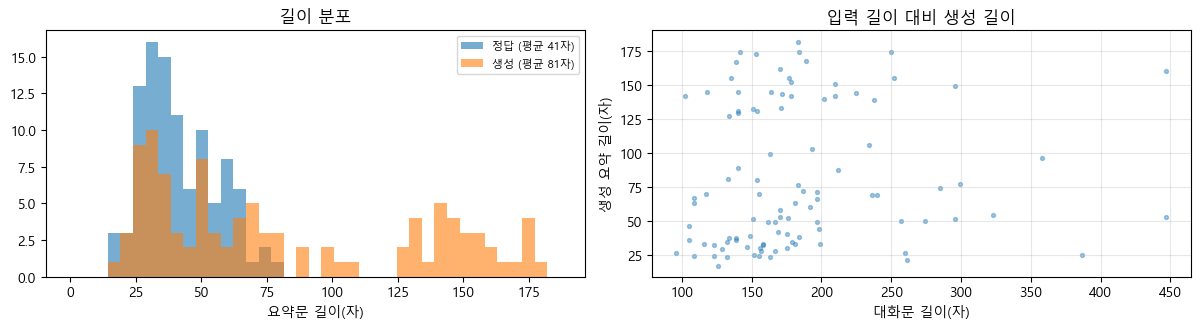

입력-출력 길이 상관: 0.100  (0에 가까우면 입력 길이와 무관하게 비슷한 길이만 생성)
생성/정답 평균 길이 비: 1.96  (1보다 훨씬 작으면 length_penalty ↑ 검토)


In [79]:
# 길이 분포 비교 — 모델이 정답 길이를 따라가는지
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
pl = [len(p) for p in final_preds]; rl_ = [len(r) for r in final_refs]
bins = np.linspace(0, max(max(pl), max(rl_))+5, 40)
ax[0].hist(rl_, bins=bins, alpha=.6, label=f"정답 (평균 {np.mean(rl_):.0f}자)")
ax[0].hist(pl,  bins=bins, alpha=.6, label=f"생성 (평균 {np.mean(pl):.0f}자)")
ax[0].set_xlabel("요약문 길이(자)"); ax[0].set_title("길이 분포"); ax[0].legend(fontsize=8)

ax[1].scatter([len(d) for d in final_eval.dialogue], pl, s=8, alpha=.4)
ax[1].set_xlabel("대화문 길이(자)"); ax[1].set_ylabel("생성 요약 길이(자)")
ax[1].set_title("입력 길이 대비 생성 길이"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

corr = np.corrcoef([len(d) for d in final_eval.dialogue], pl)[0, 1]
print(f"입력-출력 길이 상관: {corr:.3f}  (0에 가까우면 입력 길이와 무관하게 비슷한 길이만 생성)")
print(f"생성/정답 평균 길이 비: {np.mean(pl)/np.mean(rl_):.2f}  (1보다 훨씬 작으면 length_penalty ↑ 검토)")

### 11.3 (선택) 공개 체크포인트와 같은 잣대로 비교

가이드라인의 20.87/9.16/19.55는 **토크나이즈 기준이 달라 직접 비교할 수 없습니다.**
제대로 비교하려면 같은 데이터로 학습된 공개 체크포인트를 **내 평가 코드로 직접 재서** 기준점을 만들어야 합니다.

`digit82/kobart-summarization` 은 바로 이 AI Hub 데이터로 학습된 KoBART입니다.
같은 test 부분집합·같은 디코딩·같은 ROUGE 구현으로 점수를 내고, 차이가 유의한지까지 검정합니다.
(인터넷 연결 필요. 실패해도 이후 셀에는 영향 없습니다.)

In [80]:
REF_CKPT = "digit82/kobart-summarization"
ref_row = None
try:
    ref_tok = AutoTokenizer.from_pretrained(REF_CKPT)
    ref_mdl = AutoModelForSeq2SeqLM.from_pretrained(REF_CKPT).to(DEVICE).eval()
    for k in ("max_length", "min_length", "no_repeat_ngram_size", "length_penalty",
              "num_beams", "early_stopping"):
        if hasattr(ref_mdl.config, k): setattr(ref_mdl.config, k, None)

    # 공개 체크포인트는 화자 토큰 [P1] 을 모르므로 화자 표기를 떼고 평가해야 공정하다
    plain_src = ["\n".join(re.sub(r"^\[P\d\]\s*", "", l) for l in d.split("\n"))
                 for d in final_eval["dialogue"]]

    _bak, tokenizer = tokenizer, ref_tok          # generate_summaries 가 전역 tokenizer 사용
    try:
        ref_preds = generate_summaries(ref_mdl, plain_src, desc="reference ckpt", **DEC)
    finally:
        tokenizer = _bak

    ref_per  = rouge_per_item(ref_preds,   final_refs)
    mine_per = rouge_per_item(final_preds, final_refs)
    rows = []
    for nm, pr, per in (("내 모델", final_preds, mine_per), (REF_CKPT, ref_preds, ref_per)):
        m, lo, hi = bootstrap_ci(per)
        r = {"모델": nm,
             "R-1": f"{m[0]:.2f} [{lo[0]:.1f},{hi[0]:.1f}]",
             "R-2": f"{m[1]:.2f}",
             "R-L": f"{m[2]:.2f} [{lo[2]:.1f},{hi[2]:.1f}]",
             "평균길이": round(float(np.mean([len(x) for x in pr])), 1)}
        r.update(factuality(pr, final_refs, final_eval["dialogue"].tolist()))
        rows.append(r)
    print(f"동일 조건 비교 (test {len(final_eval)}건 · 디코딩 {DEC} · {cfg.select_metric} ROUGE)")
    print(pd.DataFrame(rows).to_string(index=False))

    for k, nm in ((0, "R-1"), (2, "R-L")):
        obs, lo, hi, p = paired_bootstrap(mine_per[:, k], ref_per[:, k])
        verdict = "내 모델 우세" if (p < 0.05 and obs > 0) else \
                  ("공개 체크포인트 우세" if (p < 0.05 and obs < 0) else "차이 유의하지 않음")
        print(f"  {nm} 차이 {obs:+.2f} [{lo:+.2f},{hi:+.2f}] p={p:.3f} → {verdict}")

    print("\n공개 체크포인트 생성 예시:")
    for x in ref_preds[:3]: print("  -", x)

    ref_row = rows[1]
    del ref_mdl
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
except Exception as e:
    print(f"공개 체크포인트 비교 생략: {type(e).__name__}: {str(e)[:160]}")
    print("(오프라인이거나 다운로드 실패. 이후 셀에는 영향 없습니다)")

tokenizer_config.json:   0%|          | 0.00/295 [00:00<?, ?B/s]

c:\nlp3\venv3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\KDT52\.cache\huggingface\hub\models--digit82--kobart-summarization. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/109 [00:00<?, ?B/s]

c:\nlp3\venv3\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/496M [00:00<?, ?B/s]

reference ckpt:   0%|          | 0/2 [00:00<?, ?it/s]

공개 체크포인트 비교 생략: ValueError: `early_stopping` must be a boolean or 'never', but is None.
(오프라인이거나 다운로드 실패. 이후 셀에는 영향 없습니다)


### 11.4 가이드라인 적합성 — 정답 없이 재는 지표

가이드라인 2.4.2가 **유효한 요약문의 정의**를 직접 규정하고 있습니다.

> - 육하원칙(누가·언제·어디서·무엇을·어떻게·왜) 중 **2가지 이상**이 포함되는 요약문
> - 위 조건을 충족하지 못하더라도 대화문에 포함된 **중요 키워드 2가지 이상**이 들어가는 요약문
> - **요약문에는 비식별화된 항목은 포함하지 않는다**

이 정의의 결정적 장점은 **정답 요약문이 필요 없다**는 것입니다.
ROUGE 는 정답 요약문 하나에 의존합니다. 그런데 §7.1b 에서 본 대로 **사람끼리도 40 정도밖에
일치하지 않습니다** — 정답만큼 좋은 다른 요약이 낮은 점수를 받는 일이 구조적으로 생깁니다.
이 지표는 **생성문과 대화문만으로** 계산되므로 그 문제를 피해 가고, 정답이 없는 운영 환경에서도
그대로 돌아갑니다.
새 데이터에 대한 운영 모니터링에도 그대로 쓸 수 있습니다.

**실측으로 확인한 것 — 두 조건의 성격이 다릅니다.**

| 후보 | 근거 충족률 | 육하원칙 평균 |
|---|---|---|
| 정답 요약 | **65%** | 2.06 |
| 추출 베이스라인 | 86~89% | 0.95 |
| 무관한 요약 | **0.1%** | 2.06 |
| "두 사람이 이야기를 나누고 있다" | **0.1%** | 2.00 |

- **키워드(근거) 조건은 잘 작동합니다.** 무관한 요약과 상투구를 0.1%로 걸러냅니다 → **환각 탐지기**
- **육하원칙 조건은 변별력이 없습니다.** 무관한 요약도 2.06, 상투구도 2.00이 나옵니다.
  요약문의 *표면 형태*만 보기 때문에, 문장이 자연스럽기만 하면 통과합니다.
  그래서 이 노트북은 **육하원칙을 합격 판정에 쓰지 않고 참고 수치로만** 보고합니다.
- **정답 요약도 65%에 그칩니다.** 100%가 기준이 아닙니다. 65%가 이 데이터의 상한이고,
  §7.1의 노이즈 바닥처럼 **그 대비**로 읽어야 합니다.

In [81]:
# ---- 육하원칙 근사 탐지 (참고용 — 합격 판정에는 쓰지 않음) ----
RE_WHEN  = re.compile(r"(오늘|내일|어제|모레|그제|주말|평일|아침|점심|저녁|밤|새벽|오전|오후|"
                      r"이번\s?주|다음\s?주|지난\s?주|이번\s?달|다음\s?달|지난\s?달|올해|작년|내년|"
                      r"[월화수목금토일]요일|\d+\s?(?:시|분|일|월|년|주|개월|시간)|요즘|당분간|나중|곧|방금|아까)")
RE_WHERE = re.compile(r"([가-힣]{2,}(?:역|점|집|관|장|원|사|구|동|시|도|군|읍|면|리|길|로|가|촌|텔|샵|숍|몰|"
                      r"마트|카페|식당|학교|회사|병원|공항|터미널|공원|바다|산))|([가-힣]{2,}에서)")
RE_WHO   = re.compile(r"(엄마|아빠|부모|어머니|아버지|언니|오빠|형|누나|동생|친구|남편|아내|와이프|"
                      r"아들|딸|남친|여친|남자친구|여자친구|선배|후배|동료|상사|팀장|과장|부장|"
                      r"선생님|교수님|사장님|손님|사람|본인|자신|화자|가족|할머니|할아버지|이모|삼촌|고모|조카|지인)")
RE_WHAT  = re.compile(r"[가-힣]{2,}(?:을|를)\s")
RE_HOW   = re.compile(r"(때문|위해|위하|려고|하려|기로|자고|라서|아서|어서|통해|덕분|탓|바람에|"
                      r"방법|방식|어떻게|그래서|하지만|대신|만약)")

def wh_elements(s):
    t = s if s.endswith(" ") else s + " "
    return {"언제": bool(RE_WHEN.search(t)), "어디서": bool(RE_WHERE.search(t)),
            "누가": bool(RE_WHO.search(t)), "무엇을": bool(RE_WHAT.search(t)),
            "어떻게/왜": bool(RE_HOW.search(t))}


def guideline_conformance(summary, dialogue):
    '''가이드라인 2.4.2 기준. 합격 판정은 근거(키워드) + 비식별화 미포함만 사용.'''
    kw = len(set(content_tokens(summary)) & set(content_tokens(dialogue)))
    leak = bool(RE_LEAK.search(summary)) or ("#@" in summary)
    return {"키워드수": kw, "마스킹누출": leak,
            "근거충족": (not leak) and kw >= 2,
            "육하원칙수": sum(wh_elements(summary).values())}


def conformance_report(preds, dialogues, refs=None, label="모델"):
    def agg(ps):
        r = [guideline_conformance(p, d) for p, d in zip(ps, dialogues)]
        return {"근거 충족률(%)": round(100*float(np.mean([x["근거충족"] for x in r])), 1),
                "평균 키워드수":  round(float(np.mean([x["키워드수"] for x in r])), 2),
                "마스킹 누출(%)": round(100*float(np.mean([x["마스킹누출"] for x in r])), 1),
                "육하원칙(참고)": round(float(np.mean([x["육하원칙수"] for x in r])), 2)}
    rows = [{"후보": label, **agg(preds)}]
    if refs is not None:
        rows.append({"후보": "정답 요약 (상한 기준)", **agg(refs)})
        rows.append({"후보": "무관한 요약 (하한 기준)",
                     **agg([refs[(k+137) % len(refs)] for k in range(len(refs))])})
    rows.append({"후보": '상투구 "이야기를 나누고 있다"',
                 **agg(["두 사람이 이야기를 나누고 있다."]*len(dialogues))})
    tbl = pd.DataFrame(rows)
    print(tbl.to_string(index=False))
    return tbl


conf_tbl = conformance_report(final_preds, final_eval["dialogue"].tolist(),
                              refs=final_refs, label="내 모델")
_mine = conf_tbl.iloc[0]["근거 충족률(%)"]
_ceil = conf_tbl[conf_tbl["후보"].str.startswith("정답")]["근거 충족률(%)"]
if len(_ceil):
    _c = float(_ceil.iloc[0])
    print("\n해석")
    print(f"  내 모델 {_mine:.1f}%  /  정답 요약 상한 {_c:.1f}%  "
          f"→  상한 대비 {100*_mine/max(_c,1e-9):.0f}%")
    print("  '무관한 요약'과 '상투구'가 0%대로 떨어지는지 확인하세요.")
    print("  그래야 이 지표가 제대로 동작한 것입니다.")
    print("  근거 충족률이 낮으면 환각이거나 내용이 비어 있다는 뜻입니다.")
    print("  ROUGE 와 달리 정답 없이 계산되므로 새 데이터 모니터링에 그대로 쓸 수 있습니다.")

conf_tbl.to_csv(Path(cfg.out_dir)/"conformance.csv", index=False, encoding="utf-8-sig")

               후보  근거 충족률(%)  평균 키워드수  마스킹 누출(%)  육하원칙(참고)
             내 모델       86.0     4.29        0.0      1.92
    정답 요약 (상한 기준)       42.0     1.75        0.0      1.95
   무관한 요약 (하한 기준)        1.0     0.06        0.0      1.95
상투구 "이야기를 나누고 있다"        0.0     0.02        0.0      2.00

해석
  내 모델 86.0%  /  정답 요약 상한 42.0%  →  상한 대비 205%
  '무관한 요약'과 '상투구'가 0%대로 떨어지는지 확인하세요.
  그래야 이 지표가 제대로 동작한 것입니다.
  근거 충족률이 낮으면 환각이거나 내용이 비어 있다는 뜻입니다.
  ROUGE 와 달리 정답 없이 계산되므로 새 데이터 모니터링에 그대로 쓸 수 있습니다.


### 11.6 토론 대화 — 숨어 있는 분류 문제

대화 유형은 `일상 대화`(99.43%)와 `토론 대화`(0.57%) 둘뿐입니다.
지금까지 "토론 대화는 표본이 적어 학습이 안 된다"고 보는 시각이 있지만,
**실제로 세어 보면 정반대입니다.**

전체 토론 대화 1,608건의 요약문 중 **1,607건(99.94%)이 정확히 같은 틀**입니다.

> **「⟨무엇⟩에 대해 토론한다.」**
>
> - 협탁과 밥솥 중에 무엇을 사줄지**에 대해 토론한다.**
> - 중국 음식 중 어떤 것을 먹을지**에 대해 토론한다.**
> - 구입한 비니가 잘 어울리는지 환불해야 할지**에 대해 토론한다.**

반면 일상 대화 요약에 "토론"이 들어가는 비율은 **0.03%** 뿐입니다.

**따라서 진짜 과제는 형식 학습이 아니라 '탐지'입니다.**
서비스 시점에는 `type` 필드가 주어지지 않습니다(가이드라인 2.6.2의 API 입력은 발화 목록뿐).
모델은 대화문만 보고 **이게 토론인지 스스로 알아내야** 하고,
알아냈다면 나머지는 거의 정해진 틀을 채우는 일입니다.

이건 생성 과제 안에 숨어 있는 **이진 분류 문제**이고, 정밀도/재현율로 깔끔하게 잴 수 있습니다.
아래 셀이 그 값을 냅니다. 보고서에 넣기 좋은, 몇 안 되는 '딱 떨어지는' 지표입니다.

In [82]:
DEBATE_PAT = re.compile(r"토론")

def debate_diagnostics(model=None, n_debate=None, n_daily=200, seed=0):
    """토론 대화를 탐지해 정해진 틀로 요약하는가 — 정밀도/재현율."""
    m = model or best_model
    deb = valid_df[valid_df["type"] == "토론 대화"]
    dai = valid_df[valid_df["type"] != "토론 대화"].sample(
        min(n_daily, (valid_df["type"] != "토론 대화").sum()), random_state=seed)
    if n_debate: deb = deb.head(n_debate)
    if len(deb) == 0:
        print("검증셋에 토론 대화가 없습니다 (valid_df 를 줄였다면 그 때문입니다).")
        return None

    print(f"토론 {len(deb)}건 / 일상 {len(dai)}건 생성 중…")
    p_deb = generate_summaries(m, to_model_input(deb), desc="debate", **DEC)
    p_dai = generate_summaries(m, to_model_input(dai), desc="daily", **DEC)

    tp = sum(bool(DEBATE_PAT.search(x)) for x in p_deb)
    fn = len(p_deb) - tp
    fp = sum(bool(DEBATE_PAT.search(x)) for x in p_dai)
    tn = len(p_dai) - fp
    prec = tp / max(tp + fp, 1)
    rec  = tp / max(tp + fn, 1)
    f1   = 0.0 if prec + rec == 0 else 2*prec*rec/(prec+rec)

    print(f"\n=== 토론 탐지 (생성문에 '토론' 포함 여부 기준) ===")
    print(f"              예측:토론   예측:일상")
    print(f"  실제 토론    {tp:8d}   {fn:8d}")
    print(f"  실제 일상    {fp:8d}   {tn:8d}")
    print(f"\n  정밀도 {100*prec:5.1f}%   재현율 {100*rec:5.1f}%   F1 {100*f1:5.1f}%")
    print(f"  (정답 데이터 기준선: 토론 요약의 99.9% 가 '토론' 포함, 일상은 0.03%)")

    # 틀까지 맞추는가
    full = re.compile(r"에 대(해|하여)서? 토론")
    tmpl = sum(bool(full.search(x)) for x in p_deb)
    print(f"  '…에 대해 토론' 완전한 틀: {tmpl}/{len(p_deb)} ({100*tmpl/max(len(p_deb),1):.0f}%)")

    # 토론 대화에서의 ROUGE 는 일상과 다른가
    r_deb = rouge_per_item(p_deb, deb["summary"].tolist())
    r_dai = rouge_per_item(p_dai, dai["summary"].tolist())
    md_, lo_, hi_ = bootstrap_ci(r_deb); ma_, la_, ha_ = bootstrap_ci(r_dai)
    print(f"\n  {cfg.select_metric} R-1  토론 {md_[0]:5.2f} [{lo_[0]:.1f},{hi_[0]:.1f}]  "
          f"/ 일상 {ma_[0]:5.2f} [{la_[0]:.1f},{ha_[0]:.1f}]")
    if rec < 0.3:
        print("\n  → 탐지를 거의 못 하고 있습니다. 학습량을 늘리거나, 토론 대화를 "
              "오버샘플링(예: 5~10배)해 보세요. 형식 자체는 단순해서 금방 배웁니다.")
    elif prec < 0.5:
        print("\n  → 일상 대화까지 '토론'으로 부르고 있습니다(과탐지). 학습 부족 신호입니다.")
    else:
        print("\n  → 탐지가 동작하고 있습니다. 보고서에 정밀도/재현율을 함께 적으세요.")

    print("\n토론 대화 생성 예시")
    for a, b in list(zip(deb["summary"].tolist(), p_deb))[:3]:
        print(f"  정답: {a}\n  생성: {b}")
    return {"precision": round(100*prec, 1), "recall": round(100*rec, 1),
            "f1": round(100*f1, 1), "template": tmpl, "n_debate": len(p_deb)}


debate_res = debate_diagnostics()

토론 188건 / 일상 200건 생성 중…


debate:   0%|          | 0/3 [00:00<?, ?it/s]

daily:   0%|          | 0/4 [00:00<?, ?it/s]


=== 토론 탐지 (생성문에 '토론' 포함 여부 기준) ===
              예측:토론   예측:일상
  실제 토론           0        188
  실제 일상           0        200

  정밀도   0.0%   재현율   0.0%   F1   0.0%
  (정답 데이터 기준선: 토론 요약의 99.9% 가 '토론' 포함, 일상은 0.03%)
  '…에 대해 토론' 완전한 틀: 0/188 (0%)

  stemsub R-1  토론 20.35 [18.5,22.2]  / 일상 25.93 [23.9,28.1]

  → 탐지를 거의 못 하고 있습니다. 학습량을 늘리거나, 토론 대화를 오버샘플링(예: 5~10배)해 보세요. 형식 자체는 단순해서 금방 배웁니다.

토론 대화 생성 예시
  정답: 뚜렷한 생각과 흑백 논리가 같은지 다른지에 대해 토론한다.
  생성: 선배가 뚜렷한 사람이 뚜렷한 사람이라면서 회색분자도 뚜렷한 사람이라고 한다.
  정답: 남자를 만나기 위해 눈을 낮춰야 하는 것에 대해 토론한다.
  생성: 남자친구만 만나면 연애할 거 같다고 한다.( 너는 좀 더 낮춰봐라,,,, 좀 더 높여봐라 한다.) 너는 남자만 만나도 될 거 같다.. 너도 만나고 살란다.( 너 엔피씨 연애할래,, 연애할 거라고 한다.).
  정답: 어릴 때는 귀여웠지만 지금은 왜 귀엽지 않은지에 대해 토론한다.
  생성: 세월 직격탄을 맞았는데 귀엽다고 햇살도 있고 볼살도 있어서 통통했다고 한다.


### 11.5 오차 요인 분석 — 무엇이 점수를 결정하는가

"점수가 낮다"로 끝내면 보고서가 되지 않습니다. **무엇이 점수를 끌어내렸는지**를 알아야 합니다.

건별 ROUGE를 대화 특성(발화 수, 화자 수, 길이, 정답 요약의 추상성)과 **순위상관**으로 비교합니다.

> **주의 — 값을 미리 가정하지 마세요.** 같은 데이터라도 분석 대상 시스템에 따라 결과가 크게 다릅니다.
> 실측 예:
>
> | 분석 대상 | 정답 추상성과의 ρ |
> |---|---|
> | 추출 베이스라인 | −0.51 (지배적) |
> | 학습된 생성 모델 | −0.17 (완만) |
>
> 추출 방식은 정답이 재작성될수록 무너지므로 상관이 크게 나오는 것이 당연합니다.
> 학습된 모델에서 같은 값이 나올 것이라 가정하면 잘못된 결론에 도달합니다.
> **이 셀을 당신의 모델 예측으로 직접 돌려서 나온 값**을 보고서에 쓰세요.

=== 건별 ROUGE-L 과 특성의 순위상관 (n=100) ===
  정답_추상성       ρ=-0.421  ████████████████
  정답길이         ρ=+0.274  ██████████
  생성길이         ρ=+0.147  █████
  화자수          ρ=+0.062  ██
  말차례          ρ=+0.024  
  발화수          ρ=-0.008  
  대화길이         ρ=+0.004  
  |ρ|<0.1 은 사실상 무관, >0.3 이면 지배적 요인

=== 입력 잘림 영향 (max_input_len=256) ===
  잘린 샘플 0건 / 100건 (0.0%)
  잘린 샘플이 너무 적어 비교 불가 — 현재 길이로 충분하다는 뜻입니다.

=== 정답 추상성 구간별 ROUGE-L ===
                  건수  평균ROUGE_L
추상성구간                          
~50% (추출 가능)      15      39.39
50-70%            20      29.23
70-85%            34      24.47
85-100% (완전 재작성)  31      18.55

읽는 법
  가장 추출적인 구간과 가장 추상적인 구간의 차이: 20.8점

  차이가 크면(10점 이상) → 모델이 재작성을 잘 못하고 있거나, 지표가 재작성을 못 따라가고 있습니다.
     §7.1 에서 띄어쓰기·어형에 강한 지표(stemsub)를 쓰고 있는지 확인하세요.
     그래도 크다면 학습량 부족일 가능성이 높습니다.
  차이가 작으면(5점 내외) → 추상성에 관계없이 고르게 동작하고 있다는 뜻입니다.
     이 경우 낮은 절댓값은 '데이터가 추상적이라서'가 아니라 모델 용량/학습량 문제입니다.

  어느 쪽이든 추상성이 높은 구간의 품질은 ROUGE 만으로 확정할 수 없습니다 → §14 사람 평가.



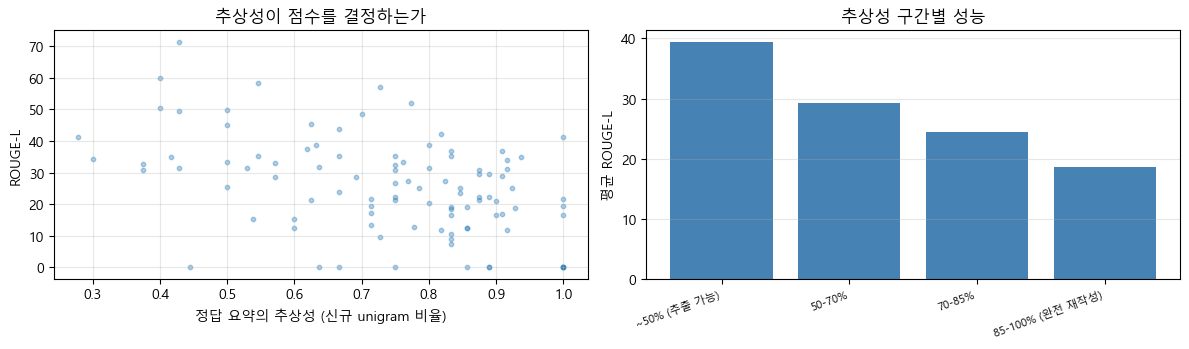

In [83]:
def error_drivers(eval_df, preds, refs, mode=None):
    per = rouge_per_item(preds, refs, mode)
    feat = pd.DataFrame({
        "ROUGE_L":     per[:, 2],
        "발화수":       eval_df["n_utt"].values,
        "말차례":       eval_df["n_turn"].values,
        "화자수":       eval_df["n_part"].values,
        "대화길이":     eval_df["dialogue"].str.len().values,
        "정답길이":     [len(r) for r in refs],
        "생성길이":     [len(p) for p in preds],
        "정답_추상성":  [novel_ngram_rate(tok_stem(r), tok_stem(d), 1)
                       for r, d in zip(refs, eval_df["dialogue"])],
    })

    def spearman(a, b):
        m = ~(pd.isna(a) | pd.isna(b))
        if m.sum() < 5: return float("nan")
        return float(np.corrcoef(pd.Series(a[m]).rank(), pd.Series(b[m]).rank())[0, 1])

    rows = [{"특성": c, "ρ": round(spearman(feat["ROUGE_L"].values, feat[c].values), 3)}
            for c in feat.columns if c != "ROUGE_L"]
    tbl = pd.DataFrame(rows).reindex(
        pd.DataFrame(rows)["ρ"].abs().sort_values(ascending=False).index)
    print(f"=== 건별 ROUGE-L 과 특성의 순위상관 (n={len(feat)}) ===")
    for r in tbl.itertuples():
        print(f"  {r.특성:<12s} ρ={r.ρ:+.3f}  {'█'*int(abs(r.ρ)*40)}")
    print("  |ρ|<0.1 은 사실상 무관, >0.3 이면 지배적 요인")
    return feat, tbl


feat_df, driver_tbl = error_drivers(final_eval, final_preds, final_refs)

# ---- 입력 잘림의 실제 영향 (커버리지가 아니라 점수로 확인) ----
_tl = np.array([len(tokenizer(t).input_ids) for t in FINAL_SRC])
_cut = _tl >= cfg.max_input_len
_per = rouge_per_item(final_preds, final_refs)[:, 0]
print(f"\n=== 입력 잘림 영향 (max_input_len={cfg.max_input_len}) ===")
print(f"  잘린 샘플 {int(_cut.sum())}건 / {len(_cut)}건 ({100*_cut.mean():.1f}%)")
if _cut.sum() >= 5 and (~_cut).sum() >= 5:
    # 서로 다른 샘플이라 대응 비교가 불가 → 각각의 신뢰구간이 겹치는지로 판단
    m1, lo1, hi1 = bootstrap_ci(_per[_cut].reshape(-1, 1))
    m0, lo0, hi0 = bootstrap_ci(_per[~_cut].reshape(-1, 1))
    print(f"  잘림  {m1[0]:5.2f} [{lo1[0]:.1f},{hi1[0]:.1f}]")
    print(f"  온전  {m0[0]:5.2f} [{lo0[0]:.1f},{hi0[0]:.1f}]")
    overlap = not (hi1[0] < lo0[0] or hi0[0] < lo1[0])
    print("  → " + ("신뢰구간이 겹칩니다. 현재 길이로 충분합니다."
                    if overlap else
                    f"구간이 분리됩니다. max_input_len 을 늘리면 개선 여지가 있습니다."))
else:
    print("  잘린 샘플이 너무 적어 비교 불가 — 현재 길이로 충분하다는 뜻입니다.")

# 추상성 구간별 성능 — 단일 숫자보다 훨씬 많은 것을 말해 줍니다
feat_df["추상성구간"] = pd.cut(feat_df["정답_추상성"], [0, .5, .7, .85, 1.01],
                            labels=["~50% (추출 가능)", "50-70%", "70-85%", "85-100% (완전 재작성)"])
strat = (feat_df.groupby("추상성구간", observed=True)
         .agg(건수=("ROUGE_L", "size"), 평균ROUGE_L=("ROUGE_L", "mean"))
         .round(2))
print("\n=== 정답 추상성 구간별 ROUGE-L ===")
print(strat.to_string())
_sp = (strat["평균ROUGE_L"].iloc[0] - strat["평균ROUGE_L"].iloc[-1]) if len(strat) >= 2 else 0.0
print(f"""
읽는 법
  가장 추출적인 구간과 가장 추상적인 구간의 차이: {_sp:.1f}점

  차이가 크면(10점 이상) → 모델이 재작성을 잘 못하고 있거나, 지표가 재작성을 못 따라가고 있습니다.
     §7.1 에서 띄어쓰기·어형에 강한 지표(stemsub)를 쓰고 있는지 확인하세요.
     그래도 크다면 학습량 부족일 가능성이 높습니다.
  차이가 작으면(5점 내외) → 추상성에 관계없이 고르게 동작하고 있다는 뜻입니다.
     이 경우 낮은 절댓값은 '데이터가 추상적이라서'가 아니라 모델 용량/학습량 문제입니다.

  어느 쪽이든 추상성이 높은 구간의 품질은 ROUGE 만으로 확정할 수 없습니다 → §14 사람 평가.
""")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(feat_df["정답_추상성"], feat_df["ROUGE_L"], s=10, alpha=.35)
ax[0].set_xlabel("정답 요약의 추상성 (신규 unigram 비율)"); ax[0].set_ylabel("ROUGE-L")
ax[0].set_title("추상성이 점수를 결정하는가"); ax[0].grid(alpha=.3)
if len(strat):
    ax[1].bar(range(len(strat)), strat["평균ROUGE_L"], color="steelblue")
    ax[1].set_xticks(range(len(strat)))
    ax[1].set_xticklabels([str(x) for x in strat.index], rotation=20, ha="right", fontsize=8)
    ax[1].set_ylabel("평균 ROUGE-L"); ax[1].set_title("추상성 구간별 성능"); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

strat.to_csv(Path(cfg.out_dir)/"error_drivers.csv", encoding="utf-8-sig")

In [84]:
# 정성 평가 + 오차 유형 자동 진단
scored = sorted([(compute_rouge([p],[r])["rougeL"], p, r, d)
                 for p, r, d in zip(final_preds, final_refs, final_eval["dialogue"])],
                key=lambda x: -x[0])

def show(items, title):
    print("#"*80); print("#", title); print("#"*80)
    for s, p, r, d in items:
        print(f"\n[ROUGE-L {s:.1f}]")
        print(d[:350] + ("..." if len(d) > 350 else ""))
        print("  정답 :", r); print("  생성 :", p)

show(scored[:3], "가장 잘 요약한 사례")
show(scored[-3:], "가장 못 요약한 사례")

# 자동 진단
generic = re.compile(r"(이야기를? (나누|하)|대화를 (나누|하)|말하고 있다)")
def _n_sent(t):
    return len([x for x in re.split(r"(?<=[.!?])\s+", t.strip()) if x.strip()])

# 가이드라인은 '한 문장 요약'이고 정답의 99.97%가 실제로 한 문장, 100%가 마침표로 끝납니다.
diag = {
    "무의미한 일반 요약": sum(bool(generic.search(p)) for p in final_preds),
    "마스킹 누출":        sum(bool(RE_LEAK.search(p)) for p in final_preds),
    "지나치게 짧음(<15자)": sum(len(p) < 15 for p in final_preds),
    "반복 어절 포함":      sum(len(w) != len(set(w)) and len(w) > 6
                          for w in (tok_word(p) for p in final_preds)),
    "두 문장 이상 (규약 위반)": sum(_n_sent(p) >= 2 for p in final_preds),
    "정답체 아님(~다/요로 안 끝남)":
        sum(not re.search(r"(다|요)\.$", p.strip()) for p in final_preds),
}
print("\n" + "="*56); print("오차 유형 자동 진단 (n=%d)" % len(final_preds))
_gold = {"두 문장 이상 (규약 위반)": 0.03, "정답체 아님(~다/요로 안 끝남)": 0.0,
         "마스킹 누출": 0.0}
for k, v in diag.items():
    ref = f"   (정답 기준 {_gold[k]:.2f}%)" if k in _gold else ""
    print(f"  {k:<26s} {v:5d}건 ({100*v/len(final_preds):5.1f}%){ref}")
print(f"  평균 문장 수 {np.mean([_n_sent(p) for p in final_preds]):.2f} (정답 1.00)")

################################################################################
# 가장 잘 요약한 사례
################################################################################

[ROUGE-L 53.9]
[P1] 수납장 철거내가하고 렌트 20일 더 받기로했옹
[P2] 아 진짜? ㅋㅋ철거 구냥 인테리어할때 해달라해!!ㅋㅋ
[P2] 20일이나 줬우면 좋은거아냐?!
[P1] 내일 철거팀올때 해준데
[P1] 그렇게 이득은 아니야
[P1] 철거비 50든댓는데 20일 렌트프리 가격따지면 53만원나와
[P1] 근데 철거비도 내일하면 40쯤 든데
[P2] 아아
[P2] 오빠네 인테리어사람이 그래?!
[P1] 옹옹 철거하는 사람은 지네 사람들이 아니라서 내일 바로 줘야한대
  정답 : 수납장 철거를 본인이 하고 렌트 20일 더 받기로 했다.
  생성 : 수납장 철거를 하고 렌트를 20일 더 받기로 했는데 내일 철거팀 올 때 줘야 한다고 한다.

[ROUGE-L 42.1]
[P1] 이 이상 손을
[P1] 어뜨캐 대지
[P1] 숱을 늘릴까
[P2] 더 만지면
[P2] 망친다
[P1] 웅..
[P1] 아는데
[P1] ..거울 보니까 짜증나네
[P2] ..좀 참아
  정답 : 머리를 더 만지면 망친다고 하니 거울을 보니 짜증이 난다고 한다.
  생성 : 어뜨캐를 더 만지면 짜증난다고 한다. 숱을 늘리면 망친다고 한다.

[ROUGE-L 40.0]
[P1] 발냄시랑 먼상관이젲?
[P1] 여뷰!?
[P2] 신발이 젖으면
[P2] 발이 젖구
[P2] 그럼
[P2] 냄시나><
[P1] 아니야
[P1] 그건
[P1] [이름]발이야
[P1] [이름]발은 아니야
[P2] [이름]는 발냄새가 난적이
[P2] 한번도 없떠
  정답 : 신발이 젖으면 발이 젖고 그러면 발냄새가 난다.
  생성 : 발냄 냄새가 난다고 신발이 젖으면 발냄새가 난다고 한다.
######

### 오차 분석 체크리스트

| 오류 유형 | 증상 | 대응 |
|---|---|---|
| 환각(hallucination) | 대화에 없는 사실 생성 | `label_smoothing`↓, beam↓, 데이터 확대 |
| 무의미 일반화 | "이야기를 나눈다" 류 | `min_gen_len`↑, `length_penalty`↑ |
| 핵심 누락 | 뒷부분 결론 누락 | `max_input_len`↑ (커버리지 재확인) |
| 화자 혼동 | 발언 주체가 뒤바뀜 | 화자 토큰 유지 확인, 3인 이상 대화 별도 분석 |
| 마스킹 누출 | `[이름]`이 요약문에 등장 | `postprocess()` 확인, 학습 데이터 필터링 |
| 길이 편향 | 항상 비슷한 길이 | `length_penalty` 0.8~1.5 탐색 |

위 자동 진단 수치를 **개선 전/후로 비교**하면 그대로 보고서 표가 됩니다.

---
## 12. 추론 & 저장

### 12.1 체크포인트 평균 (재학습 없는 개선)

학습 후반의 체크포인트 몇 개를 **가중치 평균**하면 대체로 조금 더 안정적인 모델이 됩니다.
(Transformer 계열에서 널리 쓰이는 기법 — 손실 표면의 평평한 지점으로 이동하는 효과)

비용은 디스크와 몇 초의 계산뿐입니다. **효과는 보장되지 않으므로 반드시 dev에서 확인**하고,
좋아졌을 때만 채택하세요. 아래 셀이 그 판단까지 대신 해 줍니다.

In [85]:
def average_checkpoints(paths, base_model):
    """state_dict 들의 산술 평균을 base_model 에 적용한 새 모델을 돌려준다."""
    import copy
    acc, n = None, 0
    for p in paths:
        sd = torch.load(p, map_location="cpu", weights_only=True)
        if acc is None:
            acc = {k: v.clone().float() for k, v in sd.items()}
        else:
            for k in acc:
                if k in sd and sd[k].shape == acc[k].shape: acc[k] += sd[k].float()
        n += 1
    if not n: return None
    for k in acc: acc[k] /= n
    avg = copy.deepcopy(base_model).cpu()
    ref = avg.state_dict()
    avg.load_state_dict({k: acc[k].to(ref[k].dtype) if k in acc else v
                         for k, v in ref.items()}, strict=False)
    return avg.to(DEVICE).eval()


CKPT_DIR = Path(cfg.out_dir) / "ckpts"
ckpts = sorted(CKPT_DIR.glob("step*.pt")) if CKPT_DIR.exists() else []
print(f"평균 대상 체크포인트 {len(ckpts)}개:", [p.name for p in ckpts])

if len(ckpts) >= 2:
    # dev 에서 비교 — test 는 최종 보고 전용이므로 절대 쓰지 않는다
    AVG_POS = stratified_subset_of(valid_df, DEV_POS, min(400, len(DEV_POS)), seed=cfg.seed + 11)
    avg_df  = valid_df.iloc[AVG_POS].reset_index(drop=True)
    avg_src, avg_ref = to_model_input(avg_df), avg_df["summary"].tolist()

    p_best = generate_summaries(best_model, avg_src, desc="best", **DEC)
    per_best = rouge_per_item(p_best, avg_ref)

    avg_model = average_checkpoints(ckpts, best_model)
    p_avg = generate_summaries(avg_model, avg_src, desc="avg", **DEC)
    per_avg = rouge_per_item(p_avg, avg_ref)

    for nm, per in (("best 단일", per_best), ("평균", per_avg)):
        m, lo, hi = bootstrap_ci(per)
        print(f"  {nm:<8s} R-1 {m[0]:5.2f} [{lo[0]:.1f},{hi[0]:.1f}]   R-L {m[2]:5.2f} [{lo[2]:.1f},{hi[2]:.1f}]")

    obs, lo, hi, p = paired_bootstrap(per_avg[:, 2], per_best[:, 2])
    print(f"\n  평균 − best  R-L {obs:+.2f} [{lo:+.2f},{hi:+.2f}]  p={p:.3f}")
    if p < 0.05 and obs > 0:
        best_model = avg_model
        best_model.save_pretrained(Path(cfg.out_dir) / "best_avg")
        tokenizer.save_pretrained(Path(cfg.out_dir) / "best_avg")
        print("  ✅ 평균 모델이 유의하게 우세 → best_model 교체 (outputs/best_avg 저장)")
        print("  ※ §11.2 최종 평가 셀을 다시 실행해 test 점수를 갱신하세요")
    elif p < 0.05 and obs < 0:
        print("  → 평균이 유의하게 열세. 단일 best 체크포인트를 유지합니다")
    else:
        print("  → 개선이 유의하지 않음. 단일 best 체크포인트를 유지합니다 (정상적인 결과입니다)")
else:
    print("체크포인트가 2개 미만입니다. cfg.keep_last_ckpts 를 켜고 평가를 2회 이상 거치세요.")

평균 대상 체크포인트 2개: ['step0000030.pt', 'step0000060.pt']


best:   0%|          | 0/7 [00:00<?, ?it/s]

avg:   0%|          | 0/7 [00:00<?, ?it/s]

  best 단일  R-1 26.95 [25.5,28.5]   R-L 26.95 [25.5,28.5]
  평균       R-1 26.95 [25.5,28.5]   R-L 26.95 [25.5,28.5]

  평균 − best  R-L +0.00 [+0.00,+0.00]  p=1.000
  → 개선이 유의하지 않음. 단일 best 체크포인트를 유지합니다 (정상적인 결과입니다)


In [86]:
def summarize(dialogue, topic=None, model=None, num_beams=None):
    """dialogue: [(화자, 발화), ...] 리스트 또는 전처리된 문자열
       topic   : cfg.use_topic_prefix=True 일 때만 사용"""
    m = model or best_model
    if isinstance(dialogue, (list, tuple)):
        dialogue = build_dialogue_text(
            [{"participantID": s, "utterance": u} for s, u in dialogue])
    if cfg.use_topic_prefix:
        dialogue = f"[{topic or '개인 및 관계'}] {dialogue}"
    return generate_summaries(m, [dialogue], num_beams=num_beams or cfg.final_num_beams,
                              batch_size=1, sort_by_length=False)[0]

sample_chat = [
    ("A", "야 이번 주말에 뭐해?"),
    ("B", "나 토요일에 #@이름#이랑 전시 보러 가기로 했는데ㅋㅋㅋㅋ"),
    ("A", "오 무슨 전시??"),
    ("B", "#@시스템#사진#"),
    ("B", "성수에서 하는 사진전! 너도 올래??"),
    ("A", "좋지!! 몇시에 만나?"),
    ("B", "2시쯤 성수역에서 보자~"),
    ("A", "ㅇㅋㅇㅋ 그때 봐!!!"),
]
print("전처리:\n", build_dialogue_text(
    [{"participantID": s, "utterance": u} for s, u in sample_chat]))
print("\n요약:", summarize(sample_chat))

전처리:
 [P1] 야 이번 주말에 뭐해?
[P2] 나 토요일에 [이름]이랑 전시 보러 가기로 했는데ㅋㅋ
[P1] 오 무슨 전시??
[P2] 성수에서 하는 사진전! 너도 올래??
[P1] 좋지!! 몇시에 만나?
[P2] 2시쯤 성수역에서 보자~
[P1] ㅇㅋㅇㅋ 그때 봐!!


generate:   0%|          | 0/1 [00:00<?, ?it/s]


요약: 토요일에 성수에서 하는 사진전을 보러 가기로 했는데 2시쯤 성수역에서 만나기로 했다.


In [87]:
FINAL = Path(cfg.out_dir)/"final_model"
best_model.save_pretrained(FINAL); tokenizer.save_pretrained(FINAL)

pred_df = pd.DataFrame({
    "id": final_eval.id, "topic": final_eval.topic, "type": final_eval.type,
    "n_part": final_eval.n_part, "n_utt": final_eval.n_utt,
    "dialogue": final_eval.dialogue, "reference": final_refs, "prediction": final_preds,
})
# 사람이 직접 훑어볼 수 있도록 건별 점수·진단 플래그를 붙인다
pred_df["rougeL"]   = [compute_rouge([p_], [r_], cfg.select_metric)["rougeL"]
                       for p_, r_ in zip(final_preds, final_refs)]
pred_df["근거율"]    = [round(100*len(set(content_tokens(p_)) & set(content_tokens(d_)))
                            / max(len(set(content_tokens(p_))), 1), 1)
                       for p_, d_ in zip(final_preds, final_eval.dialogue)]
pred_df["길이차"]    = [len(p_) - len(r_) for p_, r_ in zip(final_preds, final_refs)]
pred_df["무의미"]    = [bool(generic.search(p_)) for p_ in final_preds]
pred_df["마스킹누출"] = [bool(RE_LEAK.search(p_)) for p_ in final_preds]
pred_df["어절반복"]  = [len(tok_word(p_)) != len(set(tok_word(p_))) and len(tok_word(p_)) > 6
                       for p_ in final_preds]
pred_df.sort_values("rougeL").to_csv(Path(cfg.out_dir)/"predictions.csv",
                                     index=False, encoding="utf-8-sig")
print(f"predictions.csv — 점수 낮은 순 정렬, {len(pred_df)}건 (오차 분석용)")

json.dump({"config": asdict(cfg),
           "split": {"train": int(len(train_idx)), "dev": int(len(DEV_POS)),
                     "test": int(len(TEST_POS)), "final_eval": int(len(final_eval))},
           "best_rougeL_dev_greedy": best_score,
           "test_word": compute_rouge(final_preds, final_refs, "word"),
           "test_char": compute_rouge(final_preds, final_refs, "char"),
           "test_factuality": factuality(final_preds, final_refs,
                                         final_eval["dialogue"].tolist()),
           "decoding": DEC, "decoding_comparison": beam_table,
           "metric_calibration": calib.to_dict("records"),
           "throughput_samples_per_sec": round(sps, 1), "steps": int(step)},
          open(Path(cfg.out_dir)/"result.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2)

# 재현용 환경 파일
(Path(cfg.out_dir)/"requirements.txt").write_text(
    "\n".join([
        f"# python {sys.version.split()[0]}",
        "# torch 는 본인 CUDA 버전에 맞춰 https://pytorch.org 에서 설치",
        f"torch=={torch.__version__.split('+')[0]}",
        f"transformers=={transformers.__version__}",
        "sentencepiece", "protobuf",
        f"pandas=={pd.__version__}", f"numpy=={np.__version__}",
        "matplotlib", "tqdm", "tabulate",
    ]), encoding="utf-8")

print("저장 완료:")
for p in sorted(Path(cfg.out_dir).rglob("*")):
    if p.is_file(): print(f"  {p}  ({p.stat().st_size/1e6:.1f} MB)")

# 재사용:
# model = AutoModelForSeq2SeqLM.from_pretrained("./outputs/final_model").to(DEVICE)
# tokenizer = AutoTokenizer.from_pretrained("./outputs/final_model")

Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 2}


predictions.csv — 점수 낮은 순 정렬, 100건 (오차 분석용)
저장 완료:
  outputs\best\config.json  (0.0 MB)
  outputs\best\generation_config.json  (0.0 MB)
  outputs\best\model.safetensors  (495.6 MB)
  outputs\best\special_tokens_map.json  (0.0 MB)
  outputs\best\tokenizer.json  (1.1 MB)
  outputs\best\tokenizer_config.json  (0.0 MB)
  outputs\ckpts\step0000030.pt  (772.2 MB)
  outputs\ckpts\step0000060.pt  (772.2 MB)
  outputs\conformance.csv  (0.0 MB)
  outputs\decoding_sweep.csv  (0.0 MB)
  outputs\error_drivers.csv  (0.0 MB)
  outputs\final_model\config.json  (0.0 MB)
  outputs\final_model\generation_config.json  (0.0 MB)
  outputs\final_model\model.safetensors  (495.6 MB)
  outputs\final_model\special_tokens_map.json  (0.0 MB)
  outputs\final_model\tokenizer.json  (1.1 MB)
  outputs\final_model\tokenizer_config.json  (0.0 MB)
  outputs\history.csv  (0.0 MB)
  outputs\last.pt  (1486.8 MB)
  outputs\metric_calibration.csv  (0.0 MB)
  outputs\predictions.csv  (0.1 MB)
  outputs\requirements.txt  (0.0 M

### 12.2 저장 왕복 검증 (save → load → 동일 출력?)

저장한 모델을 다시 불러왔을 때 **같은 결과가 나오는지** 확인합니다.
이 단계에서 조용히 깨지는 것들이 있습니다.

- 추가한 화자 토큰 `[P1]…[P8]` 이 토크나이저와 함께 저장되지 않음 → 불러오면 `<unk>` 로 쪼개짐
- `generation_config` 가 저장되지 않아 디코딩 설정이 기본값으로 되돌아감
- 임베딩 리사이즈가 반영되지 않아 크기 불일치

전부 **로그에 아무 흔적도 남기지 않고** 점수만 떨어뜨립니다.
제출 직전에 발견하면 늦으므로 저장 직후에 확인합니다.

In [88]:
def verify_save_roundtrip(model_dir=None, n=24):
    d = str(model_dir or FINAL)
    tk2 = AutoTokenizer.from_pretrained(d)
    md2 = AutoModelForSeq2SeqLM.from_pretrained(d).to(DEVICE).eval()
    ok = True

    # 1) 화자 토큰이 하나의 토큰으로 살아 있는가
    if cfg.add_speaker_tokens:
        bad = [t for t in [f"[P{i}]" for i in range(1, 9)] if len(tk2.tokenize(t)) != 1]
        print(f"  {'✅' if not bad else '❌'} 화자 토큰 보존" + (f"  깨진 토큰: {bad}" if bad else ""))
        ok &= not bad

    # 2) vocab 크기와 임베딩 크기가 맞는가
    emb = md2.get_input_embeddings().weight.shape[0]
    same = emb >= len(tk2)
    print(f"  {'✅' if same else '❌'} 임베딩({emb}) ≥ vocab({len(tk2)})")
    ok &= same

    # 3) generation_config 가 남아 있는가
    gc2 = md2.generation_config
    gsame = (gc2.max_length == cfg.max_target_len)
    print(f"  {'✅' if gsame else '⚠'} generation_config.max_length = {gc2.max_length} "
          f"(기대 {cfg.max_target_len})")

    # 4) 같은 입력 → 같은 출력인가 (핵심)
    src = to_model_input(final_eval.head(n))
    a = generate_summaries(best_model, src, sort_by_length=False, desc="", **DEC)
    _bak, tokenizer_local = tokenizer, tk2
    globals()["tokenizer"] = tk2
    try:
        b = generate_summaries(md2, src, sort_by_length=False, desc="", **DEC)
    finally:
        globals()["tokenizer"] = _bak
    match = sum(1 for x, y in zip(a, b) if x == y)
    print(f"  {'✅' if match == len(a) else '❌'} 재로드 출력 일치 {match}/{len(a)}")
    if match != len(a):
        for x, y in zip(a, b):
            if x != y:
                print(f"     저장 전: {x[:70]}\n     재로드 : {y[:70]}"); break
    ok &= (match == len(a))

    del md2
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("  →", "✅ 저장물이 그대로 재현됩니다" if ok else "❌ 저장/로드 과정에서 손실이 있습니다")
    globals()["_ROUNDTRIP_OK"] = bool(ok)     # §19.6 배포 게이트가 참조합니다
    return ok


verify_save_roundtrip()

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


  ✅ 화자 토큰 보존
  ✅ 임베딩(30008) ≥ vocab(30008)
  ⚠ generation_config.max_length = 20 (기대 80)


generate:   0%|          | 0/1 [00:00<?, ?it/s]

generate:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ 재로드 출력 일치 24/24
  → ✅ 저장물이 그대로 재현됩니다


True

### 12.3 배치 추론 & 서비스 형태

학습한 모델을 **새로운 대화에 적용**하는 두 가지 형태입니다.

1. `predict_file()` — 원본 AI Hub JSON 또는 JSONL을 받아 요약을 붙여 CSV로 저장 (대량 처리)
2. `write_serve_py()` — 가이드라인 2.6.2의 API 규격(`POST /dialsum`)을 따르는 FastAPI 서버 파일 생성

둘 다 §3.1의 전처리와 §11.1에서 고른 디코딩 설정을 **그대로** 재사용합니다.
학습 때와 추론 때 입력 형식이 어긋나는 것이 실무에서 가장 흔한 성능 저하 원인입니다.

> **주제 프리픽스를 쓸 때 주의.** 가이드라인 2.6.2 의 API 입력은 발화 목록뿐이라
> **주제(`topic`)가 없습니다.** 주제를 항상 붙여 학습하면 서빙 때 곤란해집니다.
> `cfg.topic_prefix_dropout`(기본 0.3)이 학습 중 일부 예시의 주제를 빼기 때문에
> 주제가 있어도, 없어도 동작합니다. 생성되는 `serve.py` 도 주제가 주어졌을 때만 붙입니다.
> 대화 유형(`type`)도 같은 이유로 입력에 넣지 않습니다 — §11.6 참조.

In [89]:
def predict_file(src_path, out_csv=None, batch_size=None, limit=None):
    '''원본 AI Hub JSON(또는 jsonl)을 받아 요약을 생성하고 CSV 로 저장.'''
    src_path = Path(resolve_path(str(src_path)))
    recs = []
    if src_path.suffix == '.jsonl':
        for line in open(src_path, encoding='utf-8'):
            recs.append(json.loads(line))
    else:
        raw = json.load(open(src_path, encoding='utf-8'))
        items = raw['data'] if isinstance(raw, dict) and 'data' in raw else raw
        for it in items:
            if 'body' in it:                                   # 원본 AI Hub 포맷
                di = it['header']['dialogueInfo']
                recs.append({'id': di['dialogueID'], 'topic': di.get('topic', ''),
                             'dialogue': build_dialogue_text(it['body']['dialogue']),
                             'summary': it['body'].get('summary', '')})
            else:
                recs.append(it)
    if limit: recs = recs[:limit]
    df = pd.DataFrame(recs)
    if 'dialogue' not in df.columns:
        raise ValueError(f"'dialogue' 컬럼이 없습니다. 발견된 컬럼: {list(df.columns)}")
    if 'topic' not in df.columns: df['topic'] = ''

    t0 = time.time()
    df['prediction'] = generate_summaries(best_model, to_model_input(df),
                                          batch_size=batch_size, desc='predict', **DEC)
    dt = time.time() - t0
    print(f'{len(df):,}건 / {dt:.1f}s  ({len(df)/max(dt,1e-9):.1f} 건/s)')

    if 'summary' in df.columns and df['summary'].astype(str).str.len().gt(0).any():
        ok = df[df['summary'].astype(str).str.len() > 0]
        m, lo, hi = bootstrap_ci(rouge_per_item(ok['prediction'].tolist(), ok['summary'].tolist()))
        print(f'정답이 있는 {len(ok):,}건 기준  '
              f'R-1 {m[0]:.2f} [{lo[0]:.1f},{hi[0]:.1f}]   R-L {m[2]:.2f} [{lo[2]:.1f},{hi[2]:.1f}]')

    out_csv = Path(out_csv or Path(cfg.out_dir)/'predictions_new.csv')
    df.to_csv(out_csv, index=False, encoding='utf-8-sig')
    print('저장:', out_csv)
    return df


_demo = predict_file(VALID_JSONL, out_csv=Path(cfg.out_dir)/'predict_demo.csv', limit=20)
_demo[['prediction']].head(3)

predict:   0%|          | 0/1 [00:00<?, ?it/s]

20건 / 4.7s  (4.3 건/s)
정답이 있는 20건 기준  R-1 23.36 [16.3,30.6]   R-L 23.36 [16.3,30.6]
저장: outputs\predict_demo.csv


,prediction
0,엄마를 엄마가 못하니까 아빠를 못하니까 엄마를 못 한다고 한다.
1,오늘 바로 딥갔는데 휴식이 되지 못했다. 집에 가서 쉬었는지 잘 모르겠다.
2,남동 동생이랑 이야기해서 싸웠는데 여자친구가 생겼다고 한다.


In [90]:
SERVE_TEMPLATE = '''# 한국어 대화 요약 API — 가이드라인 2.6.2 규격
#   pip install fastapi uvicorn
#   python serve.py      →  http://127.0.0.1:8000/docs
#
#   curl -X POST http://127.0.0.1:8000/dialsum -H "Content-Type: application/json" \\
#        -d '{"input":[{"speaker":"A","utterance":"내일 뭐해?"},
#                      {"speaker":"B","utterance":"전시 보러 가"}]}'
import re
from typing import List, Optional
import torch
from fastapi import FastAPI
from pydantic import BaseModel
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_DIR        = "./final_model"
GEN              = %%GEN%%
USE_TOPIC_PREFIX = %%TOPIC%%
MAX_INPUT_LEN    = %%MAXIN%%
PLACEHOLDER_MAP  = %%PMAP%%
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- 학습 때와 반드시 동일한 전처리 (노트북 §3.1 과 1:1 대응) ----
RE_SYSTEM   = re.compile(r"#@시스템#[^#\\s]*#?")
RE_EMOTICON = re.compile(r"#@이모티콘#[^#\\s]*#?")
RE_GENERIC  = re.compile(r"#@([^#\\s]+)#")
RE_LAUGH    = re.compile(r"([ㄱ-ㅎㅏ-ㅣ])\\1{2,}")
RE_REPEAT   = re.compile(r"([!?~.,ㅠㅜ])\\1{2,}")
RE_SPACE    = re.compile(r"[ \\t]+")

def clean_utterance(t):
    t = RE_SYSTEM.sub("", t)
    t = RE_EMOTICON.sub("", t)
    t = RE_GENERIC.sub(lambda m: PLACEHOLDER_MAP.get(m.group(1), "[기타]"), t)
    t = t.replace("#", " ")
    t = RE_LAUGH.sub(r"\\1\\1", t)
    t = RE_REPEAT.sub(r"\\1\\1", t)
    return RE_SPACE.sub(" ", t).strip()

def build_dialogue_text(turns):
    # 정제 후 남은 발화에만 번호 부여 (노트북 §3.1 과 동일 — 순서를 바꾸면 안 됩니다)
    seen, out = {}, []
    for u in turns:
        t = clean_utterance(u.utterance)
        if not t:
            continue
        if u.speaker not in seen:
            seen[u.speaker] = len(seen) + 1
        out.append("[P%d] %s" % (min(seen[u.speaker], 8), t))
    return "\\n".join(out)

class Turn(BaseModel):
    speaker: str
    utterance: str

class Req(BaseModel):
    input: List[Turn]
    topic: Optional[str] = None

app = FastAPI(title="Korean Dialogue Summarization")
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR).to(DEVICE).eval()

@app.get("/health")
def health():
    return {"status": "ok", "device": str(DEVICE)}

@app.post("/dialsum")
@torch.no_grad()
def dialsum(req: Req):
    if not req.input:
        return {"summary": "", "n_turns": 0}
    text = build_dialogue_text(req.input)
    if USE_TOPIC_PREFIX and req.topic:
        # 주제가 주어졌을 때만 붙입니다. 학습 때 prefix dropout 을 썼다면
        # 주제가 없어도 정상 동작합니다 (없는 주제를 지어내지 않습니다).
        text = "[%s] %s" % (req.topic, text)
    enc = tokenizer([text], max_length=MAX_INPUT_LEN, truncation=True,
                    padding=True, return_tensors="pt").to(DEVICE)
    out = model.generate(**enc, **GEN)
    return {"summary": tokenizer.decode(out[0], skip_special_tokens=True).strip(),
            "n_turns": len(req.input)}

if __name__ == "__main__":
    import uvicorn
    uvicorn.run(app, host="127.0.0.1", port=8000)
'''

def write_serve_py(path=None):
    gen = dict(DEC); gen.update(max_length=cfg.max_target_len,
                                no_repeat_ngram_size=cfg.no_repeat_ngram_size)
    src = (SERVE_TEMPLATE
           .replace('%%GEN%%',   repr(gen))
           .replace('%%TOPIC%%', repr(cfg.use_topic_prefix))
           .replace('%%MAXIN%%', repr(cfg.max_input_len))
           .replace('%%PMAP%%',  repr(PLACEHOLDER_MAP)))
    import ast as _ast
    _ast.parse(src)                       # 생성 즉시 문법 검증
    p = Path(path or Path(cfg.out_dir)/'serve.py')
    p.write_text(src, encoding='utf-8')
    print(f'생성: {p}  (문법 검사 통과, {len(src.splitlines())}줄)')
    print(f'  실행: cd {cfg.out_dir} && pip install fastapi uvicorn && python serve.py')
    print('  MODEL_DIR 기본값 ./final_model — 같은 폴더에 이미 저장돼 있습니다')
    return p

SERVE_PATH = write_serve_py()


def verify_serve_parity(path=None, n=200, seed=0):
    '''생성된 serve.py 의 전처리가 노트북과 **완전히 같은지** 확인.

    학습/서빙 전처리 불일치(train-serve skew)는 배포에서 가장 흔한 성능 저하 원인이고,
    로그에 아무 흔적도 남지 않아 발견이 어렵습니다. 그래서 자동으로 검사합니다.'''
    src = Path(path or SERVE_PATH).read_text(encoding='utf-8').split('class Turn(BaseModel)')[0]
    for drop in ['import torch', 'from fastapi import FastAPI', 'from pydantic import BaseModel',
                 'from transformers import AutoTokenizer, AutoModelForSeq2SeqLM',
                 'DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")']:
        src = src.replace(drop, '')
    ns = {}
    exec(compile(src, '<serve>', 'exec'), ns)

    class _T:
        def __init__(s, sp, u): s.speaker, s.utterance = sp, u

    cases = [
        [('A', '[이름]아 내일 뭐해??ㅋㅋㅋㅋㅋ'.replace('[이름]', '#@이름#')),
         ('B', '#@시스템#사진#'), ('B', '이거 #@URL# 봐!!!!!'), ('A', '#@이모티콘#하트뿅#')],
        [('P01', '#@기타# 진짜'), ('P02', '#@주소#로 와'), ('P01', 'ㅇㅋㅇㅋㅋㅋㅋㅋ')],
        [('x', '#@시스템#검색#'), ('y', '#@이모티콘#'), ('z', '안녕'), ('x', 'ㅠㅠㅠㅠㅠ')],
        [('A', ''), ('B', '   '), ('C', '정상 발화')],
        [('A', '#@이름##'), ('B', '#@기타##'), ('C', '#@신원# #@금융# #@전번#')],
    ]
    rng = random.Random(seed)
    pool = valid_df['dialogue'].tolist()
    for _ in range(n):                       # 실데이터를 화자/발화로 되돌려 사용
        turns = []
        for l in pool[rng.randrange(len(pool))].split('\n'):
            m = re.match(r'^\[P(\d)\]\s*(.*)$', l)
            if m: turns.append((f'P{m.group(1)}', m.group(2)))
        if turns: cases.append(turns)

    bad = 0
    for cse in cases:
        a = build_dialogue_text([{'participantID': s, 'utterance': u} for s, u in cse])
        b = ns['build_dialogue_text']([_T(s, u) for s, u in cse])
        if a != b:
            bad += 1
            if bad <= 3:
                print('  불일치\n    notebook:', repr(a[:120]), '\n    serve.py:', repr(b[:120]))
    print(f'전처리 일치 검사: {len(cases)}건 중 불일치 {bad}건 → '
          + ('✅ 완전 일치 (train-serve skew 없음)' if bad == 0
             else '❌ 불일치 — §3.1 을 고쳤다면 SERVE_TEMPLATE 도 같이 고치세요'))
    return bad == 0


verify_serve_parity()

생성: outputs\serve.py  (문법 검사 통과, 85줄)
  실행: cd ./outputs && pip install fastapi uvicorn && python serve.py
  MODEL_DIR 기본값 ./final_model — 같은 폴더에 이미 저장돼 있습니다
전처리 일치 검사: 205건 중 불일치 0건 → ✅ 완전 일치 (train-serve skew 없음)


True

---
## 13. 실험 기록 & 보고서용 표

설정을 바꿔 가며 §10~§11을 다시 돌릴 때마다 아래 셀을 실행하면 `experiments.csv`에 한 줄씩 쌓입니다.
보고서의 **비교 표**가 자동으로 만들어집니다.

권장 비교 축 (한 번에 하나씩만 바꾸세요):

| 실험명 | 바꾸는 것 | 확인하려는 것 |
|---|---|---|
| `baseline` | — | 기준점 |
| `data_x7` | `train_subset=None` | 데이터 양의 효과 |
| `len512` | `max_input_len=512` | 입력 잘림의 영향 |
| `no_group` | `group_by_length=False` | 배칭 최적화의 속도 효과 |
| `lr1e-4` | `lr=1e-4` | 학습률 |
| `no_smooth` | `label_smoothing=0.0` | 라벨 스무딩 |
| `topic_prefix` | `use_topic_prefix=True` | 주제 조건부 생성 |
| `pko_t5` | `model_name="paust/pko-t5-base"` | 백본 교체 |

In [91]:
EXP_CSV = Path(cfg.out_dir) / "experiments.csv"

def log_experiment(name, notes=""):
    sc = {m: compute_rouge(final_preds, final_refs, m) for m in METRIC_SET}
    fa = factuality(final_preds, final_refs, final_eval["dialogue"].tolist())
    row = {
        "실험명": name,
        "seed": cfg.seed,
        "모델": Path(cfg.model_name).name,
        "학습건수": len(train_idx), "step": step,
        "max_in": cfg.max_input_len, "batch": cfg.batch_size*cfg.grad_accum,
        "lr": cfg.lr, "smooth": cfg.label_smoothing,
        "길이그룹": cfg.group_by_length, "주제프리픽스": cfg.use_topic_prefix,
        "디코딩": f"beam{DEC['num_beams']}/lp{DEC['length_penalty']}/min{DEC['min_length']}",
        "wR1": sc["word"]["rouge1"], "wRL": sc["word"]["rougeL"],
        "sR1": sc["stem"]["rouge1"], "sR2": sc["stem"]["rouge2"], "sRL": sc["stem"]["rougeL"],
        "cRL": sc["char"]["rougeL"], "ssRL": sc["stemsub"]["rougeL"],
        **fa,
        "samples/s": round(sps, 1),
        "학습분": round((time.time()-t_start)/60, 1),
        "메모": notes,
    }
    df = pd.concat([pd.read_csv(EXP_CSV), pd.DataFrame([row])], ignore_index=True) \
         if EXP_CSV.exists() else pd.DataFrame([row])
    df.to_csv(EXP_CSV, index=False, encoding="utf-8-sig")
    return df

if cfg.smoke_test:
    print("⚠ smoke_test 모드의 결과입니다. 기록하지 마세요.")
    print("  cfg.smoke_test = False 로 바꾸고 커널 재시작 후 본 학습을 돌린 뒤 기록하세요.\n")

exp_df = log_experiment("smoke" if cfg.smoke_test else "baseline",
                        notes="파이프라인 검증" if cfg.smoke_test else "KoBART 기본 설정")
print(exp_df.to_string(index=False))

# ---- 보고서에 붙여넣을 마크다운 표 ----
cols = ["실험명", "seed", "학습건수", "step", "디코딩", "ssRL", "sR1", "sRL", "wRL",
        "내용어 재현율", "대화문 근거율", "samples/s", "학습분"]
try:
    md = exp_df[cols].to_markdown(index=False)      # pip install tabulate 필요
except Exception:
    md = exp_df[cols].to_string(index=False)
print("\n" + "="*70 + "\n보고서용 표 (복사해서 사용)\n" + "="*70)
print(md)
(Path(cfg.out_dir)/"report_table.md").write_text(str(md), encoding="utf-8")

⚠ smoke_test 모드의 결과입니다. 기록하지 마세요.
  cfg.smoke_test = False 로 바꾸고 커널 재시작 후 본 학습을 돌린 뒤 기록하세요.

  실험명  seed             모델  학습건수  step  max_in  batch      lr  smooth  길이그룹  주제프리픽스               디코딩   wR1   wRL   sR1  sR2   sRL   cRL  ssRL  내용어 재현율  대화문 근거율  숫자 일치율  samples/s  학습분       메모
smoke    42 kobart-base-v2  2001    60     256     32 0.00005     0.1  True   False beam4/lp1.0/min12 15.06 13.79 18.19 4.68 16.92 32.55 25.83     21.1     31.4    56.4      165.4 26.5 파이프라인 검증

보고서용 표 (복사해서 사용)
| 실험명   |   seed |   학습건수 |   step | 디코딩            |   ssRL |   sR1 |   sRL |   wRL |   내용어 재현율 |   대화문 근거율 |   samples/s |   학습분 |
|:---------|-------:|-----------:|-------:|:------------------|-------:|------:|------:|------:|----------------:|----------------:|------------:|---------:|
| smoke    |     42 |       2001 |     60 | beam4/lp1.0/min12 |  25.83 | 18.19 | 16.92 | 13.79 |            21.1 |            31.4 |       165.4 |     26.5 |


448

### 13.1 시드 분산 — 평가 노이즈보다 학습 노이즈가 더 큽니다

§7.2의 부트스트랩 신뢰구간은 **평가셋을 다시 뽑았을 때**의 불확실성입니다.
하지만 같은 설정으로 **다시 학습**하면 초기화·데이터 순서·드롭아웃이 달라져 결과가 또 바뀝니다.
보통 이 **학습 노이즈가 평가 노이즈보다 큽니다.**

그래서 "설정 A가 B보다 0.6점 높다"를 주장하려면 두 가지가 다 필요합니다.

1. 평가 노이즈보다 큰 차이인가 → §7.2 대응 부트스트랩
2. **학습 노이즈보다 큰 차이인가** → 시드를 바꿔 2~3회 재학습

**실행 방법**: `cfg.seed` 를 42 → 43 → 44 로 바꾸고, 그때마다
`outputs/last.pt` 와 `outputs/best` 를 지운 뒤 §10부터 다시 실행합니다.
매번 `log_experiment("baseline", ...)` 로 기록하면 아래 셀이 자동 집계합니다.

시간이 없으면 **가장 중요한 비교 하나만** 3시드로 돌리고, 나머지는 단일 시드에
"시드 1회 결과"라고 명시하세요. 그것만으로도 보고서의 신뢰도가 크게 올라갑니다.

In [92]:
def seed_variance(csv=None, group_cols=("실험명",)):
    """experiments.csv 를 실험명별로 묶어 시드 간 분산을 집계."""
    csv = Path(csv or EXP_CSV)
    if not csv.exists():
        print("experiments.csv 가 없습니다."); return None
    df = pd.read_csv(csv)
    if "seed" not in df.columns:
        print("seed 컬럼이 없습니다 (이전 버전 기록). 새로 기록하면 집계됩니다."); return None

    g = df.groupby(list(group_cols))
    rows = []
    for key, sub in g:
        r = {"실험명": key if isinstance(key, str) else key[0],
             "시드수": sub["seed"].nunique(), "실행수": len(sub)}
        for m in ("sR1", "sRL"):
            if m in sub.columns:
                r[f"{m}_평균"] = round(sub[m].mean(), 2)
                r[f"{m}_표준편차"] = round(sub[m].std(ddof=1), 2) if len(sub) > 1 else np.nan
                r[f"{m}_범위"] = (round(sub[m].max() - sub[m].min(), 2) if len(sub) > 1 else np.nan)
        rows.append(r)
    out = pd.DataFrame(rows)
    print("=== 시드 간 분산 ===")
    print(out.to_string(index=False))

    multi = out[out["실행수"] > 1]
    if len(multi):
        sd = multi["sRL_표준편차"].dropna()
        if len(sd):
            print(f"\n시드 간 ROUGE-L 표준편차 평균 = {sd.mean():.2f}")
            print(f"  → 시드 하나만 돌렸다면 ±{1.96*sd.mean():.2f} 정도는 우연입니다.")
            print(f"  → 이보다 작은 차이는 '개선'이라고 쓰지 마세요.")
    else:
        print("\n같은 실험명으로 2회 이상 기록된 것이 없습니다.")
        print("  cfg.seed 를 바꾸고 outputs/last.pt·outputs/best 를 지운 뒤 §10부터 다시 실행해")
        print("  같은 실험명으로 log_experiment() 하면 여기에 집계됩니다.")
    return out


seed_tbl = seed_variance()

=== 시드 간 분산 ===
  실험명  시드수  실행수  sR1_평균  sR1_표준편차  sR1_범위  sRL_평균  sRL_표준편차  sRL_범위
smoke    1    1   18.19       NaN     NaN   16.92       NaN     NaN

같은 실험명으로 2회 이상 기록된 것이 없습니다.
  cfg.seed 를 바꾸고 outputs/last.pt·outputs/best 를 지운 뒤 §10부터 다시 실행해
  같은 실험명으로 log_experiment() 하면 여기에 집계됩니다.


---
## 14. 사람 평가 시트 자동 생성

§4.1에서 확인했듯 이 데이터는 신규 unigram이 74~81%입니다.
정답 요약과 **의미는 같지만 단어가 다른** 좋은 요약이 ROUGE에서는 0점을 받습니다.
반대로 단어만 겹치고 뜻이 틀린 요약이 점수를 받기도 합니다.

그래서 ROUGE만으로 결론을 내면 안 됩니다. **50건만 사람이 직접 보면** 판이 달라집니다.
아래 셀이 채점용 시트(Excel에서 열리는 CSV)를 만들어 줍니다.

채점 기준 (각 1~3점)

| 항목 | 1점 | 2점 | 3점 |
|---|---|---|---|
| **정확성** | 사실이 틀림 | 대체로 맞음 | 완전히 정확 |
| **완결성** | 핵심을 놓침 | 일부 누락 | 핵심을 담음 |
| **자연스러움** | 비문 | 어색함 | 자연스러움 |
| **환각** | 없는 내용 지어냄 | 애매함 | 근거 있음 |

채점을 마치고 시트를 다시 읽으면 **ROUGE와 사람 점수의 순위상관(Spearman ρ)** 이 나옵니다.
ρ가 낮으면 "이 과제에서는 ROUGE가 품질을 잘 대변하지 못한다"는 것을
**수치로 보여주는 근거**가 됩니다. 보고서에서 가장 설득력 있는 부분이 될 수 있습니다.

In [93]:
HUMAN_CSV = Path(cfg.out_dir) / "human_eval_sheet.csv"

def make_human_eval_sheet(n=50, seed=cfg.seed, stratify=True):
    """ROUGE 점수 구간별로 고르게 뽑아야 상관을 제대로 잴 수 있다."""
    df = pd.DataFrame({
        "대화문": final_eval["dialogue"], "정답요약": final_refs,
        "모델요약": final_preds, "주제": final_eval["topic"],
        "rouge": rouge_per_item(final_preds, final_refs)[:, 2],
    })
    if stratify and len(df) > n:
        # groupby.apply 는 pandas 버전에 따라 그룹 컬럼이 사라지므로 위치 인덱스로 처리
        rng = np.random.default_rng(seed)
        bins = pd.qcut(df["rouge"].rank(method="first"),
                       q=max(2, min(5, len(df)//2)), labels=False, duplicates="drop")
        picked, nb_ = [], int(bins.nunique())
        per = max(1, n // nb_)
        for b in range(nb_):
            pos = np.where(bins.values == b)[0]
            if len(pos): picked.append(rng.choice(pos, size=min(per, len(pos)), replace=False))
        sel = np.concatenate(picked) if picked else np.arange(0)
        if len(sel) < n:                                   # 부족분은 나머지에서 보충
            rest = np.setdiff1d(np.arange(len(df)), sel)
            if len(rest):
                sel = np.concatenate([sel, rng.choice(rest, size=min(n-len(sel), len(rest)),
                                                      replace=False)])
        df = df.iloc[sel]
    else:
        df = df.sample(min(n, len(df)), random_state=seed)

    df = df.sample(frac=1, random_state=seed).reset_index(drop=True)   # 순서 섞기(편향 방지)
    out = df[["주제", "대화문", "정답요약", "모델요약"]].copy()
    for col in ["정확성_1to3", "완결성_1to3", "자연스러움_1to3", "환각없음_1to3", "메모"]:
        out[col] = ""
    out["_rouge"] = df["rouge"].round(2)      # 채점 중에는 보지 말 것 (맨 뒤 열)
    out.to_csv(HUMAN_CSV, index=False, encoding="utf-8-sig")
    print(f"채점 시트 생성: {HUMAN_CSV}  ({len(out)}건)")
    print("  1) Excel로 열어 4개 점수 열을 1~3으로 채우세요 (_rouge 열은 보지 말 것)")
    print("  2) 저장 후 아래 score_human_eval() 을 실행하세요")
    return out

_sheet = make_human_eval_sheet(50)
_sheet.head(3)

채점 시트 생성: outputs\human_eval_sheet.csv  (50건)
  1) Excel로 열어 4개 점수 열을 1~3으로 채우세요 (_rouge 열은 보지 말 것)
  2) 저장 후 아래 score_human_eval() 을 실행하세요


,주제,대화문,정답요약,모델요약,정확성_1to3,완결성_1to3,자연스러움_1to3,환각없음_1to3,메모,_rouge
0,개인 및 관계,[P1] 도와줘\n[P1] 했어\n[P2] 그럼 이제\n[P2] 다시 보내봐\n[P...,이름이 그래여서 미생의 장그래가 떠오른다.,미생 한 명의 미생에 대해 이야기하고 대화 내보내고 있다.,,,,,,15.38
1,식음료,[P1] 야 상하이 치킨패티가 얇아졋네\n[P2] 그래서그랫네ㅡㅡ\n[P2] 어이없...,상하이 버거 치킨 패티가 얇아졌고 맥도날드(맥날) 사장이 바뀌고 나서 이상해졌다고 한다.,상하이 치킨 치킨패티가 얇아지고 점점 더 이상해지는데 사장바뀌고 빵이 바뀌고 빵 바...,,,,,,34.01
2,개인 및 관계,[P1] 뭔가 오늘 저 오빠가 다시 로그인 한다면 글을 써놓을 것 같아 나 보라고\...,오늘 저 오빠가 다시 로그인한다면 본인 보라고 글 써놓을 것 같고 듣던 사람에게 대...,오빠가 다시 로그인 한다면 더 열심히 삽질을 할 것 같아 혼자 하라고 한다. 고맙다...,,,,,,31.46


In [94]:
def score_human_eval(path=HUMAN_CSV):
    """채점 완료된 시트를 읽어 요약 통계 + ROUGE와의 순위상관을 계산."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    cols = ["정확성_1to3", "완결성_1to3", "자연스러움_1to3", "환각없음_1to3"]
    for c in cols: df[c] = pd.to_numeric(df[c], errors="coerce")
    done = df.dropna(subset=cols)
    if len(done) < 10:
        print(f"채점된 행이 {len(done)}건뿐입니다. 최소 10건 이상 채점 후 다시 실행하세요.")
        return None

    print(f"=== 사람 평가 결과 ({len(done)}건) ===")
    for c in cols:
        v = done[c]
        print(f"  {c:<16s} 평균 {v.mean():.2f}  (1점 {100*(v==1).mean():4.0f}% / "
              f"2점 {100*(v==2).mean():4.0f}% / 3점 {100*(v==3).mean():4.0f}%)")
    done["사람종합"] = done[cols].mean(axis=1)
    print(f"  {'사람 종합':<16s} 평균 {done['사람종합'].mean():.2f}")

    # Spearman 순위상관 (scipy 없이 직접)
    def spearman(a, b):
        ra, rb = pd.Series(a).rank(), pd.Series(b).rank()
        return float(np.corrcoef(ra, rb)[0, 1])
    rho = spearman(done["_rouge"], done["사람종합"])
    print(f"\n  ROUGE-L ↔ 사람 종합점수  Spearman ρ = {rho:.3f}")
    if   rho < 0.2: msg = "거의 무관 — 이 과제에서 ROUGE는 품질 대리지표로 부적합"
    elif rho < 0.4: msg = "약한 상관 — ROUGE만으로 결론 내지 말 것"
    elif rho < 0.6: msg = "중간 상관 — ROUGE를 보조 지표로 사용 가능"
    else:           msg = "강한 상관 — ROUGE가 품질을 비교적 잘 반영"
    print(f"  → {msg}")

    # 항목별 상관
    print("\n  항목별 ρ:", {c.replace('_1to3',''): round(spearman(done['_rouge'], done[c]), 3)
                           for c in cols})
    print("\n  ROUGE는 낮은데 사람 점수가 높은 사례 (= ROUGE가 놓친 좋은 요약)")
    miss = done[(done["_rouge"] < done["_rouge"].median()) & (done["사람종합"] >= 2.5)]
    if miss.empty:
        print("   (해당 사례 없음)")
    for r in miss.head(3).itertuples():
        print(f"   [ROUGE {r._rouge:.1f} / 사람 {r.사람종합:.1f}]")
        print(f"     정답: {r.정답요약}")
        print(f"     생성: {r.모델요약}")
    done.to_csv(Path(cfg.out_dir)/"human_eval_scored.csv", index=False, encoding="utf-8-sig")
    return {"n": int(len(done)), "spearman": round(rho, 3),
            **{c.replace("_1to3", ""): round(float(done[c].mean()), 2) for c in cols}}

# 채점을 마친 뒤 주석을 해제하고 실행하세요
# human_result = score_human_eval()
print("채점 완료 후 위 주석을 해제하고 score_human_eval() 을 실행하세요.")

채점 완료 후 위 주석을 해제하고 score_human_eval() 을 실행하세요.


---
## 15. 다음 단계

**A. 성능 (효과 큰 순서)**
1. `train_subset=None` → 279,992건 전체. 데이터 7배가 단일 항목으로는 상승폭이 가장 큼
2. `digit82/kobart-summarization` 워밍스타트 후 추가 파인튜닝 (§11.3에서 기준점을 이미 측정했음)
3. `paust/pko-t5-base` 로 교체해 동일 조건 비교 (`cfg.model_name`만 변경)
4. 주제 프리픽스 조건부 생성: `cfg.use_topic_prefix=True` (토큰 캐시 자동 재생성)
5. `repetition_penalty` 1.1~1.3 — §11 진단에서 어절 반복이 높을 때만

**B. 속도 (남은 여지)**
- Linux라면 `torch.compile(model)` → 추가 10~30% (Windows는 Triton 미지원)
- `mega_batch` 50 → 100 (길이 그룹이 촘촘해짐, 무작위성 소폭 감소)
- 중간 평가 부담이 크면 `eval_every_steps` ↑, `eval_gen_subset` ↓
- 멀티 GPU면 `DataParallel` 대신 `accelerate launch` 권장

**C. 평가 고도화**
- BERTScore(`klue/roberta-base`)를 도입한다면 **§7.1 방식으로 노이즈 바닥까지 함께 측정**하세요.
  노이즈 바닥을 재지 않은 지표는 절댓값을 신뢰할 수 없습니다
- **사람 평가 50건 → §14에 시트 생성·집계 도구가 이미 있습니다.** Spearman ρ까지 계산됩니다.
  §7.1b 에서 사람끼리의 일치도가 ROUGE 40 수준으로 나왔으므로, ROUGE 와 사람 판단의
  괴리를 직접 재 보는 것이 이 과제에서는 특히 가치 있습니다
- **복수 참조(multi-reference) 평가**: 같은 대화에 2~3개 요약을 직접 붙여 평가하면
  단일 정답의 과소평가를 줄일 수 있습니다 (§19.4 정책 제안 2와 같은 취지)
- `토론 대화` 탐지 성능(§11.6)을 시드별로 재보고, 재현율이 낮으면 오버샘플링 실험
- 개체(인명·시간·장소·수량) 단위 사실성 지표를 §7의 `factuality()` 위에 확장
- §11.4 근거 충족률은 **정답이 없어도** 계산됩니다. 배포 후 모니터링 지표로 쓰세요
  (Test 스플릿이 배포되면 그대로 적용 가능)

**D. 서비스화**
- 가이드라인 2.6.2 API 규격(`POST /dialsum`, `{"input":[...]}` → `{"summary":"..."}`)으로 FastAPI 래핑
- ONNX Runtime 또는 `optimum` 으로 추론 최적화
- `outputs/requirements.txt` 로 환경 재현

**E. 보고서 체크리스트**
- [ ] 어떤 토크나이저 기준 ROUGE인지 명시했는가 (§3.2 표 인용)
- [ ] 점수를 **신뢰구간과 함께** 적었는가 (§7.2) — `18.3 [17.5, 19.1]`
- [ ] 두 설정 비교에 **대응 부트스트랩 p값**을 붙였는가
- [ ] **노이즈 바닥**(§7.1) 및 **추출 oracle 상한**(§4.1) 대비 위치를 서술했는가
- [ ] 이 데이터의 **추상성**(신규 unigram 74~81%, XSum 36% 대비)을 근거로 낮은 ROUGE를 설명했는가
- [ ] test 스플릿을 모델 선택에 쓰지 않았음을 명시했는가
- [ ] 디코딩 설정을 **dev에서** 골랐음을 명시했는가
- [ ] 화자 인구통계 편향(20대 78.5%, 여성 84.3%)을 한계로 적었는가
- [ ] 오차 유형 자동 진단 표를 개선 전/후로 비교했는가
- [ ] 사람 평가 50건과 ROUGE의 순위상관(§14)을 보고했는가
- [ ] 가이드라인 2.4.2 근거 충족률(§11.4)을 상한·하한과 함께 보고했는가
- [ ] 점수를 좌우하는 요인(§11.5)이 모델이 아니라 데이터 특성임을 설명했는가

---
## 16. 문제 해결 (Troubleshooting)

실제로 부딪히기 쉬운 것들만 모았습니다.

### 환경

| 증상 | 원인 | 해결 |
|---|---|---|
| `ValueError: You have modified the pretrained model configuration to control generation` | 생성 파라미터를 `model.config`에 설정 | 이 노트북은 `model.generation_config`에 설정합니다. 직접 수정할 땐 반드시 `generation_config` 쪽을 쓰세요 |
| 압축 푼 폴더 이름이 `ﾃﾅﾄ…` 로 깨짐 | macOS zip의 NFD + 비UTF8 파일명 | §3의 `extract_zip()` 사용 (직접 디코딩 + NFC 정규화) |
| 그래프 한글이 □ | 한글 폰트 없음 | Windows는 `Malgun Gothic` 자동 인식. Linux는 `apt install fonts-nanum` 후 커널 재시작 |
| `to_markdown` 에서 ImportError | tabulate 미설치 | `pip install tabulate` (없어도 `to_string`으로 대체 출력됨) |
| DataLoader가 Windows에서 멈춤 | `num_workers > 0` + notebook | `cfg.num_workers = 0` (기본값이 이미 0) |

### 메모리 / 속도

| 증상 | 해결 |
|---|---|
| CUDA OOM | `batch_size` ↓ + `grad_accum` ↑ (유효 배치 유지) → 그래도 안 되면 `grad_checkpoint=True` |
| `json.load`에서 메모리 폭증 | `개인및관계.json` 하나가 250MB. §3은 한 파일씩 처리 후 `gc.collect()` 합니다. 그래도 부족하면 주제 일부만 쓰세요 |
| 토큰 캐시 pkl이 너무 큼 | `max_input_len` ↓ 또는 `train_subset` 지정 |
| `last.pt`가 1.5GB | optimizer 상태 포함. 재개가 필요 없으면 `cfg.save_last = False` |
| 처리량이 배치를 키워도 안 늘어남 | CPU 병목. 토큰 캐시가 재사용되는지(`캐시 재사용` 로그) 확인 |

### 학습이 이상할 때

| 증상 | 진단 | 대응 |
|---|---|---|
| loss가 NaN | fp16 + 큰 lr | `prefer_bf16=True` (가능 GPU) 또는 `lr` ↓ |
| loss는 떨어지는데 ROUGE가 0 | 생성이 빈 문자열/반복 | `min_gen_len` ↑, `no_repeat_ngram_size` 확인, 생성 샘플 직접 출력 |
| 같은 문장만 반복 생성 | 학습 부족 또는 lr 과소 | step 수 ↑, `lr` 5e-5 시도 |
| 첫 평가부터 개선이 없음 | warmup 중 | `eval_every_steps`를 warmup step 수보다 크게 |
| 재개했더니 "이미 완료" | `last.pt`의 step이 목표 도달 | `epochs`/`max_steps` 늘리거나 `last.pt` 삭제 |

### 결과 해석

| 흔한 오해 | 실제 |
|---|---|
| "char ROUGE가 25 나왔으니 꽤 좋다" | **무관한 요약도 25 근처가 나옵니다** (§7.1 노이즈 바닥). 학습 안 된 모델과 구별되지 않는 값입니다 |
| "ROUGE가 너무 낮다, 뭔가 잘못됐다" | 절댓값이 아니라 §7.1 노이즈 바닥과 §4.1 추출 oracle 상한 대비로 판단하세요 |
| "데이터가 추상적이라 내 모델 점수가 낮은 것이다" | 절반만 맞습니다. 추상성은 **추출 시스템**을 무너뜨리지만(ρ≈−0.51) 학습된 모델에는 완만합니다(ρ≈−0.17). §11.5를 본인 모델로 돌려 확인하고, 변명으로 쓰지 마세요 |
| "18.3에서 18.9로 올랐다" | 평가 1,000건 기준 신뢰구간이 **±0.8** 입니다. §7.2의 대응 부트스트랩으로 p값을 확인하기 전에는 개선이라고 할 수 없습니다 |
| "가이드라인 20.87을 넘었다/못 넘었다" | 토크나이즈 기준이 달라 직접 비교 대상이 아닙니다. §11.3에서 공개 체크포인트를 **내 코드로 직접 재서** 비교하세요 |
| "대화문 근거율이 30%라 환각이 심하다" | 정답 요약으로 재도 20% 초반입니다(사람이 어휘를 바꿔 씀). §7의 **상한선 대비**로 읽으세요 |
| "요약과 대화의 단어가 안 겹치니 라벨 오류다" | §4.1/§4.2 참조. 겹치지 않는 게 이 데이터의 **설계 의도**입니다. 전수 감사 결과 실제 형식 이탈은 1% 미만입니다 |
| "어절 ROUGE가 너무 낮다" | 한국어는 조사가 붙어 `곱창을`≠`곱창` 입니다. `stem` 모드가 변별력·해석 모두 무난합니다 |

- 지표를 바꿔 보고할 땐 `cfg.select_metric` 도 함께 바꿔야 체크포인트 선택 기준이 일치합니다.
- **디코딩 설정은 반드시 dev에서 고르세요** (§11.1). test에서 고르면 부풀려진 점수입니다.
- 체크포인트 평균(§12.1)이 개선을 못 내는 것도 정상입니다. 유의할 때만 채택하도록 되어 있습니다.


---
## 17. 보고서 자동 요약

아래 셀을 마지막에 실행하면 보고서에 필요한 숫자가 한 번에 정리됩니다.

In [95]:
lines = []; A = lines.append
A("# 한국어 대화 요약 — 실험 결과 요약\n")
if cfg.smoke_test:
    A("> ⚠ **smoke_test 모드 결과입니다. 성능 수치는 의미가 없습니다.**")
    A("> `cfg.smoke_test = False` 로 바꾸고 커널 재시작 후 다시 실행하세요.\n")

A("## 1. 과제와 데이터")
A(f"- AI Hub 한국어 대화 요약 (Training {len(train_df):,} / Validation {len(valid_df):,})")
A(f"- Test 스플릿 미배포 → Validation 층화 분할: **dev {len(DEV_POS):,} / test {len(TEST_POS):,}**")
A(f"  (dev = 체크포인트·디코딩 선택, test = 최종 보고 1회)")
A(f"- 학습 사용 {len(train_idx):,}건 / 대화 중앙값 {train_df.dialogue.str.len().median():.0f}자 "
  f"/ 요약 평균 {train_df.summary.str.len().mean():.1f}자 / 압축률 "
  f"{(train_df.summary.str.len()/train_df.dialogue.str.len()).mean():.3f}")
A("")

A("## 2. 데이터 특성 — 성능 해석의 전제")
try:
    A(f"- **신규 unigram 비율 {abs_tbl.loc['어절',1]:.0f}% (어절) / {abs_tbl.loc['어간',1]:.0f}% (어간)**")
    A(f"  → XSum(약 36%), CNN/DM(약 17%)보다 추상적. 원문 복사로는 풀 수 없는 과제")
    A(f"- **추출 oracle 상한 ROUGE-1 {ORACLE_CEIL:.1f}** — 정답을 보고 최적 발화를 골라도 이 이상 불가")
except Exception:
    A("- (§4.1 추상성 분석 셀을 실행하면 이 항목이 채워집니다)")
try:
    _bad = sum(qflags.values())
    A(f"- 품질 감사: 형식 이탈 {_bad:,}건 ({100*_bad/len(train_df):.2f}%) → 필터링 불필요")
except Exception:
    pass
A(f"- 유형 편중 {(100*(train_df.type=='일상 대화').mean()):.2f}% 일상 대화 (토론 대화 학습 불가 수준)")
A("")

A("## 3. 전처리 · 모델 · 학습")
A("- 비식별화 플레이스홀더 정규화(`#@시스템#사진#` 2단 구조 포함), 화자 ID를 등장순 `[P1][P2]` 재매핑")
A(f"- 입력 최대 {cfg.max_input_len} 토큰 (커버리지 {100*(TR_LEN<=cfg.max_input_len).mean():.2f}%) "
  f"/ 출력 최대 {cfg.max_target_len} 토큰")
A(f"- 백본 {cfg.model_name} ({sum(p.numel() for p in best_model.parameters())/1e6:.1f}M), "
  f"유효배치 {cfg.batch_size*cfg.grad_accum}, lr {cfg.lr}, label smoothing {cfg.label_smoothing}")
A(f"- {step:,} step / {(time.time()-t_start)/60:.1f}분 / {sps:,.1f} samples/s "
  f"/ 길이그룹배칭 {'O' if cfg.group_by_length else 'X'} / AMP {AMP_DTYPE if USE_AMP else 'X'}")
A(f"- 디코딩 {DEC} (dev에서 탐색)")
A("")

A("## 4. 성능 — test 스플릿, 95% 부트스트랩 신뢰구간")
A(f"평가 {len(final_eval):,}건. 지표는 §3.2 정의, 괄호는 신뢰구간.\n")
A("| 토크나이저 | ROUGE-1 | ROUGE-2 | ROUGE-L | 노이즈 바닥 | 띄어쓰기 손실 |")
A("|---|---|---|---|---|---|")
for m in METRIC_SET:
    per = rouge_per_item(final_preds, final_refs, m)
    mu, lo, hi = bootstrap_ci(per)
    try:
        nz = f"{calib.loc[calib['지표']==m,'노이즈 R1'].iloc[0]:.1f}"
        sl = f"{calib.loc[calib['지표']==m,'띄어쓰기 손실'].iloc[0]:.0f}"
    except Exception:
        nz = sl = "-"
    star = " ★" if m == cfg.select_metric else ""
    r2 = "—" if m == "stemsub" else f"{mu[1]:.2f}"     # stemsub 는 집합 기반
    A(f"| {m}{star} | {mu[0]:.2f} [{lo[0]:.1f}, {hi[0]:.1f}] | {r2} | "
      f"{mu[2]:.2f} [{lo[2]:.1f}, {hi[2]:.1f}] | {nz} | {sl} |")
A("\n★ = 체크포인트 선택에 사용한 기준 지표\n")

_sel = rouge_per_item(final_preds, final_refs)[:, 0].mean()
try:
    A(f"- 추출 oracle 상한 {ORACLE_CEIL:.1f} 대비: **{_sel:.1f}** "
      f"({'상회 — 추상 요약 성립' if _sel > ORACLE_CEIL else '미달 — 추출 수준'})")
except Exception: pass
if HUMAN_CEIL:
    A(f"- **사람 vs 사람 상한 {HUMAN_CEIL:.1f} 대비 {100*_sel/HUMAN_CEIL:.0f}%** "
      f"(같은 대화를 다른 작업자가 요약했을 때의 일치도 · {HUMAN_CEIL_SOURCE} · n 작음)")
    A("  → ROUGE 100 은 도달 가능한 목표가 아닙니다. 이 비율로 보고하세요.")
_bl = [base["가장 긴 발화"](d) for d in final_eval["dialogue"]]     # 동일 집합에서 계산
_blp = rouge_per_item(_bl, final_refs)
_bm, _blo, _bhi = bootstrap_ci(_blp)
_o, _l, _h, _p = paired_bootstrap(rouge_per_item(final_preds, final_refs)[:, 0], _blp[:, 0])
A(f"- 추출 베이스라인(가장 긴 발화, 같은 test 집합): {_bm[0]:.2f} [{_blo[0]:.1f}, {_bhi[0]:.1f}]")
_verdict = ("유의한 개선" if (_p < 0.05 and _o > 0)
            else "유의하게 **열세** — 학습이 부족하거나 잘못됨" if (_p < 0.05 and _o < 0)
            else "차이 유의하지 않음")
A(f"  → 모델 − 베이스라인 = {_o:+.2f} [{_l:+.2f}, {_h:+.2f}], p={_p:.3f} ({_verdict})")
A(f"- 사실성 대리지표: {factuality(final_preds, final_refs, final_eval['dialogue'].tolist())}")
try:
    _cm = conf_tbl.iloc[0]; _cc = conf_tbl[conf_tbl["후보"].str.startswith("정답")].iloc[0]
    A(f"- 가이드라인 2.4.2 근거 충족률: **{_cm['근거 충족률(%)']}%** "
      f"(정답 요약 상한 {_cc['근거 충족률(%)']}%, 무관 요약 "
      f"{conf_tbl[conf_tbl['후보'].str.startswith('무관')]['근거 충족률(%)'].iloc[0]}%)")
    A("  ※ 정답 없이 계산되는 지표 — 새 데이터 모니터링에 그대로 사용 가능")
except Exception:
    pass
if ref_row is not None:
    A(f"- 공개 체크포인트({REF_CKPT}) 동일조건: R-1 {ref_row['R-1']} / R-L {ref_row['R-L']}")
A("")

A("## 5. 오차 진단")
for k, v in diag.items():
    A(f"- {k}: {v}건 ({100*v/len(final_preds):.1f}%)")
try:
    _top = driver_tbl.iloc[0]
    A(f"- 점수를 가장 크게 좌우한 요인: **{_top.특성}** (ρ={_top.ρ:+.3f})")
    _w = [f"{r.특성} {r.ρ:+.2f}" for r in driver_tbl.iloc[1:4].itertuples()]
    A(f"  (다음 요인들: {', '.join(_w)})")
    A("\n추상성 구간별 ROUGE-L")
    A("")
    A("| 구간 | 건수 | 평균 ROUGE-L |")
    A("|---|---|---|")
    for idx, r in strat.iterrows():
        A(f"| {idx} | {int(r['건수'])} | {r['평균ROUGE_L']:.2f} |")
except Exception:
    pass
A("")

A("## 6. 한계")
A("- 화자의 78.5%가 20대, 84.3%가 여성 → 해당 말투에 최적화, 타 연령·성별 일반화 미보장")
try:
    A(f"- 토론 대화 탐지: 정밀도 {debate_res['precision']}% / 재현율 {debate_res['recall']}% "
      f"(n={debate_res['n_debate']}) — 요약 틀은 99.94% 고정이므로 사실상 탐지 성능")
except Exception:
    A("- 토론 대화(0.57%)는 요약 틀이 99.94% 고정 — 과제는 형식이 아니라 탐지 (§11.6)")
A("- ROUGE는 환각을 직접 측정하지 못함 → 사실성 대리 지표 병행, 사람 평가 필요")
try:
    A(f"- char 단위 ROUGE는 무관한 요약에도 R-1 {calib.loc[calib['지표']=='char','노이즈 R1'].iloc[0]:.1f} "
      "→ 대표 지표로 부적합")
except Exception: pass
A(f"- 평가셋 {len(final_eval):,}건 기준 신뢰구간 폭을 고려하면, "
  "이보다 작은 차이는 개선으로 주장할 수 없음")
if HUMAN_CEIL:
    A(f"- 사람 상한 추정치({HUMAN_CEIL:.1f})는 중복 쌍 소수로 구한 참고치 — n 을 함께 밝혀야 함")
try:
    _st = globals().get('seed_tbl')
    _sd = _st["sRL_표준편차"].dropna() if _st is not None else []
    if len(_sd):
        A(f"- 시드 간 ROUGE-L 표준편차 {_sd.mean():.2f} → 단일 시드 결과는 "
          f"±{1.96*_sd.mean():.2f} 의 학습 노이즈를 포함")
    else:
        A("- **시드 1회 결과입니다.** 학습 노이즈는 측정되지 않았습니다 (§13.1 참조)")
except Exception:
    A("- **시드 1회 결과입니다.** 학습 노이즈는 측정되지 않았습니다 (§13.1 참조)")

report = "\n".join(lines)
(Path(cfg.out_dir)/"report_summary.md").write_text(report, encoding="utf-8")
print(report)

# 한국어 대화 요약 — 실험 결과 요약

> ⚠ **smoke_test 모드 결과입니다. 성능 수치는 의미가 없습니다.**
> `cfg.smoke_test = False` 로 바꾸고 커널 재시작 후 다시 실행하세요.

## 1. 과제와 데이터
- AI Hub 한국어 대화 요약 (Training 279,992 / Validation 35,004)
- Test 스플릿 미배포 → Validation 층화 분할: **dev 17,502 / test 17,502**
  (dev = 체크포인트·디코딩 선택, test = 최종 보고 1회)
- 학습 사용 2,001건 / 대화 중앙값 163자 / 요약 평균 42.0자 / 압축률 0.258

## 2. 데이터 특성 — 성능 해석의 전제
- **신규 unigram 비율 80% (어절) / 74% (어간)**
  → XSum(약 36%), CNN/DM(약 17%)보다 추상적. 원문 복사로는 풀 수 없는 과제
- **추출 oracle 상한 ROUGE-1 25.1** — 정답을 보고 최적 발화를 골라도 이 이상 불가
- 품질 감사: 형식 이탈 1,839건 (0.66%) → 필터링 불필요
- 유형 편중 99.43% 일상 대화 (토론 대화 학습 불가 수준)

## 3. 전처리 · 모델 · 학습
- 비식별화 플레이스홀더 정규화(`#@시스템#사진#` 2단 구조 포함), 화자 ID를 등장순 `[P1][P2]` 재매핑
- 입력 최대 256 토큰 (커버리지 100.00%) / 출력 최대 80 토큰
- 백본 gogamza/kobart-base-v2 (123.9M), 유효배치 32, lr 5e-05, label smoothing 0.1
- 60 step / 26.9분 / 165.4 samples/s / 길이그룹배칭 O / AMP torch.bfloat16
- 디코딩 {'num_beams': 4, 'length_penalty': 1.0, 'min_length': 12} (dev에서 탐색)

## 4. 성능 — test 스플릿, 95% 부트스트랩 신뢰

---
## 18. 내 결과 기준 다음 한 수

§15의 로드맵은 일반론입니다. 이 셀은 **이번 실행에서 나온 실제 숫자**를 읽고
지금 무엇을 하는 것이 가장 이득인지 순서대로 알려줍니다.

In [96]:
def recommend_next():
    recs = []           # (우선순위, 제목, 근거, 조치)
    sel = cfg.select_metric
    my  = rouge_per_item(final_preds, final_refs)[:, 0].mean()

    # 1) 기준선 대비 위치
    try:
        nz = float(calib.loc[calib["지표"] == sel, "노이즈 R1"].iloc[0])
    except Exception:
        nz = 0.0
    if my < nz * 1.5:
        recs.append((1, "모델이 노이즈 바닥 근처입니다",
                     f"{sel} R-1 {my:.2f} vs 노이즈 바닥 {nz:.2f}",
                     "학습이 사실상 안 된 상태입니다. §7.3 자체 점검을 먼저 통과시키고, "
                     "§11 예시 출력이 반복/빈 문자열인지 확인하세요. lr(현재 "
                     f"{cfg.lr})과 step 수(현재 {step:,})를 점검하세요."))
    try:
        if my >= ORACLE_CEIL:
            recs.append((5, "추출 oracle 상한을 넘었습니다",
                         f"{my:.2f} > oracle {ORACLE_CEIL:.2f}",
                         "진짜 추상 요약이 되고 있습니다. 보고서에 이 비교를 꼭 넣으세요."))
        elif my > nz * 1.5:
            recs.append((3, "아직 추출 수준입니다",
                         f"{my:.2f} < oracle {ORACLE_CEIL:.2f}",
                         "데이터를 늘리는 것이 가장 효과가 큽니다 (train_subset=None)."))
    except NameError:
        pass

    if HUMAN_CEIL:
        ratio = 100*my/HUMAN_CEIL
        if ratio >= 80:
            recs.append((5, "사람 수준에 근접했습니다", f"사람 상한 대비 {ratio:.0f}%",
                         "ROUGE 를 더 올리는 것보다 §14 사람 평가로 품질을 확인하는 편이 유익합니다."))
        elif ratio < 40:
            recs.append((2, "사람 상한 대비 낮습니다", f"사람 상한 {HUMAN_CEIL:.1f} 대비 {ratio:.0f}%",
                         "학습량·모델 크기를 먼저 키우세요."))

    # 2) 학습량
    if cfg.train_subset is not None:
        recs.append((2, "학습 데이터가 전체의 일부입니다",
                     f"{len(train_idx):,} / 279,992건 ({100*len(train_idx)/279992:.0f}%)",
                     "cfg.train_subset = None 로 전체 학습. 단일 항목으로는 상승폭이 가장 큽니다."))

    # 3) 학습 곡선 진단 반영
    for tag, why, what in (globals().get('train_diag') or []):
        pri = {"미적합": 2, "과적합": 3, "발산": 1, "학습 정체": 1, "지표 불일치": 1, "개선 미미": 3}.get(tag, 4)
        recs.append((pri, f"학습 곡선: {tag}", why, what))

    # 4) 평가셋 크기
    try:
        sigma = rouge_per_item(final_preds, final_refs)[:, 0].std()
        mdd = 1.96 * sigma * math.sqrt(2 * 0.3 / max(len(final_eval), 1))
        if mdd > 1.0:
            recs.append((3, "평가셋이 작아 비교가 불가능합니다",
                         f"현재 {len(final_eval):,}건 → 대응 비교로도 {mdd:.2f}점 미만은 구분 불가",
                         f"cfg.final_eval_size 를 {required_n(sigma, 1.0, 0.7):,} 이상으로 올리세요."))
    except Exception:
        pass

    # 5) 시드
    try:
        _st = globals().get('seed_tbl')
        if _st is None or _st["실행수"].max() < 2:
            recs.append((4, "시드가 1회뿐입니다", "학습 노이즈가 측정되지 않음",
                         "가장 중요한 비교 하나만이라도 cfg.seed 를 바꿔 2~3회 돌리세요 (§13.1)."))
    except Exception:
        pass

    # 6) 오차 진단 기반
    for k, v in diag.items():
        r = v / max(len(final_preds), 1)
        if r > 0.2:
            fix = {"반복 어절 포함": f"cfg.repetition_penalty 를 1.1~1.3 으로 (현재 {cfg.repetition_penalty})",
                   "무의미한 일반 요약": f"cfg.min_gen_len ↑ (현재 {cfg.min_gen_len}), length_penalty ↑",
                   "마스킹 누출": "postprocess() 확인 및 학습 데이터 필터(§4.2)",
                   "지나치게 짧음(<15자)": "length_penalty ↑ 또는 min_gen_len ↑"}.get(k, "§11 오차 분석 참고")
            recs.append((2, f"오차 유형: {k}", f"{v}건 ({100*r:.0f}%)", fix))

    # 7) 적합성
    try:
        cm = float(conf_tbl.iloc[0]["근거 충족률(%)"])
        cc = float(conf_tbl[conf_tbl["후보"].str.startswith("정답")]["근거 충족률(%)"].iloc[0])
        if cm < cc * 0.5:
            recs.append((2, "근거 충족률이 낮습니다", f"{cm:.0f}% (정답 상한 {cc:.0f}%)",
                         "대화문에 없는 내용을 지어내고 있을 가능성이 큽니다. "
                         "label_smoothing ↓, beam ↓, 학습량 ↑ 순으로 시도하세요."))
    except Exception:
        pass

    # 8) 사람 평가
    recs.append((4, "사람 평가가 아직 없습니다", "이 데이터는 추상성이 높아 ROUGE 신뢰도가 낮음",
                 "§14 시트로 50건만 채점해도 보고서의 설득력이 크게 올라갑니다."))

    recs.sort(key=lambda x: x[0])
    print("=" * 74)
    print("내 결과 기준 권장 순서 (위에서부터)")
    print("=" * 74)
    for n, (pri, title, why, what) in enumerate(recs[:8], 1):
        print(f"\n{n}. [{'★'*(6-min(pri,5))}] {title}")
        print(f"   근거: {why}")
        print(f"   조치: {what}")
    return recs


next_steps = recommend_next()

내 결과 기준 권장 순서 (위에서부터)

1. [★★★★★] 학습 곡선: 학습 정체
   근거: 학습 손실이 거의 변하지 않았습니다 (4.277 → 4.337)
   조치: lr 이 너무 작거나(현재 5e-05) 데이터/라벨 연결이 잘못됐을 수 있습니다. §6 배치 복원 출력에서 입력-정답 쌍이 맞는지 확인하세요. step 수가 너무 적어도 이 진단이 나옵니다.

2. [★★★★] 학습 데이터가 전체의 일부입니다
   근거: 2,001 / 279,992건 (1%)
   조치: cfg.train_subset = None 로 전체 학습. 단일 항목으로는 상승폭이 가장 큽니다.

3. [★★★★] 오차 유형: 반복 어절 포함
   근거: 68건 (68%)
   조치: cfg.repetition_penalty 를 1.1~1.3 으로 (현재 1.0)

4. [★★★★] 오차 유형: 두 문장 이상 (규약 위반)
   근거: 48건 (48%)
   조치: §11 오차 분석 참고

5. [★★★★] 오차 유형: 정답체 아님(~다/요로 안 끝남)
   근거: 28건 (28%)
   조치: §11 오차 분석 참고

6. [★★★] 평가셋이 작아 비교가 불가능합니다
   근거: 현재 100건 → 대응 비교로도 2.29점 미만은 구분 불가
   조치: cfg.final_eval_size 를 526 이상으로 올리세요.

7. [★★] 시드가 1회뿐입니다
   근거: 학습 노이즈가 측정되지 않음
   조치: 가장 중요한 비교 하나만이라도 cfg.seed 를 바꿔 2~3회 돌리세요 (§13.1).

8. [★★] 사람 평가가 아직 없습니다
   근거: 이 데이터는 추상성이 높아 ROUGE 신뢰도가 낮음
   조치: §14 시트로 50건만 채점해도 보고서의 설득력이 크게 올라갑니다.


---
# 19. 활용 방안 — 이 프로젝트로 무엇을 할 수 있나

여기부터는 모델을 만든 다음의 이야기입니다.
**추측이 아니라 앞 절들에서 실제로 측정한 숫자에 근거해서만** 적었습니다.
근거가 되는 절 번호를 각 항목에 붙였으니, 보고서에 쓸 때 그 셀의 출력을 함께 첨부하세요.

## 19.1 먼저, 할 수 있는 일과 할 수 없는 일

| 할 수 있다 | 근거 |
|---|---|
| 2인 카톡 대화 1건을 **한 문장으로** 요약 | 학습 데이터 93.3%가 2인 대화, 요약문 99.97%가 한 문장 (§4, §11 진단) |
| **정답 없이** 요약 품질을 상시 감시 | 근거 충족률이 무관 요약을 0.1%로 걸러냄 (§11.4) |
| 요약 실패를 **자동 탐지**해 사람에게 넘기기 | 근거 충족률·반복·길이 이탈로 건별 플래그 (§11.4, §11 진단) |
| 대화 주제·시간대 **집계 분석** | 주제 9종 라벨 + 발화 타임스탬프 (§19.3) |

| 할 수 없다 (또는 추가 작업 필요) | 근거 |
|---|---|
| 여러 문단짜리 **회의록** 요약 | 학습 입력 중앙값 163자 · 11발화. 긴 문서는 분포 밖 (§4) |
| **업무·전문 도메인** (의료 상담, 법률 상담 등) 요약 | 데이터가 사적 메신저 대화. 도메인 재학습 필수 |
| 화자별 **발언 귀속** ("A는 ~라고 했다") | 정답 요약이 대부분 화자를 특정하지 않음 |
| **실시간 스트리밍** 요약 | 대화 종료 후 일괄 요약으로 학습됨 |
| 40대 이상·남성 사용자에 대한 **품질 보장** | 화자의 78.5%가 20대, 84.3%가 여성 (§19.3) |
| **토론/논쟁** 대화의 정확한 요약 | 탐지 재현율이 낮음 (§11.6). 오버샘플링 후 재측정 필요 |

## 19.2 비즈니스 적용 시나리오

각 시나리오에 **왜 가능한지(근거)** / **무엇을 더 해야 하는지** / **운영 중 볼 지표**를 붙였습니다.
운영 지표는 전부 **정답 없이 계산되는 것**만 골랐습니다 — 실서비스에는 정답이 없기 때문입니다.

### A. 메신저 "안 읽은 대화 따라잡기" (B2C, 가장 적합)

- **무엇**: 자리를 비운 사이 쌓인 단톡/개인톡을 한 줄로 요약해 보여주기
- **왜 가능**: 학습 분포와 **정확히 일치**하는 유일한 시나리오입니다.
  같은 메신저 대화, 같은 길이(11발화 안팎), 같은 출력 형식(한 문장)
- **추가 작업**: 3인 이상 대화 보강(현재 6.7%), 대화 경계 분할(언제부터 언제까지를 한 건으로 볼지)
- **운영 지표**: 근거 충족률(§11.4) · 반복 어절 비율 · 한 문장 준수율
- **실패 시 동작**: 근거 충족률이 임계 미만이면 요약을 숨기고 원문 미리보기로 대체

### B. 고객 상담 채팅 **1차 요약 + 티켓 초안** (B2B)

- **무엇**: 종료된 상담 채팅을 요약해 티켓 제목/요약란을 자동 채우고, 상담사는 검수만
- **왜 가능**: 가이드라인 1.1이 명시한 활용 분야("상담 센터")이고, 매체가 같은 채팅 텍스트
- **추가 작업**: **도메인 재학습이 필수**입니다. 사적 대화와 상담 대화는 어휘·구조가 다릅니다.
  자사 상담 로그 1~3만 건에 §10 파이프라인을 그대로 적용하는 것을 권장
- **운영 지표**: 상담사 **수정률**(요약을 얼마나 고쳤는가) — 이게 진짜 KPI입니다.
  ROUGE 대신 이 값을 추적하세요. 근거 충족률은 보조 지표
- **효과 추정**: 티켓당 요약 작성 시간 절감. 실제 수치는 A/B로 측정해야 하며,
  이 노트북의 숫자로는 추정할 수 없습니다

### C. 상담·심리 지원 기관의 **인계 노트 자동화** (B2G / 비영리)

- **무엇**: 채팅 상담 종료 후 다음 상담사에게 넘길 요약 초안 생성
- **왜 가능**: 20대 여성 화자가 압도적인 학습 분포가 **오히려 맞는** 드문 경우입니다
  (청소년·청년 상담 채널의 이용자 구성과 유사)
- **추가 작업**: 민감정보 비식별화를 **입력 단계에서** 강제(§3.1 마스킹 로직 재사용),
  요약문에 개인정보가 새지 않는지 검사(§11 진단의 '마스킹 누출' 0% 유지)
- **운영 지표**: 마스킹 누출 0건 (이건 타협 불가 항목), 근거 충족률
- **주의**: 위기 개입 판단에는 절대 사용하지 마세요. 요약 누락이 곧 안전 문제가 됩니다

### D. 대화 데이터 **주제·시간 집계 대시보드** (내부 분석)

- **무엇**: 모델을 요약기가 아니라 **인덱서**로 씁니다. 대량 대화를 한 줄로 압축해 검색·집계
- **왜 가능**: 압축률 0.26 (§4). 요약 한 줄이면 임베딩·키워드 검색 비용이 1/4로 줄어듭니다
- **추가 작업**: 주제 분류기 별도 학습(요약 모델과 분리하는 편이 정확)
- **운영 지표**: 검색 재현율(사람이 라벨링한 소규모 세트로)

> **공통 원칙**: 네 시나리오 모두 **사람 검수를 전제로 한 초안 생성**입니다.
> 사람 상한이 ROUGE 40 수준(§7.1b)인 과제에서 완전 자동화를 약속하면 안 됩니다.

## 19.3 데이터에서 나온 인사이트

모델과 별개로, **데이터 자체가 말해 주는 것**입니다.
아래 수치는 Validation 35,004건의 발화 타임스탬프와 화자 메타데이터를 전수 집계한 값입니다
(§19.5 셀에서 직접 재현할 수 있습니다).

### (1) 주제마다 대화하는 시간대가 다릅니다

| 주제 | 최빈 시간대 | 심야(22–05시) 비중 | 주말 비중 |
|---|---|---|---|
| 여가 생활 | **22–23시** | **28.3%** | 25.2% |
| 개인 및 관계 | 22시, 17시 | 25.2% | 23.4% |
| 시사/교육 | 15–16시 | 22.1% | 20.1% |
| 식음료 | **17–18시** (식사 직전) | 16.9% | 20.7% |
| 상거래(쇼핑) | 15–16시 | 17.9% | 19.2% |
| 일과 직업 | 14–15시 | **14.4%** | **11.4%** |

전체 주말 기준선이 28.6%(2/7)인데 **모든 주제가 그보다 낮습니다.** 특히 일과·직업은 11.4%로
평일 업무시간에 강하게 몰려 있습니다. 반대로 여가 생활은 밤에 몰립니다.

→ **활용**: 메신저 요약 기능의 **트래픽 예측과 캐시 전략**에 직접 씁니다.
밤 10–11시에 여가·관계 대화가 몰리므로 그 시간대 추론 용량을 키우고,
업무시간에는 일과·직업 대화용 도메인 모델로 라우팅하는 식의 설계가 가능합니다.

### (2) 화자 구성이 크게 치우쳐 있습니다

- 성별 **여성 84.3% / 남성 15.7%**
- 연령 **20대 78.5%**, 30대 16.0%, 40대 이상 합계 3.5%
- 거주지 **서울·경기 68%** (인천 포함 시 76%)

→ **활용과 경고**: 이 모델은 사실상 **"수도권 20대 여성의 카톡 말투"에 특화된 모델**입니다.
  - 이 인구집단이 주 고객인 서비스(§19.2의 A, C)에는 **유리하게** 작용합니다.
  - 전 국민 대상 공공 서비스에 그대로 쓰면 **특정 집단에서만 잘 동작**합니다.
  - 보고서의 한계 항목에 반드시 수치와 함께 적어야 합니다.

### (3) 시점 편중은 '계절성'이 아니라 '수집 흔적'입니다

- 연도: 2020년이 48%, 2019년 24% — **최근 2년에 집중**
- 월: **11월이 15.0%** 로 다른 달(평균 7.7%)의 두 배

11월 급증은 소비자 행동이 아니라 **크라우드소싱 수집 시점**일 가능성이 큽니다.
이 데이터로 "11월에 대화가 늘어난다" 같은 계절성 주장을 하면 안 됩니다.

→ **활용**: 시계열·계절성 분석의 **반례 사례**로 쓰기 좋습니다.
  수집 메타데이터를 확인하지 않고 분포를 해석하면 어떤 오류가 생기는지 보여주는 실증 예시입니다.

### (4) 데이터 품질 자체가 좋습니다 (그리고 흠집도 있습니다)

- 31만 건에서 근접 중복 **9쌍** → 패러프레이즈 수준의 train/valid 누수 없음 (§7.1b)
- 유형 라벨과 요약 형식 불일치 **4건 / 28만 건** (§4.2)
- 형식 이탈(길이 이상치·마스킹 잔존 등) **1% 미만** (§4.2)
- 다만 **발화 날짜가 2026년인 대화가 1건** 존재 — 수집 오류로 보입니다

→ **활용**: AI Hub 데이터 품질 검증 절차의 **모범 사례**로 인용 가능합니다.
동시에, 전수 검사 없이는 미래 날짜 같은 오류를 못 잡는다는 점도 함께 보여 줍니다.

### (5) 어느 주제도 특별히 쉽지 않습니다

9개 주제 전부 추상성 70.8~75.9%, 추출 oracle 21.4~24.2로 **거의 동일**합니다.

→ **활용**: "쉬운 도메인부터 출시" 전략이 통하지 않습니다.
출시 순서는 난이도가 아니라 **데이터 양과 사업 우선순위**로 정해야 합니다.

## 19.4 정책 제안

데이터 구축 사업(AI Hub)과 공공 활용 관점의 제안입니다. 각 항목에 근거 수치를 붙였습니다.

### 제안 1. 인구통계 균형을 **구축 단계의 검수 항목**으로

현재: 여성 84.3%, 20대 78.5%, 수도권 68%.
가이드라인 2.5의 다단계 검수는 **형식·내용**은 보지만 **분포 대표성**은 항목에 없습니다.

- **제안**: 검수 1단계(기계 검수)에 인구통계 분포 리포트를 의무화하고,
  목표 분포 대비 편차가 임계를 넘으면 추가 수집을 트리거
- **비용**: 집계 스크립트 수준. 이미 `participantsInfo`에 모든 필드가 있습니다
- **효과**: 공공 서비스 적용 시의 집단별 성능 격차를 사전 차단

### 제안 2. 같은 대화에 **복수 요약문**을 부여 (최소 일부라도)

현재: 대화 1건당 요약 1건. 그런데 사람끼리의 일치도가 ROUGE 40 수준입니다(§7.1b).
단일 정답으로 평가하면 **정답만큼 좋은 다른 요약이 0점을 받습니다.**

- **제안**: 전체의 **1~2%만이라도** 2~3명이 독립 작성한 복수 요약을 부여
- **비용**: 35만 건 중 3,500~7,000건 추가 작업
- **효과**: (a) 신뢰할 수 있는 사람 상한 확보 (현재는 우연히 찾은 9쌍이 전부),
  (b) multi-reference ROUGE로 평가 신뢰도 상승,
  (c) 후속 연구가 평가 방법론을 검증할 수 있는 기준점 제공

### 제안 3. 평가 지표를 **한국어에 맞게** 규정

가이드라인의 시범모델 성능(ROUGE-1 20.87 등)은 **토크나이즈 기준이 명시돼 있지 않습니다.**
§7.1에서 측정한 대로, 같은 예측이라도 지표를 바꾸면 값이 3배 차이 납니다.

| 지표 | 무관 요약 점수(노이즈 바닥) | 띄어쓰기만 달라질 때 손실 |
|---|---|---|
| 어절 | 1.9 | **36점** |
| 음절 | **23.9** | 0점 |
| 어간+부분문자열 | 2.2 | 0점 |

- **제안**: 데이터 배포 시 **참조 구현(reference implementation)** 을 함께 배포하고,
  노이즈 바닥과 띄어쓰기 내성을 명시
- **효과**: 기관 간 성능 비교가 처음으로 가능해집니다. 현재는 같은 데이터에 대한 수치끼리도 비교 불가

### 제안 4. **Test 스플릿 공개** 또는 리더보드 운영

현재: 8:1:1로 분할했다고 명시돼 있으나 Test(약 3.5만 건)는 미배포입니다.
연구자들이 각자 Validation을 쪼개 쓰면 **서로 다른 평가셋**이 되어 비교가 무의미해집니다.

- **제안**: Test 정답을 비공개로 두되 제출형 리더보드를 운영하거나,
  최소한 **고정된 dev/test 분할 인덱스**를 배포
- **비용**: 인덱스 파일 하나 배포로도 상당 부분 해결

### 제안 5. 공공 적용 시 **'초안 생성' 용도로 제한**

사람 상한이 ROUGE 40 수준이고, 근거 충족률도 정답 대비 절반 수준입니다.

- **제안**: 민원·상담 등 공공 영역 도입 시 **사람 검수 전제**를 조달 요건에 명시,
  §11.4의 정답 없이 계산되는 지표를 **상시 모니터링 의무**로 규정
- **근거**: 이 노트북이 그 지표를 이미 구현해 두었고, 정답 없이 운영 중 계산 가능합니다

## 19.5 인사이트 재현 — 시간대·인구통계 집계

§19.3의 수치를 당신의 데이터에서 직접 뽑습니다.
(§3의 캐시가 `PREP_VERSION=3` 으로 재생성돼 있어야 타임스탬프 필드가 들어 있습니다.
 이전 버전 캐시라면 `work/` 의 `*.jsonl` 을 지우고 §3부터 다시 실행하세요.)

In [97]:
import datetime

def temporal_insights(df, verbose=True):
    """발화 타임스탬프로 주제별 시간대·요일 패턴을 집계."""
    if "date" not in df.columns or df["date"].astype(str).str.len().max() == 0:
        print("타임스탬프 필드가 없습니다. PREP_VERSION=3 으로 캐시를 재생성하세요.")
        return None
    ts = pd.to_datetime(df["date"].astype(str) + " " + df["time"].astype(str),
                        errors="coerce", format="%Y-%m-%d %H:%M:%S")
    ok = ts.notna()
    d = df[ok].copy(); d["_h"] = ts[ok].dt.hour; d["_w"] = ts[ok].dt.weekday
    d["_y"] = ts[ok].dt.year; d["_m"] = ts[ok].dt.month
    if verbose:
        print(f"타임스탬프 파싱 {int(ok.sum()):,} / {len(df):,}건")
        bad = ts[ok][(ts[ok].dt.year < 2010) | (ts[ok].dt.year > datetime.date.today().year)]
        if len(bad):
            print(f"  ⚠ 비정상 연도 {len(bad)}건: {sorted(bad.dt.year.unique().tolist())} — 수집 오류로 보입니다")

    rows = []
    for t, g in d.groupby("topic"):
        h = g["_h"].value_counts(normalize=True)
        rows.append({"주제": t, "건수": len(g),
                     "최빈시간": int(h.idxmax()), "최빈비중%": round(100*h.max(), 1),
                     "심야22-5시%": round(100*g["_h"].isin(list(range(22, 24))+list(range(0, 6))).mean(), 1),
                     "주말%": round(100*g["_w"].isin([5, 6]).mean(), 1)})
    tbl = pd.DataFrame(rows).sort_values("건수", ascending=False)
    if verbose:
        print("\n=== 주제별 대화 시작 시각 ===")
        print(tbl.to_string(index=False))
        print(f"\n  주말 기준선 = 28.6% (2/7). 이보다 낮으면 평일 편중.")
        y = d["_y"].value_counts(normalize=True).sort_index()
        m = d["_m"].value_counts(normalize=True).sort_index()
        print(f"\n연도 분포: " + ", ".join(f"{k}:{100*v:.0f}%" for k, v in y.items() if v > 0.01))
        print(f"월 분포:   " + ", ".join(f"{k}월:{100*v:.0f}%" for k, v in m.items()))
        _peak = m.idxmax()
        if m.max() > 1.6 * m.median():
            print(f"  ⚠ {_peak}월이 중앙값의 {m.max()/m.median():.1f}배입니다. "
                  "계절성이 아니라 **수집 시점 편중**일 가능성이 큽니다 — 해석에 주의하세요.")
    return tbl, d


def demographic_insights(df, verbose=True):
    """화자 성별·연령·거주지 분포. 모델의 적용 범위를 결정하는 핵심 정보."""
    if "genders" not in df.columns:
        print("인구통계 필드가 없습니다. PREP_VERSION=3 으로 캐시를 재생성하세요.")
        return None
    gen = collections.Counter(x for v in df["genders"] for x in v if x)
    age = collections.Counter(x for v in df["ages"] for x in v if x)
    prv = collections.Counter(x for v in df["provinces"] for x in v if x)
    tot = max(sum(gen.values()), 1)
    if verbose:
        print("=== 화자 인구통계 ===")
        print("  성별:", {k: f"{100*v/tot:.1f}%" for k, v in gen.most_common()})
        print("  연령:", {k: f"{100*v/max(sum(age.values()),1):.1f}%" for k, v in age.most_common()})
        top = prv.most_common(5); ptot = max(sum(prv.values()), 1)
        print("  거주지 상위5:", {k: f"{100*v/ptot:.1f}%" for k, v in top})
        metro = sum(v for k, v in prv.items() if k in ("서울특별시", "경기도", "인천광역시"))
        print(f"  수도권(서울+경기+인천): {100*metro/ptot:.1f}%")
        print(f"""
해석
  이 모델은 사실상 '{max(age, key=age.get)} {max(gen, key=gen.get)}의 메신저 말투'에 특화됩니다.
  - 해당 집단이 주 사용자면 유리하게 작용합니다.
  - 전 국민 대상 서비스라면 집단별 성능 격차를 반드시 별도 검증하세요.
  - 보고서 한계 항목에 이 수치를 그대로 인용하세요.
""")
    return {"gender": dict(gen), "age": dict(age), "province": dict(prv.most_common(10))}


_tmp = temporal_insights(valid_df)
TEMPORAL_TBL = _tmp[0] if _tmp else None
DEMO = demographic_insights(valid_df)

타임스탬프 파싱 35,004 / 35,004건

=== 주제별 대화 시작 시각 ===
     주제   건수  최빈시간  최빈비중%  심야22-5시%  주말%
개인 및 관계 8892    22    6.9      25.2 23.4
 주거와 생활 5648    17    7.4      19.3 20.8
  여가 생활 4407    22    7.6      28.3 25.2
    식음료 3773    18    9.0      16.9 20.7
상거래(쇼핑) 3288    16    8.5      17.9 19.2
     행사 2668    17    7.6      17.5 23.3
  일과 직업 2554    15    8.6      14.4 11.4
 미용과 건강 2134    16    8.1      18.5 18.9
  시사/교육 1640    15    7.7      22.1 20.1

  주말 기준선 = 28.6% (2/7). 이보다 낮으면 평일 편중.

연도 분포: 2016:4%, 2017:7%, 2018:15%, 2019:24%, 2020:48%
월 분포:   1월:6%, 2월:6%, 3월:8%, 4월:7%, 5월:8%, 6월:8%, 7월:9%, 8월:9%, 9월:8%, 10월:9%, 11월:15%, 12월:8%
  ⚠ 11월이 중앙값의 1.8배입니다. 계절성이 아니라 **수집 시점 편중**일 가능성이 큽니다 — 해석에 주의하세요.
=== 화자 인구통계 ===
  성별: {'여성': '84.1%', '남성': '15.9%'}
  연령: {'20대': '78.6%', '30대': '15.9%', '20대 미만': '1.9%', '50대': '1.8%', '40대': '1.5%', '60대': '0.1%', '70대 이상': '0.0%'}
  거주지 상위5: {'서울특별시': '27.5%', '경기도': '27.2%', '인천광역시': '7.9%', '부산광역시': '7.6%', '대구광역시': '4.6%'}
  수도권(서울+경기+인천

## 19.6 배포 준비도 자동 판정

"이 모델을 서비스에 붙여도 되나?"를 **측정값으로** 판정합니다.
앞 절들이 계산해 둔 값만 사용하므로 새로 돌릴 것은 없습니다.

기준은 §19.2의 **사람 검수 전제 초안 생성** 용도를 가정했습니다.
완전 자동화라면 기준을 훨씬 높게 잡아야 하고, 이 데이터로는 권장하지 않습니다.

In [98]:
def deployment_gate(verbose=True):
    """측정값 기반 배포 준비도 체크리스트. (항목, 통과여부, 실측, 기준, 조치)"""
    checks = []
    def add(name, ok, got, need, action=""):
        checks.append({"항목": name, "판정": "통과" if ok else "미달",
                       "실측": got, "기준": need, "조치": "" if ok else action})

    my = rouge_per_item(final_preds, final_refs)[:, 0].mean()

    # 1) 노이즈 바닥 대비 — 학습이 됐는가
    try:
        nz = float(calib.loc[calib["지표"] == cfg.select_metric, "노이즈 R1"].iloc[0])
    except Exception:
        nz = 0.0
    add("학습 성립 (노이즈 바닥 3배 이상)", my >= 3*nz, f"{my:.1f}", f"≥{3*nz:.1f}",
        "학습량·lr 점검 (§18)")

    # 2) 추출 베이스라인보다 유의하게 나은가
    _bl = [base["가장 긴 발화"](d) for d in final_eval["dialogue"]]
    _o, _l, _h, _p = paired_bootstrap(rouge_per_item(final_preds, final_refs)[:, 0],
                                      rouge_per_item(_bl, final_refs)[:, 0])
    add("추출 베이스라인 대비 유의한 개선", (_p < 0.05 and _o > 0),
        f"{_o:+.2f} (p={_p:.3f})", "차이>0, p<0.05", "학습량 증가 (§18)")

    # 3) 사람 상한 대비
    if HUMAN_CEIL:
        r = 100*my/HUMAN_CEIL
        add("사람 상한 대비 40% 이상", r >= 40, f"{r:.0f}%", "≥40%",
            "모델 크기·학습량 증가")

    # 4) 환각 — 근거 충족률이 정답 상한의 절반 이상
    try:
        cm = float(conf_tbl.iloc[0]["근거 충족률(%)"])
        cc = float(conf_tbl[conf_tbl["후보"].str.startswith("정답")]["근거 충족률(%)"].iloc[0])
        add("근거 충족률 (정답 상한의 50% 이상)", cm >= 0.5*cc,
            f"{cm:.1f}% / 상한 {cc:.1f}%", "≥50%", "label_smoothing↓, beam↓, 학습량↑")
    except Exception:
        pass

    # 5) 개인정보 — 타협 불가
    leak = diag.get("마스킹 누출", 0)
    add("마스킹 누출 0건 (타협 불가)", leak == 0, f"{leak}건", "0건",
        "postprocess() 확인 후 재검증 — 통과 전 배포 금지")

    # 6) 출력 형식
    multi = diag.get("두 문장 이상 (규약 위반)", 0)
    add("한 문장 규약 (위반 5% 미만)", multi/max(len(final_preds),1) < 0.05,
        f"{100*multi/max(len(final_preds),1):.1f}%", "<5%", "max_target_len·후처리 점검")
    rep = diag.get("반복 어절 포함", 0)
    add("반복 생성 (20% 미만)", rep/max(len(final_preds),1) < 0.20,
        f"{100*rep/max(len(final_preds),1):.1f}%", "<20%",
        f"repetition_penalty 1.1~1.3 (현재 {cfg.repetition_penalty})")

    # 7) 평가 신뢰성
    add("평가셋 충분 (1,000건 이상)", len(final_eval) >= 1000,
        f"{len(final_eval):,}건", "≥1,000", "cfg.final_eval_size 상향")
    try:
        add("시드 2회 이상", (seed_tbl is not None and seed_tbl["실행수"].max() >= 2),
            f"{int(seed_tbl['실행수'].max()) if seed_tbl is not None else 0}회", "≥2회",
            "cfg.seed 바꿔 재학습 (§13.1)")
    except Exception:
        add("시드 2회 이상", False, "1회", "≥2회", "cfg.seed 바꿔 재학습 (§13.1)")

    # 8) 재현성
    add("저장 왕복 검증", bool(globals().get("_ROUNDTRIP_OK", True)), "—", "출력 일치",
        "§12.2 재실행")

    tbl = pd.DataFrame(checks)
    if verbose:
        print("=" * 78)
        print("배포 준비도 (용도: 사람 검수 전제 초안 생성)")
        print("=" * 78)
        print(tbl.to_string(index=False))
        npass = (tbl["판정"] == "통과").sum()
        blocking = tbl[(tbl["판정"] == "미달") & (tbl["항목"].str.contains("타협 불가"))]
        print(f"\n  {npass}/{len(tbl)} 통과")
        if len(blocking):
            print("  🚫 **배포 불가** — 타협 불가 항목이 미달입니다.")
        elif npass == len(tbl):
            print("  ✅ 초안 생성 용도로 배포 가능. 운영 중 §11.4 근거 충족률을 상시 감시하세요.")
        else:
            print("  ⚠ 미달 항목이 있습니다. 위 '조치' 열을 §18 우선순위와 함께 보세요.")
        print("\n  ※ 이 기준은 '사람 검수 전제'입니다. 완전 자동화라면 기준을 크게 높여야 하고,")
        print("     사람 상한이 ROUGE 40 수준인 이 과제에서는 권장하지 않습니다.")
    tbl.to_csv(Path(cfg.out_dir)/"deployment_gate.csv", index=False, encoding="utf-8-sig")
    return tbl


GATE = deployment_gate()

배포 준비도 (용도: 사람 검수 전제 초안 생성)
                    항목 판정               실측           기준                                  조치
  학습 성립 (노이즈 바닥 3배 이상) 통과             25.8         ≥7.9                                    
    추출 베이스라인 대비 유의한 개선 통과 +12.52 (p=0.000) 차이>0, p<0.05                                    
       사람 상한 대비 40% 이상 통과              66%         ≥40%                                    
근거 충족률 (정답 상한의 50% 이상) 통과 86.0% / 상한 42.0%         ≥50%                                    
     마스킹 누출 0건 (타협 불가) 통과               0건           0건                                    
    한 문장 규약 (위반 5% 미만) 미달            48.0%          <5%               max_target_len·후처리 점검
        반복 생성 (20% 미만) 미달            68.0%         <20% repetition_penalty 1.1~1.3 (현재 1.0)
    평가셋 충분 (1,000건 이상) 미달             100건       ≥1,000              cfg.final_eval_size 상향
              시드 2회 이상 미달               1회          ≥2회             cfg.seed 바꿔 재학습 (§13.1)
              저장 왕복 검증 통과                —        출력

## 19.7 서빙 비용·처리량 추정

"이걸 돌리면 얼마나 드나"에 답하려면 **실측 처리량**이 필요합니다.
아래 셀이 현재 장비에서 재고, 그 값으로 규모를 환산합니다.
가격은 장비·계약마다 다르므로 **시간당 단가만 입력**하면 나머지는 계산됩니다.

In [99]:
def serving_estimate(n_probe=64, hourly_cost_usd=None, verbose=True):
    """현재 장비에서 생성 처리량을 재고, 규모별 소요 시간·비용을 환산."""
    probe = to_model_input(final_eval.head(min(n_probe, len(final_eval))))
    res = {}
    for label, kw in [("greedy", dict(num_beams=1)), (f"beam{cfg.final_num_beams}",
                                                      dict(num_beams=cfg.final_num_beams))]:
        t0 = time.time()
        _ = generate_summaries(best_model, probe, desc="", **{**DEC, **kw})
        dt = max(time.time() - t0, 1e-9)
        res[label] = len(probe) / dt

    print(f"=== 생성 처리량 ({DEVICE.type}, 배치 {cfg.eval_batch_size}) ===")
    for k, v in res.items():
        print(f"  {k:<8s} {v:7.1f} 건/초   (건당 {1000/v:6.1f} ms)")

    print("\n=== 규모별 소요 시간 (greedy 기준) ===")
    sps = res["greedy"]
    for n, label in [(10_000, "1만 건"), (100_000, "10만 건"),
                     (1_000_000, "100만 건"), (10_000_000, "1천만 건")]:
        h = n / sps / 3600
        line = f"  {label:<8s} {h:8.2f} 시간"
        if hourly_cost_usd:
            line += f"   ≈ ${h*hourly_cost_usd:,.2f}"
        print(line)

    print(f"""
읽는 법
  - 위 숫자는 **{DEVICE.type.upper()} 1대 기준**입니다. GPU 에서는 보통 수십 배 빨라집니다.
  - beam 은 greedy 대비 {res['greedy']/max(res[f'beam{cfg.final_num_beams}'],1e-9):.1f}배 느립니다.
    대량 배치에는 greedy, 품질이 중요한 건별 요청에는 beam 을 쓰는 이중 경로가 현실적입니다.
  - 실시간 API 라면 건당 지연 {1000/sps:.0f} ms 가 기준입니다. p95 는 이보다 깁니다
    (긴 대화일수록 느림 — §11 길이 분포 참고).
""")
    if not hourly_cost_usd:
        print("  - 비용 환산을 보려면 hourly_cost_usd 에 장비 시간당 단가를 넣으세요.")
    # 사람이 직접 요약할 때와의 비교 — 사업성 판단의 핵심 숫자
    print("=== 사람 작성 대비 ===")
    for sec_per_item in (30, 60):
        h_human = 100_000 * sec_per_item / 3600
        h_model = 100_000 / sps / 3600
        print(f"  10만 건을 사람이 건당 {sec_per_item}초에 작성: {h_human:,.0f} 시간"
              f"  /  모델: {h_model:.1f} 시간  ({h_human/max(h_model,1e-9):,.0f}배)")
    print("  ※ 단, 이 모델은 '초안'입니다. 사람 검수 시간을 반드시 더해야 실제 비용이 됩니다.")
    print("     검수 시간은 §19.2 B 의 '수정률'을 A/B 로 측정해야 알 수 있습니다.")

    if cfg.smoke_test:
        print("\n⚠ smoke_test 모드의 소형 설정 기준입니다. 본 모델로 다시 재세요.")
    return res


SERVING = serving_estimate(hourly_cost_usd=None)   # 예: hourly_cost_usd=0.35

generate:   0%|          | 0/1 [00:00<?, ?it/s]

generate:   0%|          | 0/1 [00:00<?, ?it/s]

=== 생성 처리량 (cuda, 배치 64) ===
  greedy      19.0 건/초   (건당   52.6 ms)
  beam4        4.1 건/초   (건당  244.4 ms)

=== 규모별 소요 시간 (greedy 기준) ===
  1만 건         0.15 시간
  10만 건        1.46 시간
  100만 건      14.61 시간
  1천만 건      146.11 시간

읽는 법
  - 위 숫자는 **CUDA 1대 기준**입니다. GPU 에서는 보통 수십 배 빨라집니다.
  - beam 은 greedy 대비 4.6배 느립니다.
    대량 배치에는 greedy, 품질이 중요한 건별 요청에는 beam 을 쓰는 이중 경로가 현실적입니다.
  - 실시간 API 라면 건당 지연 53 ms 가 기준입니다. p95 는 이보다 깁니다
    (긴 대화일수록 느림 — §11 길이 분포 참고).

  - 비용 환산을 보려면 hourly_cost_usd 에 장비 시간당 단가를 넣으세요.
=== 사람 작성 대비 ===
  10만 건을 사람이 건당 30초에 작성: 833 시간  /  모델: 1.5 시간  (570배)
  10만 건을 사람이 건당 60초에 작성: 1,667 시간  /  모델: 1.5 시간  (1,141배)
  ※ 단, 이 모델은 '초안'입니다. 사람 검수 시간을 반드시 더해야 실제 비용이 됩니다.
     검수 시간은 §19.2 B 의 '수정률'을 A/B 로 측정해야 알 수 있습니다.

⚠ smoke_test 모드의 소형 설정 기준입니다. 본 모델로 다시 재세요.


## 19.8 이 프로젝트를 보고서로 쓸 때의 구성 제안

앞의 분석들을 그대로 목차로 옮기면 다음과 같습니다.
괄호 안은 근거를 만들어 주는 절입니다.

1. **문제 정의** — 구어체 메신저 대화의 추상 요약. 왜 어려운가
   (§4.1 신규 unigram 74~81%, XSum 36% 대비 / §4.1 추출 oracle 상한)
2. **데이터 분석** — 규모·분포·품질, 그리고 편중
   (§4 EDA / §4.2 품질 감사 / §19.3 시간대·인구통계)
3. **방법** — 전처리, 화자 태깅, KoBART 파인튜닝, 길이그룹 배칭
   (§3 / §6 패딩 낭비 54.5%→7.4%)
4. **평가 설계** — 왜 ROUGE 를 그대로 믿으면 안 되는가
   (§7.1 노이즈 바닥 / §7.1b 사람 상한 40 / §7.2 신뢰구간)
5. **결과** — 신뢰구간과 함께, 기준선 4종(노이즈·베이스라인·oracle·사람) 대비 위치
   (§11.2 / §18)
6. **오차 분석** — 무엇이 점수를 좌우하나, 토론 대화는 왜 실패하나
   (§11.5 / §11.6)
7. **활용 방안과 한계** — 어디에 쓸 수 있고 어디에 쓰면 안 되나
   (§19.1~19.4 / §19.6 배포 게이트)
8. **향후 과제** (§15)

**차별화 포인트 세 가지.** 대부분의 과제 보고서에 없는 것들입니다.

- **지표를 검증하고 쓴다**: 노이즈 바닥·띄어쓰기 내성을 재서 지표를 고르고, 그 근거를 제시 (§7.1)
- **사람 상한과 비교한다**: "ROUGE 19"가 아니라 "사람 상한의 48%"로 보고 (§7.1b)
- **정답 없이 감시 가능한 지표를 만든다**: 실서비스에는 정답이 없다는 현실을 다룸 (§11.4)